# VideoSense — Multimodal Video Intelligence (DATA 255 Extra Credit HW3)


## Step 1 — Environment setup & data collection

**Goal of this step:** end up with (a) the raw UCF101 videos on fast local disk, (b) a safe copy on Google Drive so we never download 6.5 GB twice, and (c) a single **manifest table** describing every video: its path, class, label, split, group and clip id.

>  **Runtime choice:** this step (and EDA, preprocessing, and optical flow) needs **no GPU**. Use a **CPU runtime** for now so you save your limited free GPU quota for training. Every cell here is *idempotent*: re-running it after a disconnect skips any work that's already done.

### 1.1 Check the runtime

In [ ]:
import sys, shutil, platform
print("Python :", sys.version.split()[0])
print("OS     :", platform.platform())

total, used, free = shutil.disk_usage("/content")
print(f"Local disk free: {free/1e9:.1f} GB  (we need ~15 GB: 6.5 GB rar + ~6.5 GB extracted)")

!nvidia-smi -L 2>/dev/null || echo "No GPU attached (fine for Step 1)"

Python : 3.13.16
OS     : Linux-6.6.159+-x86_64-with-glibc2.39
Local disk free: 207.4 GB  (we need ~15 GB: 6.5 GB rar + ~6.5 GB extracted)
GPU 0: Tesla T4 (UUID: GPU-8539c385-c24c-c993-73e3-3a19e1739f2f)


### 1.2 Mount Google Drive and define paths

**Design decision: Drive for persistence, local disk for speed.**
Colab's `/content` disk is fast but is wiped when the session ends. Google Drive persists, but it is mounted over a network filesystem, so reading thousands of small video files from it during training is *very* slow.

The pattern we'll use throughout:
- **Drive** stores *a few large files*: the `.rar` archive, the manifests, and later the preprocessed caches and model checkpoints.
- **Local disk** holds the *extracted* working copy, which we rebuild at the start of each session (copy rar from Drive → extract, about 3–5 min).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = '/content/drive/MyDrive/videosense'      # persistent
LOCAL_ROOT = '/content/videosense'                    # fast, ephemeral

DRIVE_RAW   = f'{DRIVE_ROOT}/raw'          # rar + zip archives
DRIVE_META  = f'{DRIVE_ROOT}/metadata'     # manifests, class maps
LOCAL_DATA  = f'{LOCAL_ROOT}/data'
VIDEO_DIR   = f'{LOCAL_DATA}/UCF101'       # extracted videos: UCF101/<Class>/<video>.avi
SPLITS_DIR  = f'{LOCAL_DATA}/splits'

for d in [DRIVE_RAW, DRIVE_META, LOCAL_DATA, SPLITS_DIR]:
    os.makedirs(d, exist_ok=True)
print("Paths ready.")

Mounted at /content/drive
Paths ready.


### 1.3 Download the archives (once, ever)

The `ensure_file` helper checks for a valid file in this order: **local → Drive → download**. A size threshold catches partial downloads, and `wget -c` resumes an interrupted download instead of restarting it.

`--no-check-certificate` is included because the CRCV server has a history of certificate problems. If the server is down or very slow, the same dataset is mirrored on Kaggle (search "UCF101"). Download it there and drop `UCF101.rar` into `MyDrive/videosense/raw/`; the cell below will pick it up automatically.

In [ ]:
import subprocess

RAR_URL    = 'https://www.crcv.ucf.edu/data/UCF101/UCF101.rar'
SPLITS_URL = 'https://www.crcv.ucf.edu/data/UCF101/UCF101TrainTestSplits-RecognitionTask.zip'

LOCAL_RAR    = f'{LOCAL_DATA}/UCF101.rar'
LOCAL_SPLITS = f'{LOCAL_DATA}/UCF101TrainTestSplits.zip'

def ensure_file(url, local_path, drive_path, min_bytes):
    """Make sure a valid copy exists locally; use Drive as cache; download as last resort."""
    ok = lambda p: os.path.exists(p) and os.path.getsize(p) >= min_bytes
    if ok(local_path):
        print(f'[local]    {os.path.basename(local_path)} already present')
    elif ok(drive_path):
        print(f'[drive]    copying {os.path.basename(drive_path)} to local disk...')
        shutil.copy(drive_path, local_path)
    else:
        print(f'[download] {url}')
        subprocess.run(['wget', '-c', '--no-check-certificate', '--progress=dot:giga',
                        '-O', local_path, url], check=True)
        print(f'[drive]    backing up to {drive_path}')
        shutil.copy(local_path, drive_path)
    assert ok(local_path), f'{local_path} missing or truncated!'
    print(f'           size = {os.path.getsize(local_path)/1e9:.2f} GB')

ensure_file(SPLITS_URL, LOCAL_SPLITS, f'{DRIVE_RAW}/UCF101TrainTestSplits.zip', min_bytes=50_000)
ensure_file(RAR_URL,    LOCAL_RAR,    f'{DRIVE_RAW}/UCF101.rar',               min_bytes=6_000_000_000)

[drive]    copying UCF101TrainTestSplits.zip to local disk...
           size = 0.00 GB
[drive]    copying UCF101.rar to local disk...
           size = 6.93 GB


### 1.4 Extract the archives

The `.rar` contains a top-level folder named `UCF-101/`. We rename it to `UCF101/` to match the assignment's directory layout. Extraction is skipped if all 13,320 videos are already there.

In [ ]:
import glob, zipfile

EXPECTED_VIDEOS, EXPECTED_CLASSES = 13_320, 101

def count_videos():
    return len(glob.glob(f'{VIDEO_DIR}/*/*.avi'))

if count_videos() < EXPECTED_VIDEOS:
    if shutil.which('unrar') is None:
        subprocess.run('apt-get -qq install -y unrar > /dev/null', shell=True, check=True)
    print('Extracting videos (~2-4 min)...')
    subprocess.run(['unrar', 'x', '-o+', '-inul', LOCAL_RAR, LOCAL_DATA + '/'], check=True)
    if os.path.isdir(f'{LOCAL_DATA}/UCF-101'):
        if os.path.isdir(VIDEO_DIR):
            shutil.rmtree(VIDEO_DIR)
        os.rename(f'{LOCAL_DATA}/UCF-101', VIDEO_DIR)
else:
    print('Videos already extracted.')

with zipfile.ZipFile(LOCAL_SPLITS) as z:
    z.extractall(SPLITS_DIR)
SPLIT_FILES = f'{SPLITS_DIR}/ucfTrainTestlist'   # the zip extracts into this sub-folder
print('Split files:', sorted(os.listdir(SPLIT_FILES)))

Extracting videos (~2-4 min)...
Split files: ['classInd.txt', 'testlist01.txt', 'testlist02.txt', 'testlist03.txt', 'trainlist01.txt', 'trainlist02.txt', 'trainlist03.txt']


### 1.5 Integrity check — never trust a download blindly

In [ ]:
class_dirs = sorted(d for d in os.listdir(VIDEO_DIR) if os.path.isdir(f'{VIDEO_DIR}/{d}'))
n_videos = count_videos()
print(f'Classes found: {len(class_dirs)} (expected {EXPECTED_CLASSES})')
print(f'Videos found : {n_videos} (expected {EXPECTED_VIDEOS})')
assert len(class_dirs) == EXPECTED_CLASSES and n_videos == EXPECTED_VIDEOS, 'Incomplete extraction!'
print('Dataset complete')

Classes found: 101 (expected 101)
Videos found : 13320 (expected 13320)
Dataset complete


### 1.6 Build the manifest: one row per video

This is the most important cell of Step 1, and it's where a few decisions matter.

**Decision 1: the split files are not consistent.** `trainlist01.txt` lines look like `ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c01.avi 1`, but `testlist01.txt` lines contain **only the path, no label**. The assignment's `_load_split` keeps only lines with ≥ 2 fields, so it would silently produce an **empty test set**. We derive every label from the **class folder name** via `classInd.txt` instead. That works the same for both splits, and for train we cross-check it against the given label.

**Decision 2: parse group and clip ids from the filename** (`v_<Class>_g<group>_c<clip>.avi`). A *group* is a set of clips cut from the **same long source video**: same person, same background, same camera. Clips within a group are near-duplicates.

**Decision 3: path matching is case-insensitive.** Folder names and filenames in UCF101 don't always agree on capitalization across mirrors and operating systems. We resolve each listed path against what actually exists on disk and report anything that can't be found.

**Decision 4: store labels 0-indexed** (PyTorch's `CrossEntropyLoss` expects `0..C-1`).

In [ ]:
import re
import pandas as pd

# --- class index: "1 ApplyEyeMakeup" -> 0-indexed label
class_ind = {}
with open(f'{SPLIT_FILES}/classInd.txt') as f:
    for line in f:
        if line.strip():
            idx, name = line.split()
            class_ind[name.lower()] = (int(idx) - 1, name)

# --- every video actually on disk, keyed case-insensitively
on_disk = {os.path.relpath(p, VIDEO_DIR).lower(): os.path.relpath(p, VIDEO_DIR)
           for p in glob.glob(f'{VIDEO_DIR}/*/*.avi')}

FNAME_RE = re.compile(r'v_(?P<cls>.+)_g(?P<group>\d+)_c(?P<clip>\d+)\.avi$', re.IGNORECASE)

def parse_list(list_file, split_name):
    rows, missing = [], []
    with open(list_file) as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            listed_path = parts[0]
            given_label = int(parts[1]) - 1 if len(parts) > 1 else None   # testlist has no label

            actual = on_disk.get(listed_path.lower())
            if actual is None:
                missing.append(listed_path); continue

            folder = actual.split('/')[0]
            label, class_name = class_ind[folder.lower()]
            if given_label is not None:
                assert given_label == label, f'Label mismatch for {listed_path}'

            m = FNAME_RE.search(os.path.basename(actual))
            rows.append(dict(rel_path=actual, class_name=class_name, label=label,
                             split=split_name, group=int(m['group']), clip=int(m['clip'])))
    if missing:
        print(f'⚠️  {len(missing)} listed files not found in {split_name}, e.g. {missing[:3]}')
    return rows

manifest = pd.DataFrame(parse_list(f'{SPLIT_FILES}/trainlist01.txt', 'train') +
                        parse_list(f'{SPLIT_FILES}/testlist01.txt',  'test'))
print(manifest.shape)
manifest.head()

(13320, 6)


,rel_path,class_name,label,split,group,clip
0,ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c01.avi,ApplyEyeMakeup,0,train,8,1
1,ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c02.avi,ApplyEyeMakeup,0,train,8,2
2,ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c03.avi,ApplyEyeMakeup,0,train,8,3
3,ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c04.avi,ApplyEyeMakeup,0,train,8,4
4,ApplyEyeMakeup/v_ApplyEyeMakeup_g08_c05.avi,ApplyEyeMakeup,0,train,8,5


### 1.7 Verify the split: completeness and **no leakage**

**Why the official split is group-based, and why we must not reshuffle it.** If clips from the same group landed in both train and test, the model could score well by recognizing *the person or the room* rather than *the action*. Your test accuracy would be inflated and would collapse on new footage. Split 1 puts groups 1–7 in test and 8–25 in train.

This is also why we will later carve a **validation set out of train by group**, never by random clip.

In [ ]:
# 1) every video assigned exactly once
assert manifest.rel_path.is_unique, 'A video appears twice!'
assert len(manifest) == EXPECTED_VIDEOS, f'{EXPECTED_VIDEOS - len(manifest)} videos unassigned'

# 2) no group shared between train and test within any class
leaks = []
for cls, df in manifest.groupby('class_name'):
    shared = set(df[df.split == 'train'].group) & set(df[df.split == 'test'].group)
    if shared:
        leaks.append((cls, shared))
assert not leaks, f'Group leakage: {leaks[:5]}'

print('All videos assigned once, no group leakage')
print(manifest.split.value_counts().to_string())
print('\nTest groups :', sorted(manifest[manifest.split == 'test'].group.unique()))
print('Train groups:', sorted(manifest[manifest.split == 'train'].group.unique()))

All videos assigned once, no group leakage
split
train    9537
test     3783

Test groups : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Train groups: [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]


### 1.8 A first look at class balance

The full EDA is Step 2. For now we just want to know whether any class is severely under-represented, because that would change our metric choice (plain accuracy vs. macro-F1) and our sampling strategy.

In [ ]:
counts = manifest.pivot_table(index='class_name', columns='split', values='rel_path',
                              aggfunc='count').fillna(0).astype(int)
counts['total'] = counts.sum(axis=1)
print(counts.total.describe().round(1).to_string())
print('\nSmallest classes:\n', counts.sort_values('total').head(5).to_string())
print('\nLargest classes:\n',  counts.sort_values('total').tail(5).to_string())
print(f'\nImbalance ratio (max/min): {counts.total.max()/counts.total.min():.2f}')

count    101.0
mean     131.9
std       18.3
min      100.0
25%      117.0
50%      131.0
75%      145.0
max      167.0

Smallest classes:
 split          test  train  total
class_name                       
Skijet           28     72    100
TaiChi           28     72    100
PullUps          28     72    100
PlayingViolin    28     72    100
BreastStroke     28     73    101

Largest classes:
 split         test  train  total
class_name                      
HorseRiding     49    115    164
PlayingDhol     49    115    164
PlayingCello    44    120    164
TennisSwing     49    117    166
CricketShot     49    118    167

Imbalance ratio (max/min): 1.67


### 1.9 Create the 10-class mini subset

We develop and debug on 10 classes (minutes per run) and move to 101 classes only for final runs.

**Decision: remap labels to `0..9`.** The original labels are scattered across 0–100. With a 10-output classifier, a label like 37 crashes `CrossEntropyLoss` (`IndexError` on CUDA, or a cryptic device-side assert). We remap using the **sorted** class names so the mapping is deterministic across sessions.

We do **not** copy video files (the assignment's `shutil.copytree` approach). The mini subset is just a filtered manifest pointing at the same files: no duplicate disk usage, and one source of truth.

In [ ]:
import json

MINI_CLASSES = sorted(['WalkingWithDog', 'Basketball', 'PushUps', 'Fencing', 'HandstandWalking',
                       'Surfing', 'BabyCrawling', 'Archery', 'PullUps', 'YoYo'])
missing_cls = set(MINI_CLASSES) - set(manifest.class_name)
assert not missing_cls, f'Unknown classes: {missing_cls}'

mini = manifest[manifest.class_name.isin(MINI_CLASSES)].copy()
mini_map = {c: i for i, c in enumerate(MINI_CLASSES)}
mini['orig_label'] = mini.label
mini['label'] = mini.class_name.map(mini_map)

print(mini.groupby(['class_name', 'split']).size().unstack().to_string())
print(f'\nMini subset: {len(mini)} videos '
      f'({(mini.split=="train").sum()} train / {(mini.split=="test").sum()} test)')

split             test  train
class_name                   
Archery             41    104
BabyCrawling        35     97
Basketball          35     99
Fencing             34     77
HandstandWalking    34     77
PullUps             28     72
PushUps             30     72
Surfing             33     93
WalkingWithDog      36     87
YoYo                36     92

Mini subset: 1212 videos (870 train / 342 test)


### 1.10 Save everything to Drive

Later steps load these CSVs instead of re-parsing the split files. If you start a new session, you only need cells 1.1–1.4 (to restore the local videos) plus loading these files.

In [ ]:
manifest.to_csv(f'{DRIVE_META}/manifest_full.csv', index=False)
mini.to_csv(f'{DRIVE_META}/manifest_mini.csv', index=False)

full_map = {name: idx for idx, name in sorted(class_ind.values())}
with open(f'{DRIVE_META}/class_maps.json', 'w') as f:
    json.dump({'full': full_map, 'mini': mini_map}, f, indent=2)

print('Saved to', DRIVE_META, ':', os.listdir(DRIVE_META))

Saved to /content/drive/MyDrive/videosense/metadata : ['manifest_full.csv', 'manifest_mini.csv', 'class_maps.json', 'video_meta.csv', 'manifest_with_meta.csv', 'splits_full.csv', 'preprocess_config.json', 'splits_mini.csv']


In [ ]:
import os, json, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

DRIVE_FIG = f'{DRIVE_ROOT}/figures'          # figures for the report (deliverable 11.4)
os.makedirs(DRIVE_FIG, exist_ok=True)

def save_fig(name):
    plt.savefig(f'{DRIVE_FIG}/{name}.png', dpi=150, bbox_inches='tight')

manifest = pd.read_csv(f'{DRIVE_META}/manifest_full.csv')
mini     = pd.read_csv(f'{DRIVE_META}/manifest_mini.csv')
assert len(glob.glob(f'{VIDEO_DIR}/*/*.avi')) == EXPECTED_VIDEOS, 'Videos missing: run cells 1.1-1.4 first'
print('Full manifest:', manifest.shape, '| Mini manifest:', mini.shape)

Full manifest: (13320, 6) | Mini manifest: (1212, 7)


In [ ]:
META_CSV = f'{DRIVE_META}/video_meta.csv'

def read_meta(rel):
    cap = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}')
    if not cap.isOpened():
        return dict(rel_path=rel, readable=False)
    fourcc = int(cap.get(cv2.CAP_PROP_FOURCC))
    meta = dict(rel_path=rel, readable=True,
                n_frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
                fps=round(cap.get(cv2.CAP_PROP_FPS), 2),
                width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                codec=''.join(chr((fourcc >> 8 * i) & 0xFF) for i in range(4)))
    cap.release()
    return meta

if os.path.exists(META_CSV):
    vmeta = pd.read_csv(META_CSV)
    print('Loaded cached metadata')
else:
    with ThreadPoolExecutor(max_workers=8) as ex:
        rows = list(tqdm(ex.map(read_meta, manifest.rel_path), total=len(manifest), desc='Reading headers'))
    vmeta = pd.DataFrame(rows)
    vmeta.to_csv(META_CSV, index=False)

df = manifest.merge(vmeta, on='rel_path')
print(f'Unreadable videos: {(~df.readable.astype(bool)).sum()}')
df = df[df.readable.astype(bool)].copy()
df['duration_s'] = df.n_frames / df.fps
df[['n_frames', 'fps', 'width', 'height', 'duration_s']].describe().round(2)

Loaded cached metadata
Unreadable videos: 0


,n_frames,fps,width,height,duration_s
count,13320.00,13320.00,13320.00,13320.00,13320.00
mean,186.50,25.94,320.02,240.00,7.21
std,97.76,1.94,1.39,0.24,3.76
min,29.00,25.00,320.00,226.00,1.07
25%,113.00,25.00,320.00,240.00,4.40
50%,167.00,25.00,320.00,240.00,6.48
75%,244.00,25.00,320.00,240.00,9.52
max,1776.00,29.97,400.00,240.00,71.04


Resolution, frame rate and codec

In [ ]:
print('Codec:\n', df.codec.value_counts().to_string(), '\n')
print('FPS:\n', df.fps.value_counts().head(10).to_string(), '\n')
res = (df.width.astype(str) + 'x' + df.height.astype(str)).value_counts()
print('Resolution:\n', res.head(10).to_string(), '\n')
print('Aspect ratio (w/h):', (df.width / df.height).round(3).value_counts().to_dict())

Codec:
 codec
FMP4    13320 

FPS:
 fps
25.00    10810
29.97     2502
29.92        8 

Resolution:
 320x240    13316
400x226        4 

Aspect ratio (w/h): {1.333: 13316, 1.77: 4}


Clip Length

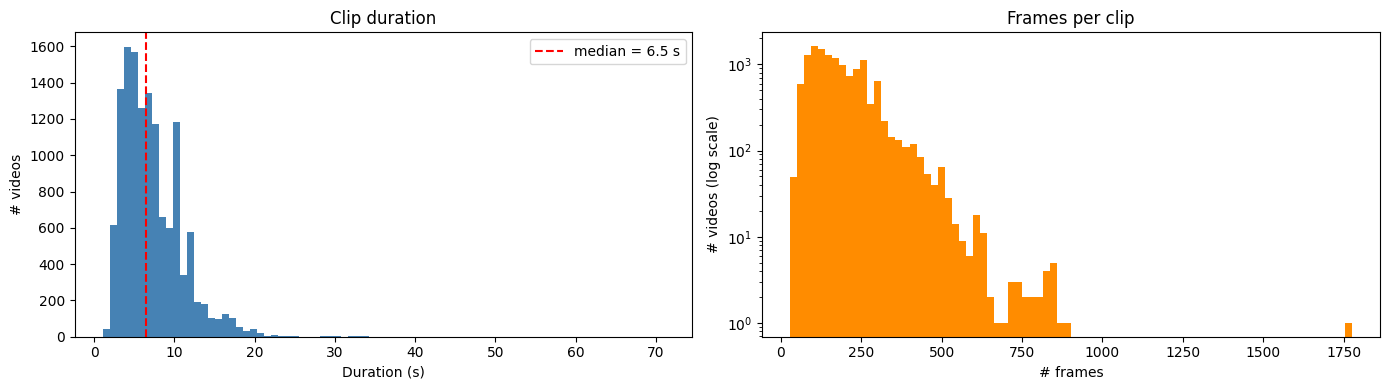

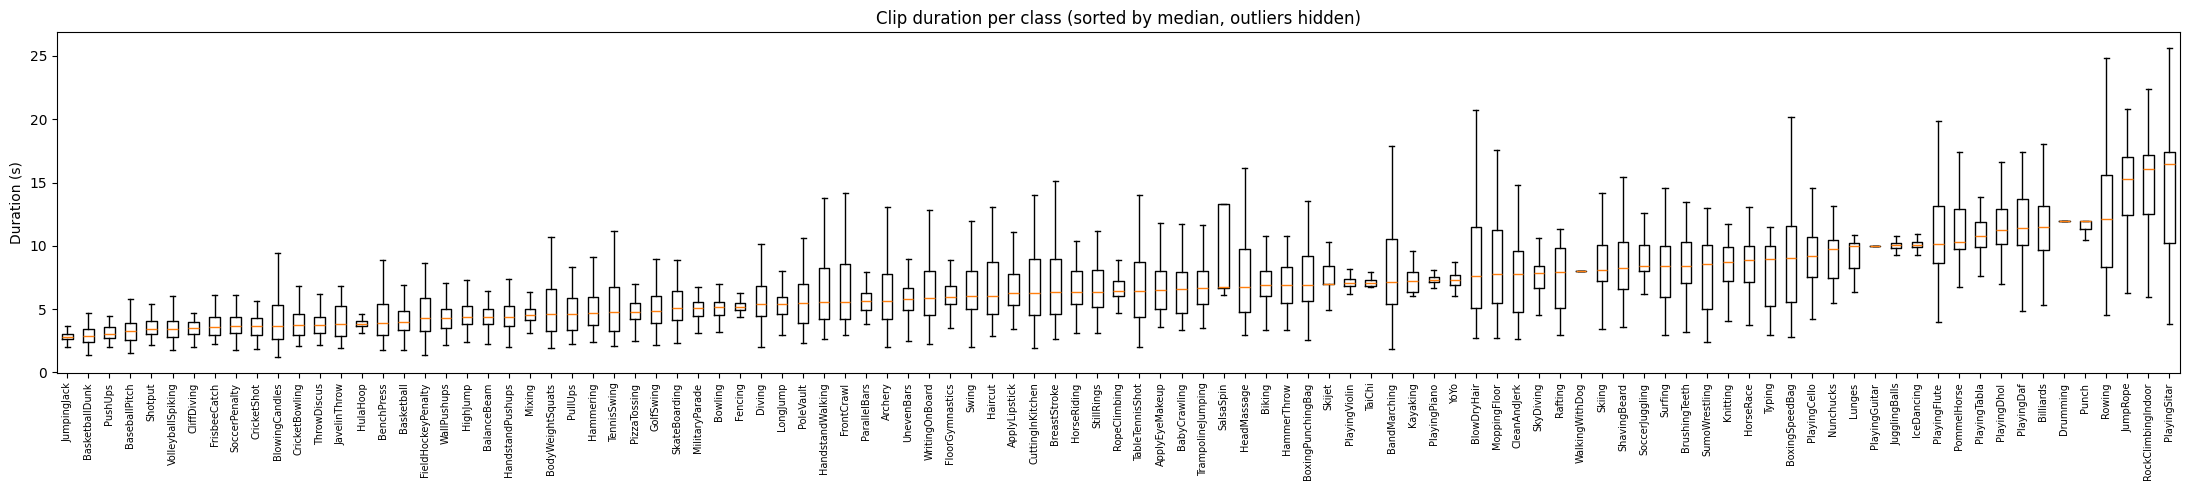

Shortest clip: 1.07s (29 frames) | Longest: 71.0s (1776 frames)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df.duration_s, bins=80, color='steelblue')
axes[0].axvline(df.duration_s.median(), color='red', ls='--',
                label=f'median = {df.duration_s.median():.1f} s')
axes[0].set(xlabel='Duration (s)', ylabel='# videos', title='Clip duration'); axes[0].legend()
axes[1].hist(df.n_frames, bins=80, color='darkorange', log=True)
axes[1].set(xlabel='# frames', ylabel='# videos (log scale)', title='Frames per clip')
plt.tight_layout(); save_fig('eda_duration'); plt.show()

# Per-class duration, sorted by median: do some actions come in systematically longer clips?
order = df.groupby('class_name').duration_s.median().sort_values().index
plt.figure(figsize=(22, 5))
plt.boxplot([df[df.class_name == c].duration_s for c in order], showfliers=False)
plt.xticks(range(1, len(order) + 1), order, rotation=90, fontsize=7)
plt.ylabel('Duration (s)'); plt.title('Clip duration per class (sorted by median, outliers hidden)')
plt.tight_layout(); save_fig('eda_duration_per_class'); plt.show()

print(f'Shortest clip: {df.duration_s.min():.2f}s ({df.n_frames.min()} frames) | '
      f'Longest: {df.duration_s.max():.1f}s ({df.n_frames.max()} frames)')

Test Header Frame Count

In [ ]:
SAMPLE_N = 40
sample = df.sample(SAMPLE_N, random_state=0).copy()

def decode_count(rel):
    """True frame count, obtained by decoding the whole video."""
    cap = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}'); n = 0
    while cap.grab():
        n += 1
    cap.release()
    return n

sample['decoded'] = [decode_count(r) for r in tqdm(sample.rel_path, desc='Full decode')]
sample['header_minus_decoded'] = sample.n_frames - sample.decoded
print('Header count minus decoded count (0 = header is exact):')
print(sample.header_minus_decoded.value_counts().sort_index().to_string())

Full decode:   0%|          | 0/40 [00:00<?, ?it/s]

Header count minus decoded count (0 = header is exact):
header_minus_decoded
0    37
1     2
3     1


In [ ]:
def seek_check(rel, n_frames, n_probe=6):
    """Compare frames obtained by seeking vs by sequential reading at the same indices."""
    path = f'{VIDEO_DIR}/{rel}'
    probes = sorted(set(np.linspace(0, n_frames - 1, n_probe, dtype=int).tolist()))

    cap, seq, i = cv2.VideoCapture(path), {}, 0          # ground truth: read straight through
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if i in probes:
            seq[i] = f
        i += 1
    cap.release()

    cap, errs = cv2.VideoCapture(path), []               # same frames via seeking
    for p in probes:
        cap.set(cv2.CAP_PROP_POS_FRAMES, p)
        ok, f = cap.read()
        if ok and p in seq:
            errs.append(float(np.abs(f.astype(np.int16) - seq[p].astype(np.int16)).mean()))
        else:
            errs.append(np.inf)                          # frame unreachable
    cap.release()
    return errs

errs = np.concatenate([seek_check(r, n) for r, n in
                       tqdm(zip(sample.rel_path, sample.n_frames), total=SAMPLE_N, desc='Seek test')])
print(f'Probed frames        : {len(errs)}')
print(f'Exact match (err<1)  : {(errs < 1).mean():.1%}')
print(f'Wrong frame (err>=1) : {((errs >= 1) & np.isfinite(errs)).mean():.1%}')
print(f'Unreachable          : {np.isinf(errs).mean():.1%}')

Seek test:   0%|          | 0/40 [00:00<?, ?it/s]

Probed frames        : 240
Exact match (err<1)  : 95.8%
Wrong frame (err>=1) : 2.9%
Unreachable          : 1.2%


In [ ]:
# Speed: seek-based sampling (the assignment's approach) vs one sequential pass
T = 16

def sample_by_seek(rel, n_frames):
    cap = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}')
    for idx in np.linspace(0, n_frames - 1, T, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); cap.read()
    cap.release()

def sample_sequential(rel, n_frames):
    keep = set(np.linspace(0, n_frames - 1, T, dtype=int).tolist())
    cap, i = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}'), 0
    while cap.grab():
        if i in keep:
            cap.retrieve()
        i += 1
    cap.release()

timing = {}
for name, fn in [('seek', sample_by_seek), ('sequential', sample_sequential)]:
    t0 = time.perf_counter()
    for r, n in zip(sample.rel_path, sample.n_frames):
        fn(r, n)
    timing[name] = (time.perf_counter() - t0) / SAMPLE_N

n_train = (manifest.split == 'train').sum()
for name, sec in timing.items():
    print(f'{name:>10}: {sec*1000:6.1f} ms/clip -> ~{sec*n_train/60:5.1f} min of pure decoding per epoch (full train set)')

      seek:  120.2 ms/clip -> ~ 19.1 min of pure decoding per epoch (full train set)
sequential:   28.7 ms/clip -> ~  4.6 min of pure decoding per epoch (full train set)


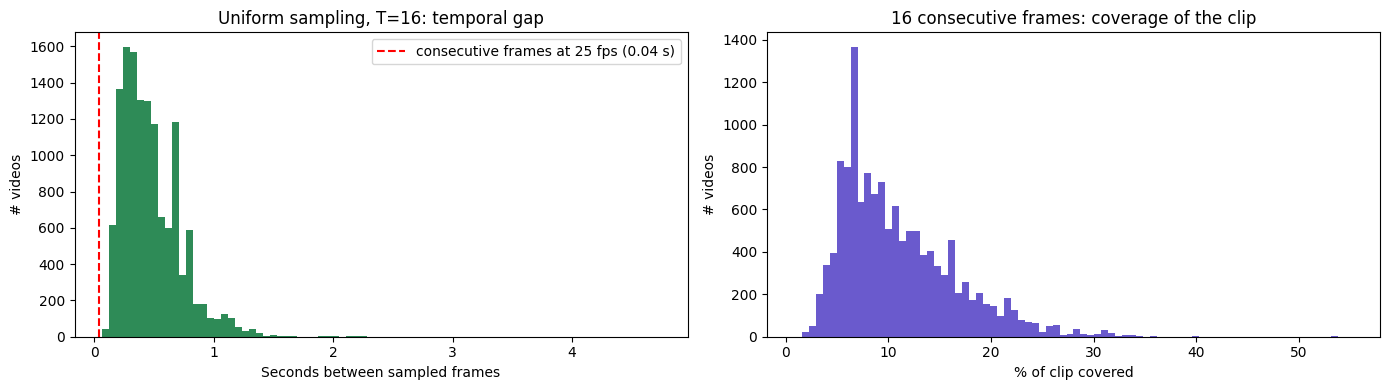

Uniform sampling gap (s): p10=0.214, median=0.429, p90=0.797
Median coverage with 16 consecutive frames: 9.6%
Clips shorter than 16 frames: 0
Clips shorter than 32 frames: 3
Clips shorter than 64 frames: 282


In [ ]:
T = 16
df['uniform_gap_s']   = (df.n_frames - 1) / (T - 1) / df.fps     # time between sampled frames
df['consec_coverage'] = np.minimum(T / df.n_frames, 1.0)          # fraction of clip seen

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df.uniform_gap_s, bins=80, color='seagreen')
axes[0].axvline(1 / 25, color='red', ls='--', label='consecutive frames at 25 fps (0.04 s)')
axes[0].set(xlabel='Seconds between sampled frames', ylabel='# videos',
            title=f'Uniform sampling, T={T}: temporal gap'); axes[0].legend()
axes[1].hist(df.consec_coverage * 100, bins=80, color='slateblue')
axes[1].set(xlabel='% of clip covered', ylabel='# videos',
            title=f'{T} consecutive frames: coverage of the clip')
plt.tight_layout(); save_fig('eda_sampling_tradeoff'); plt.show()

q = df.uniform_gap_s.quantile([.1, .5, .9]).round(3)
print(f'Uniform sampling gap (s): p10={q[.1]}, median={q[.5]}, p90={q[.9]}')
print(f'Median coverage with {T} consecutive frames: {df.consec_coverage.median():.1%}')
for t in (16, 32, 64):
    print(f'Clips shorter than {t:>2} frames: {(df.n_frames < t).sum()}')

Class balance and group structure

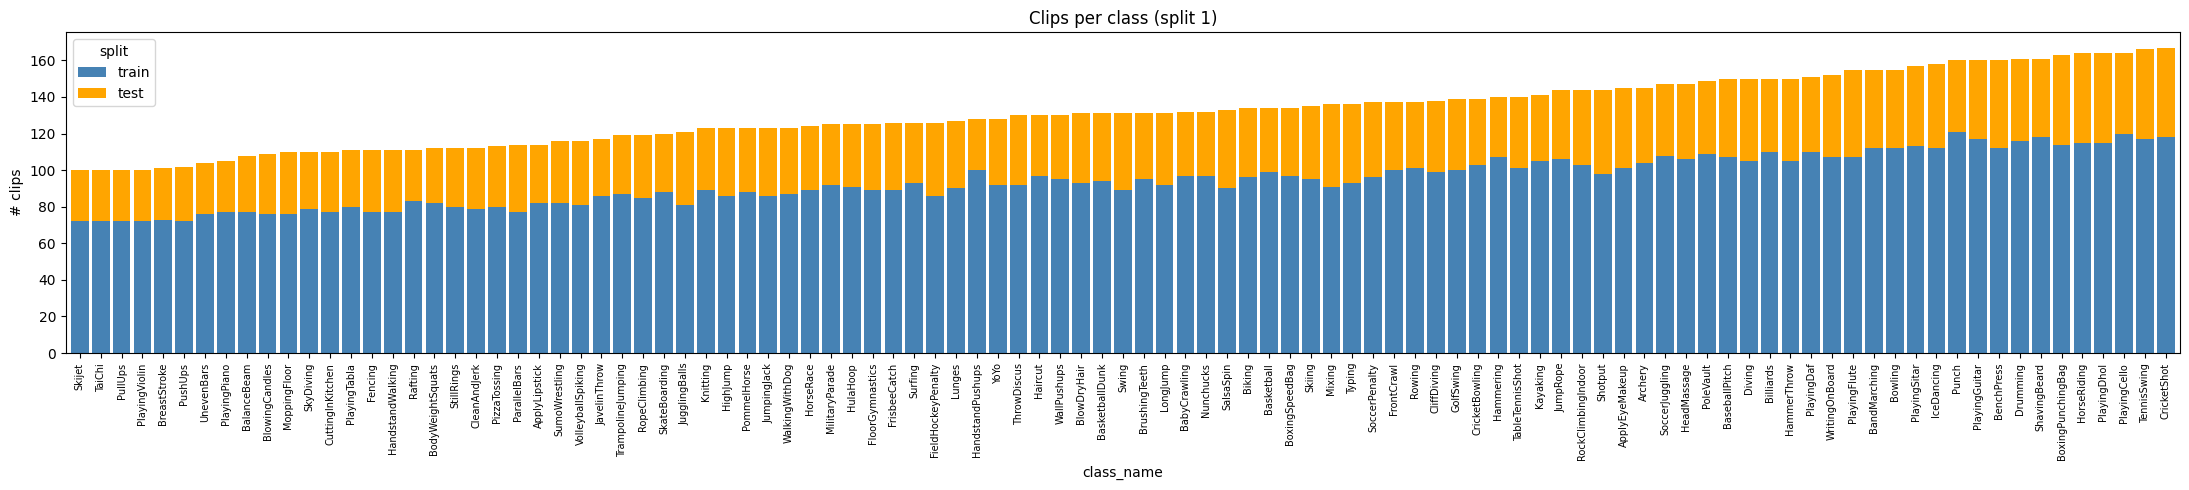

Clips per class: min=100, max=167, ratio=1.67
Test fraction per class: 0.22 - 0.33

Clips per (class, group): mean=5.3, min=4, max=7
Independent source videos per class in train: 18 (median)


In [ ]:
counts = df.pivot_table(index='class_name', columns='split', values='rel_path', aggfunc='count').fillna(0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
counts[['train', 'test']].plot.bar(stacked=True, figsize=(22, 5), width=0.85, color=['steelblue', 'orange'])
plt.ylabel('# clips'); plt.title('Clips per class (split 1)'); plt.xticks(fontsize=7)
plt.tight_layout(); save_fig('eda_class_balance'); plt.show()

tot = counts.sum(axis=1)
print(f'Clips per class: min={tot.min():.0f}, max={tot.max():.0f}, ratio={tot.max()/tot.min():.2f}')
print(f'Test fraction per class: {(counts.test / tot).min():.2f} - {(counts.test / tot).max():.2f}')

clips_per_group = df.groupby(['class_name', 'group']).size()
print(f'\nClips per (class, group): mean={clips_per_group.mean():.1f}, '
      f'min={clips_per_group.min()}, max={clips_per_group.max()}')
print(f'Independent source videos per class in train: '
      f'{df[df.split=="train"].groupby("class_name").group.nunique().median():.0f} (median)')

Viewing the data - clip shown as 8 uniformly sampled frames

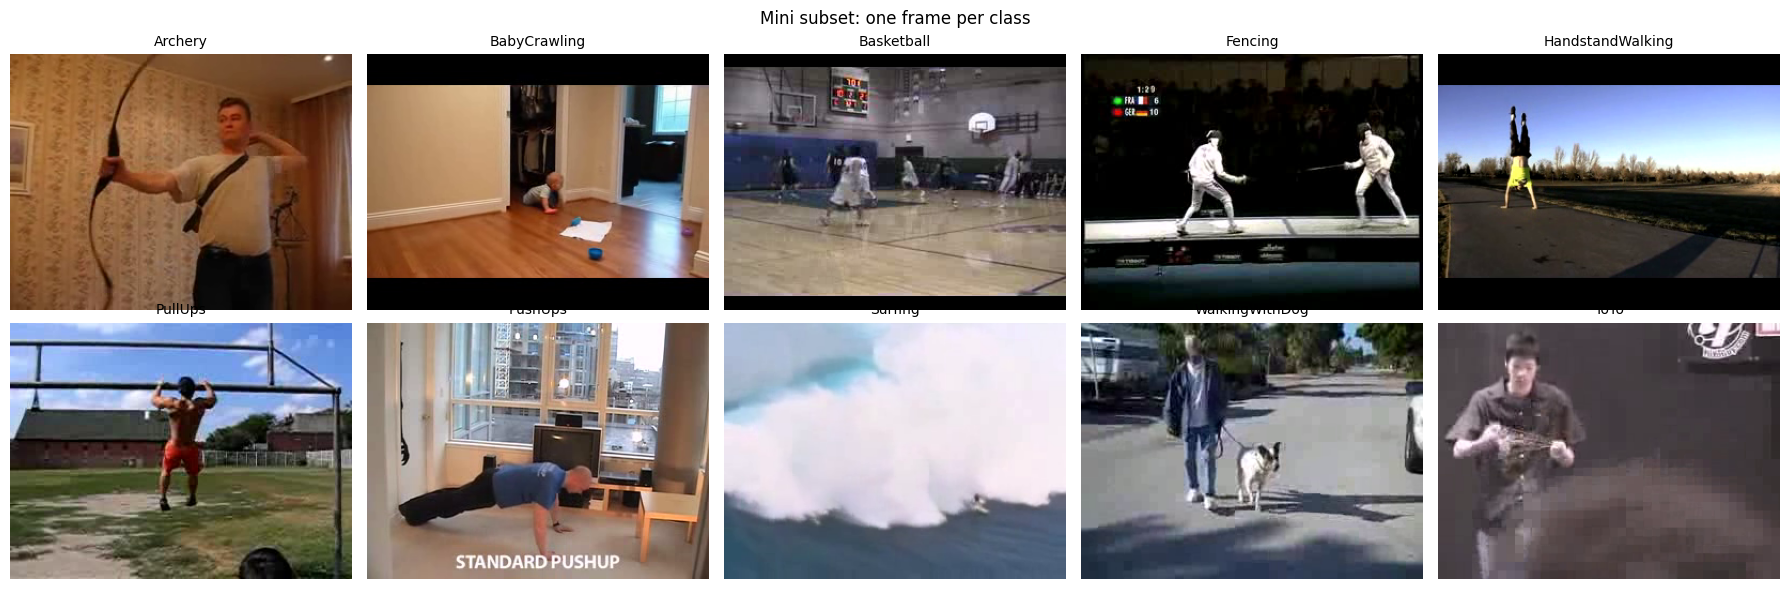

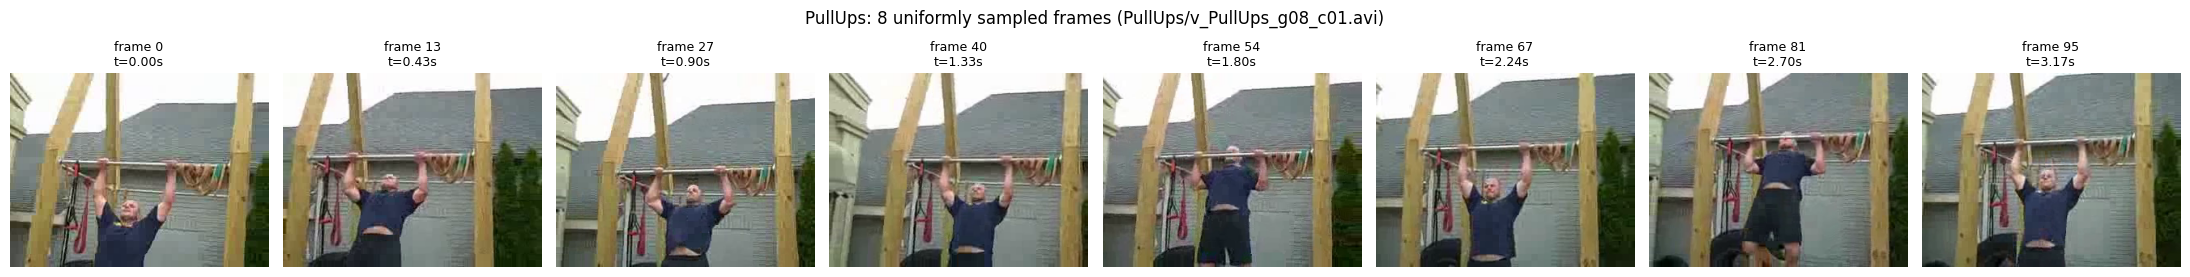

In [ ]:
def read_frames(rel, indices):
    """Read the requested frame indices (RGB) with a single sequential pass."""
    want, out = sorted(set(int(i) for i in indices)), {}
    cap, i = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}'), 0
    while len(out) < len(want) and cap.grab():
        if i in want:
            ok, f = cap.retrieve()
            if ok:
                out[i] = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    return [out[i] for i in want if i in out]

# (a) One middle frame from a random training clip of each mini class
mini_meta = df[df.rel_path.isin(mini.rel_path)]
picks = mini_meta[mini_meta.split == 'train'].groupby('class_name').sample(1, random_state=1)
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, (_, row) in zip(axes.flat, picks.iterrows()):
    ax.imshow(read_frames(row.rel_path, [row.n_frames // 2])[0])
    ax.set_title(row.class_name, fontsize=10); ax.axis('off')
plt.suptitle('Mini subset: one frame per class'); plt.tight_layout()
save_fig('eda_mini_class_montage'); plt.show()

# (b) Exercise 4: one clip as 8 uniformly sampled frames
row = mini_meta[mini_meta.class_name == 'PullUps'].iloc[0]
idx = np.linspace(0, row.n_frames - 1, 8, dtype=int)
fig, axes = plt.subplots(1, 8, figsize=(22, 3))
for ax, frame, i in zip(axes, read_frames(row.rel_path, idx), idx):
    ax.imshow(frame); ax.set_title(f'frame {i}\nt={i / row.fps:.2f}s', fontsize=9); ax.axis('off')
plt.suptitle(f'{row.class_name}: 8 uniformly sampled frames ({row.rel_path})')
plt.tight_layout(); save_fig('part1_ex4_frame_sampling'); plt.show()

Motion probe:   0%|          | 0/80 [00:00<?, ?it/s]

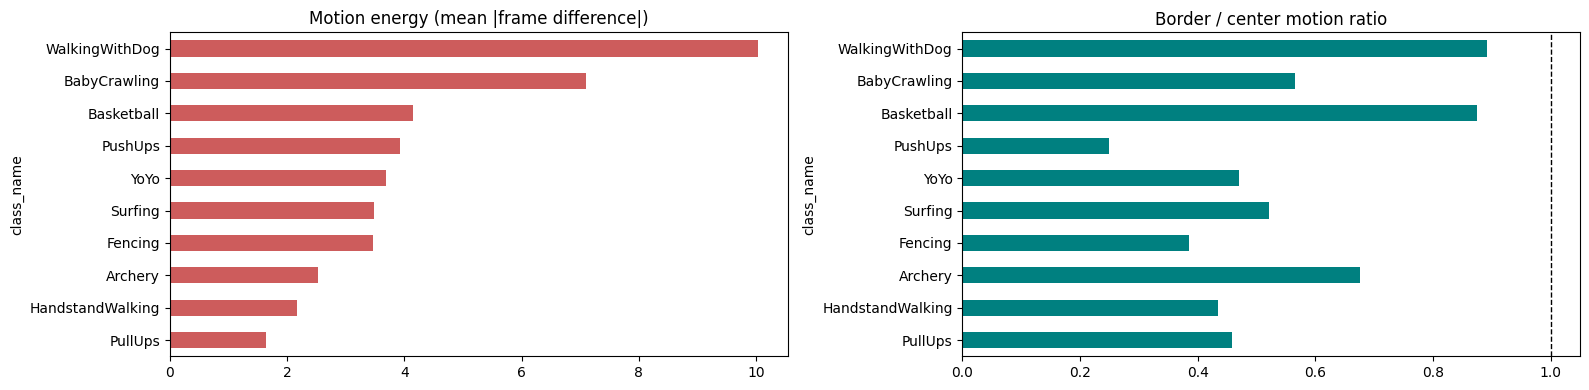

,energy,border_center
class_name,,
PullUps,1.64,0.46
HandstandWalking,2.16,0.43
Archery,2.53,0.68
Fencing,3.46,0.39
Surfing,3.49,0.52
YoYo,3.69,0.47
PushUps,3.93,0.25
Basketball,4.15,0.88
BabyCrawling,7.10,0.57


In [ ]:
def motion_probe(rel, n_frames, n=24, size=(160, 120)):
    start = max(0, n_frames // 2 - n // 2)
    frames = read_frames(rel, range(start, min(start + n, n_frames)))
    gray = np.stack([cv2.resize(cv2.cvtColor(f, cv2.COLOR_RGB2GRAY), size).astype(np.float32)
                     for f in frames])
    diffs = np.abs(np.diff(gray, axis=0))                     # (n-1, H, W)
    H, W = diffs.shape[1:]
    center = np.zeros((H, W), bool)
    center[H // 4: 3 * H // 4, W // 4: 3 * W // 4] = True
    return diffs.mean(), diffs[:, ~center].mean() / (diffs[:, center].mean() + 1e-6)

probe_set = (mini_meta[mini_meta.split == 'train'].sample(frac=1, random_state=0)
             .groupby('class_name').head(8))                      # up to 8 clips per class
rows = []
for r in tqdm(probe_set.itertuples(), total=len(probe_set), desc='Motion probe'):
    energy, ratio = motion_probe(r.rel_path, r.n_frames)
    rows.append(dict(class_name=r.class_name, energy=energy, border_center=ratio))
probe = pd.DataFrame(rows)
summary = probe.groupby('class_name')[['energy', 'border_center']].mean().sort_values('energy')

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
summary.energy.plot.barh(ax=axes[0], color='indianred', title='Motion energy (mean |frame difference|)')
summary.border_center.plot.barh(ax=axes[1], color='teal', title='Border / center motion ratio')
axes[1].axvline(1.0, color='k', ls='--', lw=1)
plt.tight_layout(); save_fig('eda_motion_probe'); plt.show()
summary.round(2)

In [ ]:
rows = []
for T_ in (16, 32):
    for (h, w) in ((112, 112), (128, 171)):
        per_clip = T_ * h * w * 3                         # bytes, uint8 RGB
        rows.append(dict(T=T_, resolution=f'{h}x{w}', MB_per_clip=per_clip / 1e6,
                         mini_GB=per_clip * len(mini) / 1e9, full_GB=per_clip * len(manifest) / 1e9))
storage = pd.DataFrame(rows).round(2)
print(f'Free local disk: {shutil.disk_usage("/content").free / 1e9:.0f} GB')
storage

Free local disk: 186 GB


,T,resolution,MB_per_clip,mini_GB,full_GB
0,16,112x112,0.60,0.73,8.02
1,16,128x171,1.05,1.27,13.99
2,32,112x112,1.20,1.46,16.04
3,32,128x171,2.10,2.55,27.99


In [ ]:
df.to_csv(f'{DRIVE_META}/manifest_with_meta.csv', index=False)

print('=== EDA summary ===')
print(f'Videos: {len(df)} | classes: {df.class_name.nunique()}')
print(f'Resolution: {res.index[0]} ({res.iloc[0] / len(df):.1%}) | FPS mode: {df.fps.mode()[0]}')
print(f'Duration: median {df.duration_s.median():.1f}s, range {df.duration_s.min():.1f}-{df.duration_s.max():.1f}s')
print(f'Header frame count exact in {(sample.header_minus_decoded == 0).mean():.0%} of sampled clips')
print(f'Seek exact in {(errs < 1).mean():.0%} of probes | seek {timing["seek"]*1000:.0f} ms vs '
      f'sequential {timing["sequential"]*1000:.0f} ms per clip')
print(f'Uniform T=16 gap: median {df.uniform_gap_s.median():.2f}s between sampled frames')
print('Figures saved to:', DRIVE_FIG)

=== EDA summary ===
Videos: 13320 | classes: 101
Resolution: 320x240 (100.0%) | FPS mode: 25.0
Duration: median 6.5s, range 1.1-71.0s
Header frame count exact in 92% of sampled clips
Seek exact in 96% of probes | seek 120 ms vs sequential 29 ms per clip
Uniform T=16 gap: median 0.43s between sampled frames
Figures saved to: /content/drive/MyDrive/videosense/figures


Step 3 — Preprocessing: splits, frame cache, transforms, and the PyTorch Dataset

In [ ]:
import os, sys, random, subprocess, shutil, time
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

SUBSET = 'mini'
T          = 16            # frames per clip fed to the model
CACHE_K    = 32            # frames stored per clip (> T, so training can jitter frame choice)
CACHE_H, CACHE_W = 128, 171   # aspect-preserving 4:3 size (C3D paper convention)
CROP       = 112
JPEG_Q     = 90
SEED       = 42

CACHE_NAME  = f'frames_k{CACHE_K}_{CACHE_H}x{CACHE_W}_q{JPEG_Q}'
LOCAL_CACHE = f'{LOCAL_DATA}/{CACHE_NAME}'
DRIVE_CACHE = f'{DRIVE_ROOT}/cache'
CODE_DIR    = f'{DRIVE_ROOT}/code'
for d in [LOCAL_CACHE, DRIVE_CACHE, f'{CODE_DIR}/utils', f'{CODE_DIR}/models']:
    os.makedirs(d, exist_ok=True)
for pkg in ['utils', 'models']:
    open(f'{CODE_DIR}/{pkg}/__init__.py', 'a').close()

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print('Subset:', SUBSET, '| cache:', CACHE_NAME, '| CPUs:', os.cpu_count())

Subset: mini | cache: frames_k32_128x171_q90 | CPUs: 2


Train / validation / test split — by group

In [ ]:
VAL_GROUPS = {8, 9, 10}

meta_cols = pd.read_csv(f'{DRIVE_META}/manifest_with_meta.csv')[['rel_path', 'n_frames', 'fps']]
full = pd.read_csv(f'{DRIVE_META}/manifest_full.csv').merge(meta_cols, on='rel_path', how='left')
mini = pd.read_csv(f'{DRIVE_META}/manifest_mini.csv').merge(meta_cols, on='rel_path', how='left')

def add_phase(m):
    m = m.copy()
    m['phase'] = np.where(m.split == 'test', 'test',
                          np.where(m.group.isin(VAL_GROUPS), 'val', 'train'))
    for cls, d in m.groupby('class_name'):          # no group may appear in two phases
        g = {p: set(d[d.phase == p].group) for p in ('train', 'val', 'test')}
        assert not (g['train'] & g['val'] or g['train'] & g['test'] or g['val'] & g['test']), cls
    return m

full, mini = add_phase(full), add_phase(mini)
full.to_csv(f'{DRIVE_META}/splits_full.csv', index=False)
mini.to_csv(f'{DRIVE_META}/splits_mini.csv', index=False)

data = mini if SUBSET == 'mini' else full
print(data.phase.value_counts().to_string())
print('\nPer class (first 5):')
print(data.groupby(['class_name', 'phase']).size().unstack().head().to_string())

phase
train    721
test     342
val      149

Per class (first 5):
phase             test  train  val
class_name                        
Archery             41     85   19
BabyCrawling        35     82   15
Basketball          35     85   14
Fencing             34     62   15
HandstandWalking    34     65   12


K=32 frames sampled uniformly over the whole clip, resized to 128×171, each JPEG-encoded, packed into one .npz (all bytes + offsets).

In [ ]:
def cache_path(rel):
    return f'{LOCAL_CACHE}/{rel[:-4]}.npz'

def cache_indices(n_frames, k=CACHE_K):
    return np.linspace(0, max(int(n_frames) - 1, 0), k).round().astype(int)

def read_resized(rel, indices):
    """Sequentially decode only the requested frames (BGR, resized)."""
    want, got = set(int(i) for i in indices), {}
    cap, i = cv2.VideoCapture(f'{VIDEO_DIR}/{rel}'), 0
    while len(got) < len(want) and cap.grab():
        if i in want:
            ok, f = cap.retrieve()
            if ok:
                got[i] = cv2.resize(f, (CACHE_W, CACHE_H), interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    return got

def build_clip_cache(rel, n_frames):
    out = cache_path(rel)
    if os.path.exists(out):
        return 'skip'
    idx = cache_indices(n_frames)
    got = read_resized(rel, idx)
    if not got:
        return 'fail'
    avail = np.array(sorted(got))
    frames = [got[avail[np.abs(avail - j).argmin()]] for j in idx]     # nearest decoded frame
    jpgs = [cv2.imencode('.jpg', f, [cv2.IMWRITE_JPEG_QUALITY, JPEG_Q])[1].ravel() for f in frames]
    offsets = np.concatenate([[0], np.cumsum([len(j) for j in jpgs])])
    os.makedirs(os.path.dirname(out), exist_ok=True)
    tmp = out + '.tmp'
    with open(tmp, 'wb') as fh:
        np.savez(fh, data=np.concatenate(jpgs), offsets=offsets, src_idx=idx)
    os.replace(tmp, out)                                               # atomic
    return 'ok' if len(got) == len(set(idx.tolist())) else 'ok_padded'

def load_cached(path, which=None):
    """Decode cached frames -> (n, H, W, 3) uint8 RGB."""
    z = np.load(path)
    data, off = z['data'], z['offsets']
    which = range(len(off) - 1) if which is None else which
    return np.stack([cv2.cvtColor(cv2.imdecode(data[off[i]:off[i + 1]], cv2.IMREAD_COLOR),
                                  cv2.COLOR_BGR2RGB) for i in which])

# --- test on one clip
row = data[data.phase == 'train'].iloc[0]
print(build_clip_cache(row.rel_path, row.n_frames), '->', cache_path(row.rel_path))
cached = load_cached(cache_path(row.rel_path))
raw = read_resized(row.rel_path, cache_indices(row.n_frames))
raw = np.stack([cv2.cvtColor(raw[i], cv2.COLOR_BGR2RGB) for i in cache_indices(row.n_frames) if i in raw])
mse = ((cached[:len(raw)].astype(np.float64) - raw) ** 2).mean()
size_kb = os.path.getsize(cache_path(row.rel_path)) / 1e3
raw_kb = CACHE_K * CACHE_H * CACHE_W * 3 / 1e3
print(f'Cached shape: {cached.shape} | file {size_kb:.0f} KB vs raw {raw_kb:.0f} KB '
      f'({raw_kb / size_kb:.1f}x smaller) | PSNR {10 * np.log10(255**2 / max(mse, 1e-9)):.1f} dB')

ok -> /content/videosense/data/frames_k32_128x171_q90/Archery/v_Archery_g11_c01.npz
Cached shape: (32, 128, 171, 3) | file 313 KB vs raw 2101 KB (6.7x smaller) | PSNR 36.6 dB


 Build the cache for the whole subset

In [ ]:
CACHE_TAR = f'{DRIVE_CACHE}/{CACHE_NAME}_{SUBSET}.tar'

def n_cached():
    return sum(os.path.exists(cache_path(r)) for r in data.rel_path)

if n_cached() < len(data) and os.path.exists(CACHE_TAR):
    print('Restoring cache from Drive...')
    subprocess.run(['tar', '-xf', CACHE_TAR, '-C', LOCAL_DATA], check=True)

todo = [(r, n) for r, n in zip(data.rel_path, data.n_frames) if not os.path.exists(cache_path(r))]
print(f'{len(data) - len(todo)} cached, {len(todo)} to build')
if todo:
    t0 = time.perf_counter()
    with ThreadPoolExecutor(max_workers=min(8, 2 * os.cpu_count())) as ex:
        status = list(tqdm(ex.map(lambda a: build_clip_cache(*a), todo), total=len(todo), desc='Caching'))
    el = time.perf_counter() - t0
    print(pd.Series(status).value_counts().to_string())
    print(f'Built {len(todo)} clips in {el / 60:.1f} min ({el / len(todo) * 1000:.0f} ms/clip)')
    subprocess.run(['tar', '-cf', CACHE_TAR, '-C', LOCAL_DATA, CACHE_NAME], check=True)
    print(f'Backed up to {CACHE_TAR} ({os.path.getsize(CACHE_TAR) / 1e9:.2f} GB)')

missing = [r for r in data.rel_path if not os.path.exists(cache_path(r))]
assert not missing, f'{len(missing)} clips failed to cache, e.g. {missing[:3]}'
print(f' All {len(data)} clips cached')

Restoring cache from Drive...
1212 cached, 0 to build
 All 1212 clips cached


Normalizing inputs to roughly zero mean and unit variance per channel

In [ ]:
stat_rows = data[data.phase == 'train'].sample(min(200, (data.phase == 'train').sum()), random_state=SEED)
pix = np.concatenate([load_cached(cache_path(r), which=[0, 10, 21, 31]).reshape(-1, 3)
                      for r in tqdm(stat_rows.rel_path, desc='Stats')]).astype(np.float64) / 255
ucf_mean, ucf_std = pix.mean(0), pix.std(0)

stats = pd.DataFrame({'UCF101 (measured)': [*ucf_mean, *ucf_std],
                      'ImageNet': [0.485, 0.456, 0.406, 0.229, 0.224, 0.225],
                      'Kinetics': [0.43216, 0.394666, 0.37645, 0.22803, 0.22145, 0.216989]},
                     index=['mean_R', 'mean_G', 'mean_B', 'std_R', 'std_G', 'std_B']).round(3)
stats

Stats:   0%|          | 0/200 [00:00<?, ?it/s]

,UCF101 (measured),ImageNet,Kinetics
mean_R,0.389,0.485,0.432
mean_G,0.383,0.456,0.395
mean_B,0.361,0.406,0.376
std_R,0.277,0.229,0.228
std_G,0.274,0.224,0.221
std_B,0.285,0.225,0.217


Write utils/dataset.py: segment sampling, clip-consistent augmentation, normalization

Step 7 adds `PairDataset` (Section 7.4) and `TripletDataset` (Exercise 17) at the end of this file.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/utils/dataset.py
"""VideoSense datasets: cached-frame loading, segment sampling, clip-consistent augmentation."""
import os
import random

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

NORM_STATS = {
    'imagenet': ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),           # C3D from scratch
    'kinetics': ([0.43216, 0.394666, 0.37645], [0.22803, 0.22145, 0.216989]),  # torchvision video models
}


def decode_frames(data, offsets, which):
    """Decode selected JPEG frames from packed bytes -> (n, H, W, 3) uint8 RGB."""
    return np.stack([cv2.cvtColor(cv2.imdecode(data[offsets[i]:offsets[i + 1]], cv2.IMREAD_COLOR),
                                  cv2.COLOR_BGR2RGB) for i in which])


def load_cached_frames(path, which=None):
    """Decode frames of a cached clip (all frames if which is None)."""
    z = np.load(path)
    data, off = z['data'], z['offsets']
    return decode_frames(data, off, range(len(off) - 1) if which is None else which)


def segment_indices(k, t, train):
    """Pick t of k stored frames: one per equal-width segment.

    train=True  -> random frame inside each segment (temporal augmentation)
    train=False -> fixed frame per segment (deterministic evaluation)
    """
    edges = np.linspace(0, k, t + 1)
    lo = np.floor(edges[:-1]).astype(int)
    hi = np.maximum(np.floor(edges[1:]).astype(int), lo + 1)
    if train:
        return [random.randrange(a, b) for a, b in zip(lo, hi)]
    return ((lo + hi - 1) // 2).tolist()


class ClipTransform:
    """Spatial crop + optional horizontal flip, identical for every frame of a clip."""

    def __init__(self, crop=112, train=False, hflip_p=0.5):
        self.crop, self.train, self.hflip_p = crop, train, hflip_p

    def sample_params(self, h, w):
        c = self.crop
        if self.train:
            return {'y': random.randint(0, h - c), 'x': random.randint(0, w - c),
                    'flip': random.random() < self.hflip_p}
        return {'y': (h - c) // 2, 'x': (w - c) // 2, 'flip': False}

    def __call__(self, frames, params=None):
        """frames: (T, H, W, C) array. Returns (cropped frames, params used)."""
        params = params or self.sample_params(*frames.shape[1:3])
        y, x, c = params['y'], params['x'], self.crop
        out = frames[:, y:y + c, x:x + c]
        if params['flip']:
            out = out[:, :, ::-1]
        return np.ascontiguousarray(out), params


def to_normalized_tensor(frames, norm='imagenet'):
    """(T, H, W, 3) uint8 -> (3, T, H, W) float32, channel-normalized."""
    mean, std = (torch.tensor(v).view(3, 1, 1, 1) for v in NORM_STATS[norm])
    x = torch.from_numpy(frames).permute(3, 0, 1, 2).float().div_(255.0)
    return (x - mean) / std


def denormalize(clip, norm='imagenet'):
    """(3, T, H, W) normalized tensor -> (T, H, W, 3) float array in [0, 1] for plotting."""
    mean, std = (torch.tensor(v).view(3, 1, 1, 1) for v in NORM_STATS[norm])
    return (clip * std + mean).clamp(0, 1).permute(1, 2, 3, 0).numpy()


class UCF101Clips(Dataset):
    """RGB clips from the frame cache.

    df        : manifest rows with columns rel_path, label
    cache_dir : folder with <Class>/<video>.npz files
    Returns   : (clip (3, T, crop, crop) float32, label int)
    """

    def __init__(self, df, cache_dir, num_frames=16, train=False, crop=112, norm='imagenet'):
        self.df = df.reset_index(drop=True)
        self.cache_dir, self.num_frames, self.train, self.norm = cache_dir, num_frames, train, norm
        self.transform = ClipTransform(crop=crop, train=train)
        self.labels = self.df.label.astype(int).tolist()
        self.samples = list(zip(self.df.rel_path, self.labels))      # assignment-compatible
        self.class_names = (self.df.drop_duplicates('label').sort_values('label').class_name.tolist())

    def __len__(self):
        return len(self.df)

    def path(self, i):
        return os.path.join(self.cache_dir, self.df.rel_path[i][:-4] + '.npz')

    def get(self, i):
        """Full output: clip, label, and the sampling/transform parameters used."""
        z = np.load(self.path(i))                      # one file read per clip
        data, off = z['data'], z['offsets']
        which = segment_indices(len(off) - 1, self.num_frames, self.train)
        frames, params = self.transform(decode_frames(data, off, which))
        params['frame_idx'] = which
        return to_normalized_tensor(frames, self.norm), self.labels[i], params

    def __getitem__(self, i):
        clip, label, _ = self.get(i)
        return clip, label


class PairDataset(Dataset):
    """Random clip pairs for the Siamese network (Section 7.4).

    Returns (x1, x2, y) with y = 0 for the same action class (positive pair) and
    y = 1 for different classes (negative pair). pos_fraction = 0.5 is the assignment's
    50/50 balance; Reflection Q19 uses 0.1. Each clip goes through the base dataset,
    so training pairs get the usual augmentation.
    """

    def __init__(self, base_dataset, pairs_per_epoch=10000, pos_fraction=0.5):
        self.ds, self.pairs_per_epoch, self.pos_fraction = base_dataset, pairs_per_epoch, pos_fraction
        self.class_idx = {}
        for i, (_, lbl) in enumerate(self.ds.samples):
            self.class_idx.setdefault(lbl, []).append(i)
        self.classes = sorted(self.class_idx)

    def __len__(self):
        return self.pairs_per_epoch

    def __getitem__(self, _):
        if random.random() < self.pos_fraction:
            cls = random.choice(self.classes)
            i1, i2 = random.sample(self.class_idx[cls], 2)
            label = 0
        else:
            cls1, cls2 = random.sample(self.classes, 2)
            i1, i2 = random.choice(self.class_idx[cls1]), random.choice(self.class_idx[cls2])
            label = 1
        x1, _ = self.ds[i1]
        x2, _ = self.ds[i2]
        return x1, x2, torch.tensor(label, dtype=torch.float32)


class TripletDataset(PairDataset):
    """Random (anchor, positive, negative) clips for triplet loss (Exercise 17)."""

    def __getitem__(self, _):
        cls, other = random.sample(self.classes, 2)
        ia, ip = random.sample(self.class_idx[cls], 2)
        ineg = random.choice(self.class_idx[other])
        return self.ds[ia][0], self.ds[ip][0], self.ds[ineg][0]


Overwriting /content/drive/MyDrive/videosense/code/utils/dataset.py


Sanity checks — shapes, values, labels, and augmentation

In [ ]:
import importlib
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
import utils.dataset as vds
importlib.reload(vds)

phase_df = {p: data[data.phase == p] for p in ('train', 'val', 'test')}
ds = {p: vds.UCF101Clips(d, LOCAL_CACHE, num_frames=T, train=(p == 'train'), crop=CROP, norm='imagenet')
      for p, d in phase_df.items()}
n_classes = data.label.nunique()

for p, d in ds.items():
    clip, label = d[0]
    print(f'{p:>5}: {len(d):5d} clips | clip {tuple(clip.shape)} {clip.dtype} | '
          f'range [{clip.min():.2f}, {clip.max():.2f}] | label {label}')

clip, _ = ds['train'][0]
assert clip.shape == (3, T, CROP, CROP) and clip.dtype == torch.float32
assert torch.isfinite(clip).all()
assert set(data.label) == set(range(n_classes)), 'labels must be 0..C-1'

# Determinism: eval must give identical tensors every call; train should not
assert torch.equal(ds['val'][0][0], ds['val'][0][0]), 'val is not deterministic!'
print('Train calls differ (augmentation active):', not torch.equal(ds['train'][0][0], ds['train'][0][0]))

# Normalization check over a few clips: mean should be near 0, std near 1
batch = torch.stack([ds['val'][i][0] for i in range(min(16, len(ds['val'])))])
print('Per-channel mean:', batch.mean(dim=(0, 2, 3, 4)).numpy().round(2),
      '| std:', batch.std(dim=(0, 2, 3, 4)).numpy().round(2))
print('Dataset checks passed')

train:   721 clips | clip (3, 16, 112, 112) torch.float32 | range [-2.12, 2.64] | label 0
  val:   149 clips | clip (3, 16, 112, 112) torch.float32 | range [-1.34, 2.64] | label 0
 test:   342 clips | clip (3, 16, 112, 112) torch.float32 | range [-2.12, 2.38] | label 0
Train calls differ (augmentation active): True
Per-channel mean: [0.33 0.34 0.42] | std: [0.98 1.   1.09]
Dataset checks passed


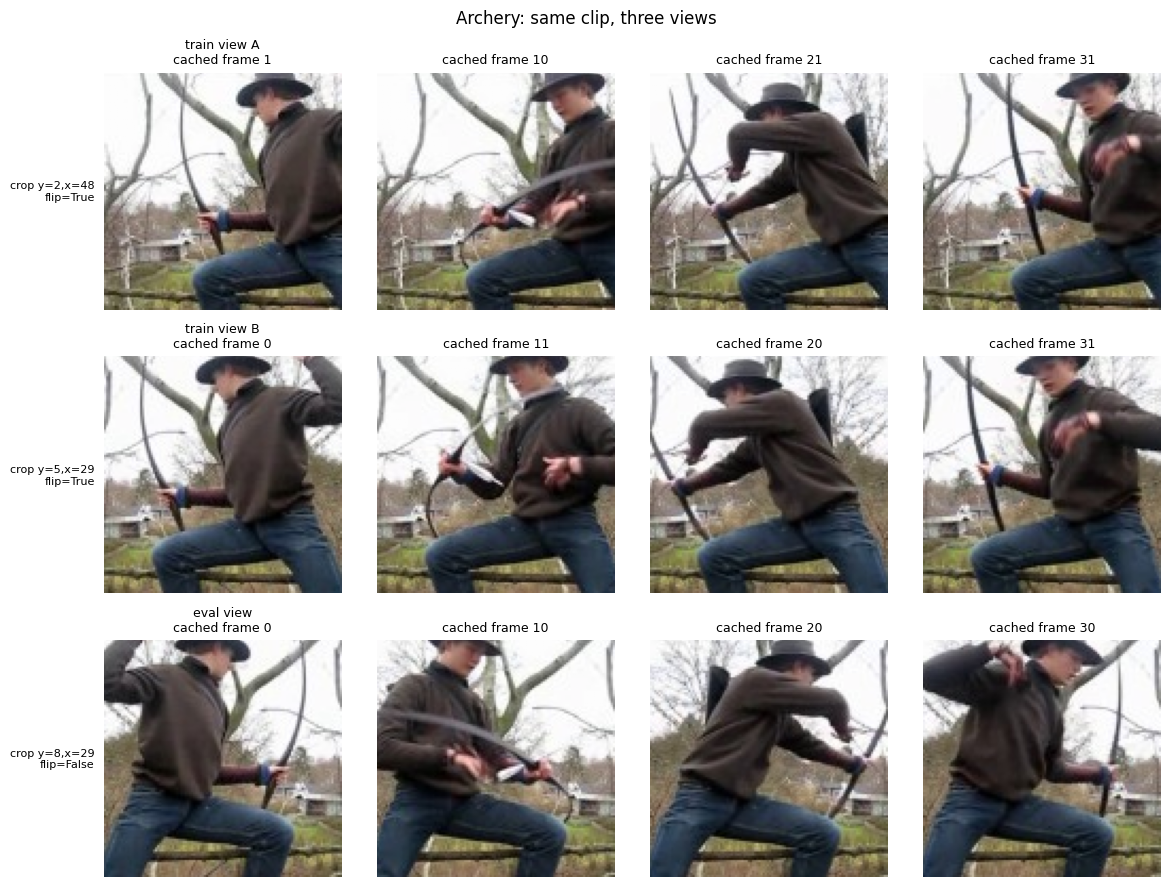

In [ ]:
#  two training augmentations vs the deterministic eval view of the same clip
i = 0
views = [('train view A', *ds['train'].get(i)), ('train view B', *ds['train'].get(i))]
eval_ds = vds.UCF101Clips(phase_df['train'], LOCAL_CACHE, num_frames=T, train=False, crop=CROP)
views.append(('eval view', *eval_ds.get(i)))

show_t = [0, 5, 10, 15]
fig, axes = plt.subplots(len(views), len(show_t), figsize=(12, 9))
for r, (name, clip, label, params) in enumerate(views):
    frames = vds.denormalize(clip)
    for c, t in enumerate(show_t):
        axes[r, c].imshow(frames[t]); axes[r, c].axis('off')
        axes[r, c].set_title(f'{name}\ncached frame {params["frame_idx"][t]}' if c == 0
                             else f'cached frame {params["frame_idx"][t]}', fontsize=9)
    axes[r, 0].text(-5, 56, f'crop y={params["y"]},x={params["x"]}\nflip={params["flip"]}',
                    ha='right', va='center', fontsize=8, transform=axes[r, 0].transData)
plt.suptitle(f'{phase_df["train"].class_name.iloc[i]}: same clip, three views')
plt.tight_layout(); save_fig('preprocess_augmentation_views'); plt.show()

In [ ]:
from torch.utils.data import DataLoader

def time_loader(dataset, workers, n_batches=15, bs=8):
    dl = DataLoader(dataset, batch_size=bs, shuffle=True, num_workers=workers,
                    persistent_workers=workers > 0)
    it = iter(dl); next(it)                               # warm-up (worker start-up)
    t0 = time.perf_counter()
    for _ in range(n_batches):
        try:
            next(it)
        except StopIteration:
            break
    return (time.perf_counter() - t0) / (n_batches * bs) * 1000

for w in sorted({0, 2, os.cpu_count()}):
    print(f'num_workers={w}: {time_loader(ds["train"], w):.1f} ms/clip')
if 'timing' in globals():
    print(f'(Step 2, raw video: seek {timing["seek"]*1000:.0f} ms/clip, sequential {timing["sequential"]*1000:.0f} ms/clip)')

num_workers=0: 10.8 ms/clip
num_workers=2: 9.6 ms/clip
(Step 2, raw video: seek 120 ms/clip, sequential 29 ms/clip)


Step 4 - Optical flow: compute, understand, cache, and load

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/utils/optical_flow.py
"""Dense optical flow (Farneback): computation, quantized JPEG storage, visualization."""
import cv2
import numpy as np

# Farneback parameters from the assignment (Section 5.3)
FARNEBACK = dict(pyr_scale=0.5, levels=3, winsize=15, iterations=3,
                 poly_n=5, poly_sigma=1.2, flags=0)


def read_gray(video_path, wanted, size):
    """Sequentially decode the wanted frame indices as resized grayscale. size=(w, h)."""
    want, got = set(int(i) for i in wanted), {}
    cap, i = cv2.VideoCapture(video_path), 0
    while len(got) < len(want) and cap.grab():
        if i in want:
            ok, f = cap.retrieve()
            if ok:
                got[i] = cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), size,
                                    interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    return got


def compute_flows(video_path, src_idx, size):
    """Flow from frame j to j+1 for every j in src_idx -> ((K, h, w, 2) float32, #zero-filled).

    At the last frame of a clip, (j-1 -> j) is used instead. If neither pair is
    decodable, the flow is zero-filled and counted.
    """
    wanted = set()
    for j in src_idx:
        wanted |= {max(int(j) - 1, 0), int(j), int(j) + 1}
    got = read_gray(video_path, wanted, size)
    flows, n_zero = [], 0
    for j in src_idx:
        j = int(j)
        for a, b in ((j, j + 1), (j - 1, j)):
            if a in got and b in got and a != b:
                flows.append(cv2.calcOpticalFlowFarneback(got[a], got[b], None, **FARNEBACK))
                break
        else:
            flows.append(np.zeros((size[1], size[0], 2), np.float32))
            n_zero += 1
    return np.stack(flows), n_zero


def quantize_flow(flow, bound):
    """px -> uint8. 0 px maps exactly to 128; +-bound px maps to 255 / 1 (values beyond are clipped)."""
    return np.clip(np.round(flow / bound * 127) + 128, 1, 255).astype(np.uint8)


def dequantize_flow(q):
    """uint8 -> float32 in [-1, 1], in units of the bound (multiply by bound for pixels)."""
    return (q.astype(np.float32) - 128.0) / 127.0


def save_flow_npz(path, flows, bound, src_idx, jpeg_q=95):
    """Store K flow fields as 2K grayscale JPEGs (u0, v0, u1, v1, ...) in one .npz."""
    q = quantize_flow(flows, bound)
    jpgs = [cv2.imencode('.jpg', np.ascontiguousarray(q[k, :, :, c]),
                         [cv2.IMWRITE_JPEG_QUALITY, jpeg_q])[1].ravel()
            for k in range(len(q)) for c in range(2)]
    offsets = np.concatenate([[0], np.cumsum([len(j) for j in jpgs])])
    with open(path, 'wb') as fh:
        np.savez(fh, data=np.concatenate(jpgs), offsets=offsets,
                 src_idx=np.asarray(src_idx), bound=np.float32(bound))


def decode_flow(data, offsets, which):
    """Decode selected flow frames -> (n, h, w, 2) float32 in [-1, 1]."""
    out = []
    for k in which:
        u = cv2.imdecode(data[offsets[2 * k]:offsets[2 * k + 1]], cv2.IMREAD_GRAYSCALE)
        v = cv2.imdecode(data[offsets[2 * k + 1]:offsets[2 * k + 2]], cv2.IMREAD_GRAYSCALE)
        out.append(np.stack([u, v], axis=-1))
    return dequantize_flow(np.stack(out))


def load_flow(path, which=None):
    z = np.load(path)
    data, off = z['data'], z['offsets']
    k = (len(off) - 1) // 2
    return decode_flow(data, off, range(k) if which is None else which), float(z['bound'])


def flow_to_hsv(flow, max_mag=None):
    """(h, w, 2) flow -> RGB image: hue = direction, brightness = speed.

    Pass a shared max_mag when comparing several frames or clips; per-image
    scaling makes a nearly static frame look as 'bright' as a fast one.
    """
    u = np.ascontiguousarray(flow[..., 0], np.float32)
    v = np.ascontiguousarray(flow[..., 1], np.float32)
    mag, ang = cv2.cartToPolar(u, v)
    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)
    hsv[..., 0] = (ang * 90 / np.pi).astype(np.uint8)          # OpenCV hue range is 0..179
    hsv[..., 1] = 255
    m = max_mag if max_mag else mag.max() + 1e-6
    hsv[..., 2] = np.clip(mag / m * 255, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


def color_wheel(size=101):
    """Legend for flow_to_hsv: the color of each motion direction."""
    yy, xx = np.mgrid[-1:1:size * 1j, -1:1:size * 1j].astype(np.float32)
    img = flow_to_hsv(np.stack([xx, yy], -1), max_mag=1.0)
    img[(xx ** 2 + yy ** 2) > 1] = 255
    return img


Overwriting /content/drive/MyDrive/videosense/code/utils/optical_flow.py


In [ ]:
import importlib, json
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
import utils.optical_flow as oflow
importlib.reload(oflow)

FLOW_SIZE   = (CACHE_W, CACHE_H)       # cv2 wants (w, h)
FLOW_JPEG_Q = 95                       # higher than RGB: flow is smooth, artifacts would look like motion

def video_path(rel):
    return f'{VIDEO_DIR}/{rel}'

def src_idx_of(rel):
    """Frame positions used by the RGB cache, so both modalities stay aligned."""
    return np.load(cache_path(rel))['src_idx']
print('optical_flow module loaded')

optical_flow module loaded


In [ ]:
probe_clips = (data[data.phase == 'train'].sample(frac=1, random_state=SEED)
               .groupby('class_name').head(6))
abs_vals, rows, pair_time, n_pairs = [], [], 0.0, 0
for r in tqdm(probe_clips.itertuples(), total=len(probe_clips), desc='Probing flow'):
    src = src_idx_of(r.rel_path)[::4]                         # 8 of the 32 positions
    t0 = time.perf_counter()
    fl, _ = oflow.compute_flows(video_path(r.rel_path), src, FLOW_SIZE)
    pair_time += time.perf_counter() - t0; n_pairs += len(src)
    abs_vals.append(np.abs(fl[::2, ::4, ::4]).ravel())        # subsample pixels to save memory
    comp = fl - np.median(fl, axis=(1, 2), keepdims=True)    # camera-compensated (see 4.3)
    rows.append(dict(class_name=r.class_name,
                     mag=np.linalg.norm(fl, axis=-1).mean(),
                     mag_comp=np.linalg.norm(comp, axis=-1).mean(),
                     horiz_vs_vert=np.abs(comp[..., 0]).mean() / (np.abs(comp[..., 1]).mean() + 1e-6)))
abs_vals = np.concatenate(abs_vals)
flow_stats = pd.DataFrame(rows)

pct = np.percentile(abs_vals, [50, 95, 99, 99.9])
FLOW_BOUND = float(np.clip(np.ceil(pct[3]), 10, 30))
ms_pair = pair_time / n_pairs * 1000
print('|u|,|v| percentiles (px): p50={:.2f}  p95={:.2f}  p99={:.2f}  p99.9={:.2f}'.format(*pct))
print(f'Chosen bound B = {FLOW_BOUND:.0f} px -> clips {(abs_vals > FLOW_BOUND).mean():.3%} of values; '
      f'quantization step {2 * FLOW_BOUND / 254:.2f} px')
print(f'Cost: {ms_pair:.1f} ms per frame pair (incl. decoding) -> '
      f'~{ms_pair * CACHE_K * len(data) / 60000 / os.cpu_count():.0f} min '
      f'estimated for {len(data)} clips ({SUBSET})')

Probing flow:   0%|          | 0/60 [00:00<?, ?it/s]

|u|,|v| percentiles (px): p50=0.04  p95=1.97  p99=4.27  p99.9=13.75
Chosen bound B = 14 px -> clips 0.091% of values; quantization step 0.11 px
Cost: 11.2 ms per frame pair (incl. decoding) -> ~4 min estimated for 1212 clips (mini)


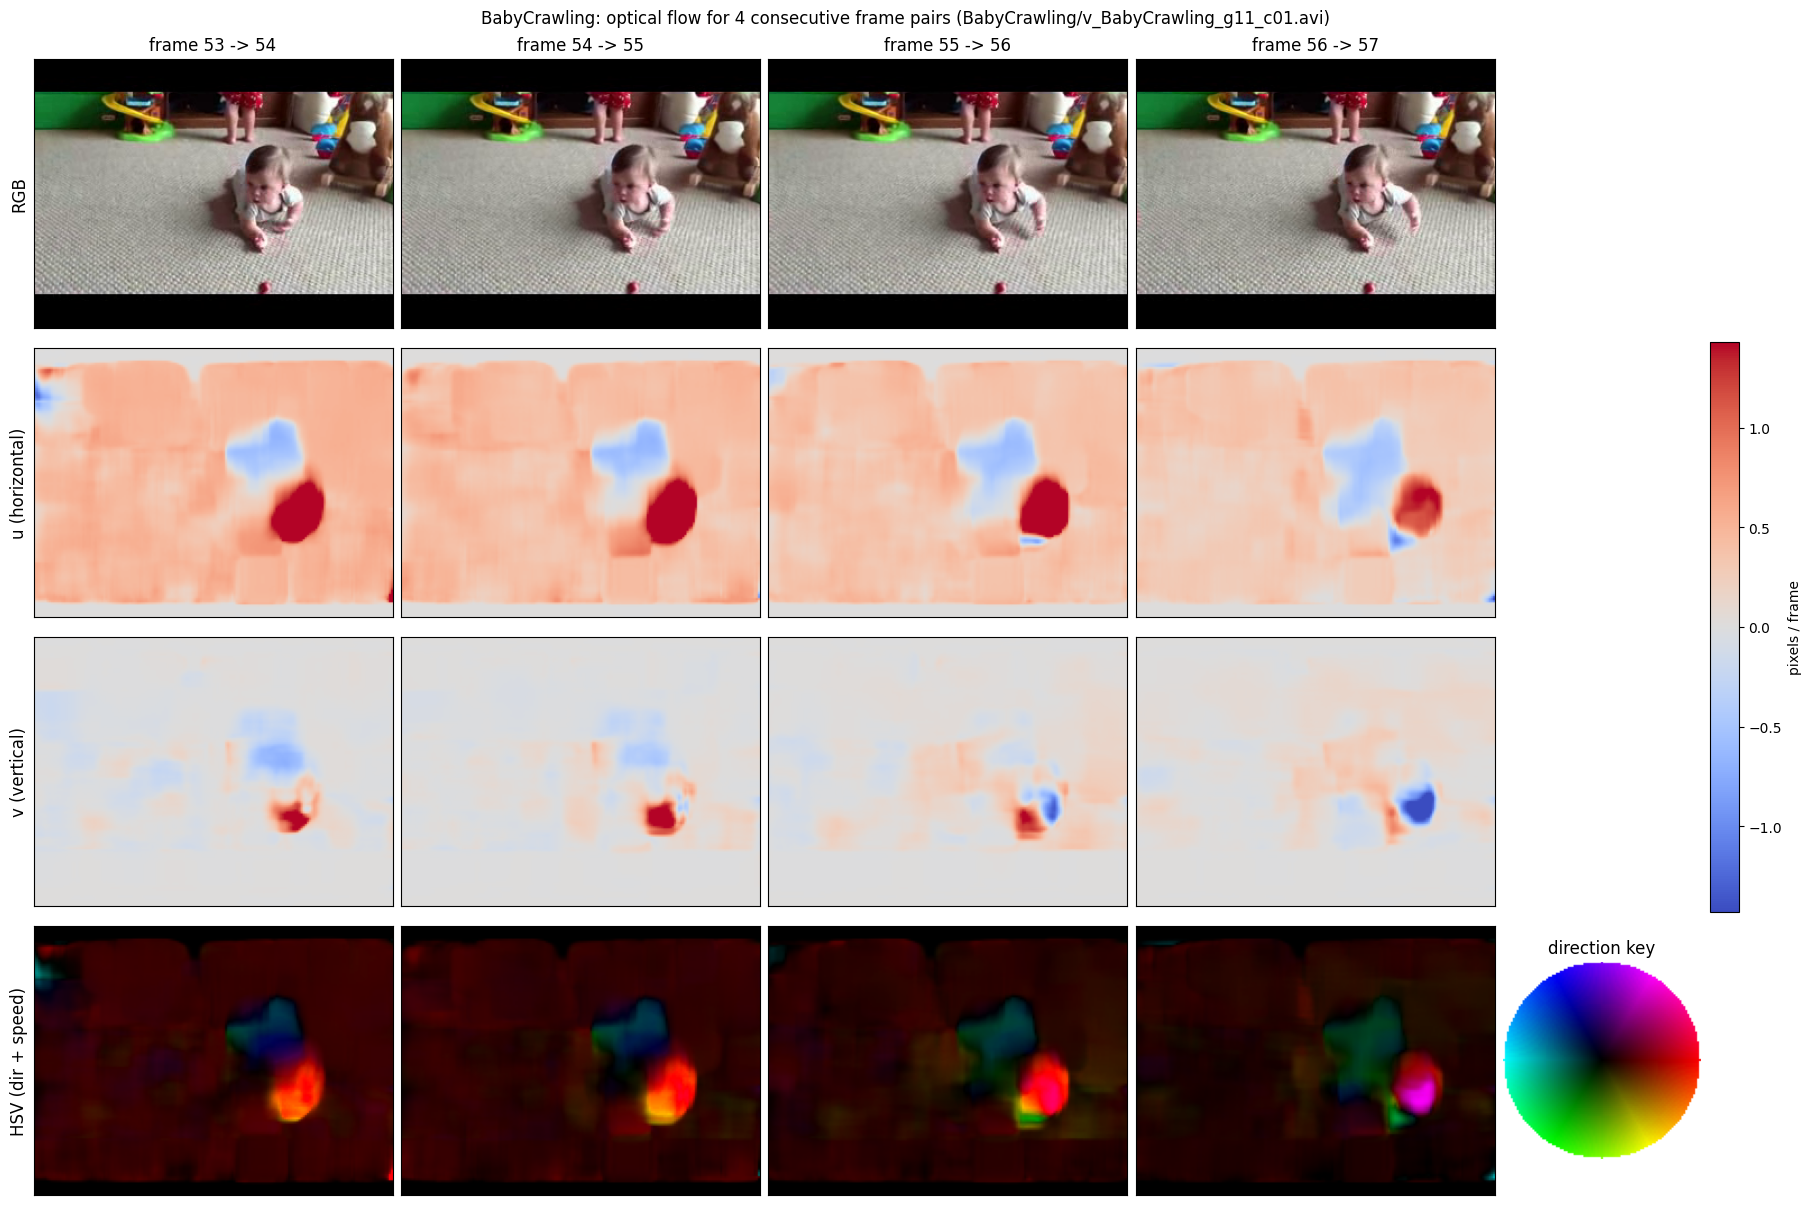

In [ ]:
FLOW_DEMO_CLASS = 'BabyCrawling'      # selected class to explore
row = data[(data.class_name == FLOW_DEMO_CLASS) & (data.phase == 'train')].iloc[0]
start = int(row.n_frames) // 2
pairs = list(range(start, start + 4))
fl, _ = oflow.compute_flows(video_path(row.rel_path), pairs, FLOW_SIZE)
rgb = read_frames(row.rel_path, pairs)
lim = max(np.percentile(np.abs(fl), 99), 1e-3)
mag_max = np.percentile(np.linalg.norm(fl, axis=-1), 99)

fig, axes = plt.subplots(4, 5, figsize=(18, 12), layout='constrained',
                         gridspec_kw={'width_ratios': [1, 1, 1, 1, 0.55]})
for c in range(4):
    axes[0, c].imshow(rgb[c]); axes[0, c].set_title(f'frame {pairs[c]} -> {pairs[c] + 1}')
    im_u = axes[1, c].imshow(fl[c, ..., 0], cmap='coolwarm', vmin=-lim, vmax=lim)
    im_v = axes[2, c].imshow(fl[c, ..., 1], cmap='coolwarm', vmin=-lim, vmax=lim)
    axes[3, c].imshow(oflow.flow_to_hsv(fl[c], max_mag=mag_max))
for r_, name in enumerate(['RGB', 'u (horizontal)', 'v (vertical)', 'HSV (dir + speed)']):
    axes[r_, 0].set_ylabel(name, fontsize=12)
for ax in axes[:, :4].flat:
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes[:3, 4]:
    ax.axis('off')
fig.colorbar(im_u, ax=axes[1:3, 4], fraction=0.5, label='pixels / frame')
axes[3, 4].imshow(oflow.color_wheel()); axes[3, 4].set_title('direction key'); axes[3, 4].axis('off')
plt.suptitle(f'{row.class_name}: optical flow for 4 consecutive frame pairs ({row.rel_path})')
save_fig('part1_ex5_optical_flow'); plt.show()

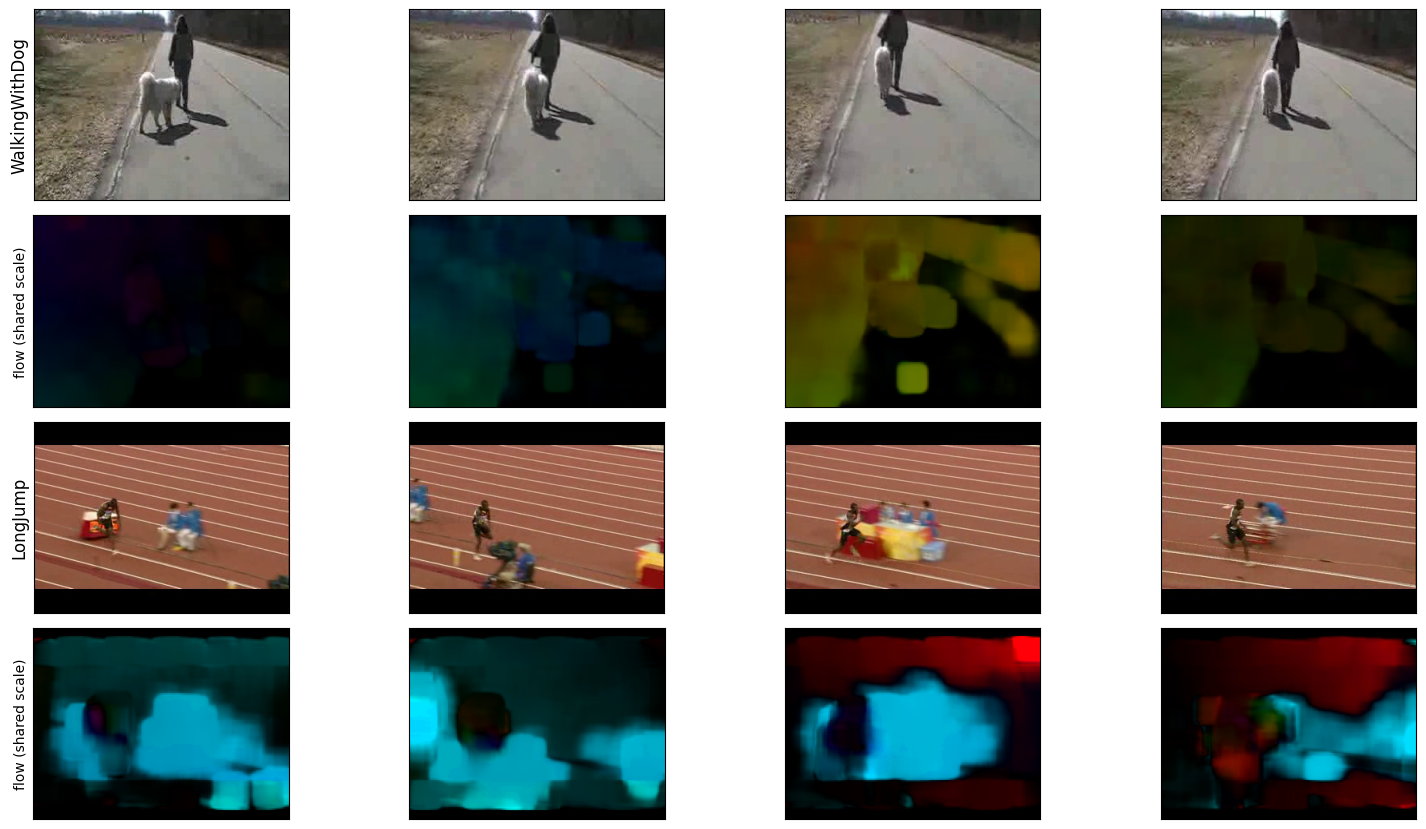

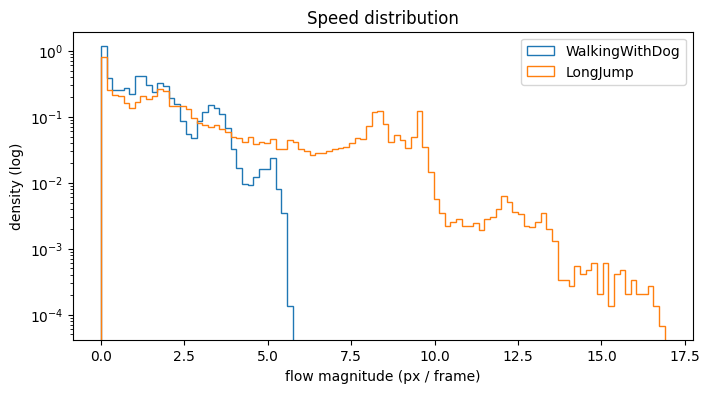

,mag,mag_comp,horiz_vs_vert,camera_share
class_name,,,,
PullUps,0.15,0.13,0.72,0.15
Archery,0.20,0.17,1.48,0.14
HandstandWalking,0.33,0.23,2.34,0.31
YoYo,0.36,0.35,1.10,0.04
PushUps,0.49,0.43,0.68,0.13
Fencing,0.61,0.41,3.41,0.33
Basketball,0.67,0.47,1.43,0.30
BabyCrawling,0.86,0.52,1.59,0.39
WalkingWithDog,1.35,0.82,3.04,0.39


In [ ]:
CMP_CLASSES = ['WalkingWithDog', 'LongJump']
cmp_flows = {}
for cls in CMP_CLASSES:
    r = full[(full.class_name == cls) & (full.phase == 'train')].iloc[0]
    mid = int(r.n_frames) // 2
    pairs = np.linspace(mid - 20, mid + 20, 4, dtype=int).clip(0, int(r.n_frames) - 2)
    cmp_flows[cls] = (r, pairs, oflow.compute_flows(video_path(r.rel_path), pairs, FLOW_SIZE)[0])
shared_max = max(np.percentile(np.linalg.norm(f, axis=-1), 99) for _, _, f in cmp_flows.values())

fig, axes = plt.subplots(len(CMP_CLASSES) * 2, 4, figsize=(16, 4.2 * len(CMP_CLASSES)))
for i, (cls, (r, pairs, f_)) in enumerate(cmp_flows.items()):
    rgb = read_frames(r.rel_path, pairs)
    for c in range(4):
        axes[2 * i, c].imshow(rgb[min(c, len(rgb) - 1)])
        axes[2 * i + 1, c].imshow(oflow.flow_to_hsv(f_[c], max_mag=shared_max))
        for ax in (axes[2 * i, c], axes[2 * i + 1, c]):
            ax.set_xticks([]); ax.set_yticks([])
    axes[2 * i, 0].set_ylabel(cls, fontsize=12); axes[2 * i + 1, 0].set_ylabel('flow (shared scale)')
plt.tight_layout(); save_fig('reflection_q3_walk_vs_run_flow'); plt.show()

plt.figure(figsize=(8, 4))
for cls, (_, _, f_) in cmp_flows.items():
    plt.hist(np.linalg.norm(f_, axis=-1).ravel(), bins=100, range=(0, shared_max * 1.5),
             histtype='step', density=True, lw=2, label=cls)
plt.yscale('log'); plt.xlabel('flow magnitude (px / frame)'); plt.ylabel('density (log)')
plt.title('Speed distribution'); plt.legend(); save_fig('reflection_q3_speed_hist'); plt.show()

per_class = flow_stats.groupby('class_name')[['mag', 'mag_comp', 'horiz_vs_vert']].mean()
per_class['camera_share'] = 1 - per_class.mag_comp / per_class.mag
per_class.sort_values('mag').round(2)

In [ ]:
FLOW_NAME  = f'flow_k{CACHE_K}_{CACHE_H}x{CACHE_W}_b{FLOW_BOUND:.0f}_q{FLOW_JPEG_Q}'
LOCAL_FLOW = f'{LOCAL_DATA}/{FLOW_NAME}'
FLOW_TAR   = f'{DRIVE_CACHE}/{FLOW_NAME}_{SUBSET}.tar'
os.makedirs(LOCAL_FLOW, exist_ok=True)

def flow_path(rel):
    return f'{LOCAL_FLOW}/{rel[:-4]}.npz'

def build_flow_cache(rel):
    out = flow_path(rel)
    if os.path.exists(out):
        return 'skip'
    src = src_idx_of(rel)
    flows, n_zero = oflow.compute_flows(video_path(rel), src, FLOW_SIZE)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    oflow.save_flow_npz(out + '.tmp', flows, FLOW_BOUND, src, FLOW_JPEG_Q)
    os.replace(out + '.tmp', out)
    return 'ok' if n_zero == 0 else 'ok_zero_pairs'

# --- test one clip: storage cost vs accuracy
r = data[data.phase == 'train'].iloc[0]
exact, _ = oflow.compute_flows(video_path(r.rel_path), src_idx_of(r.rel_path), FLOW_SIZE)
print(build_flow_cache(r.rel_path))
stored, bound = oflow.load_flow(flow_path(r.rel_path))
inside = (np.abs(exact) <= FLOW_BOUND).all(-1)                 # ignore clipped vectors
epe = np.linalg.norm(stored * bound - exact, axis=-1)[inside].mean()
size_kb = os.path.getsize(flow_path(r.rel_path)) / 1e3
f16_kb = exact.size * 2 / 1e3
print(f'Stored {stored.shape} | {size_kb:.0f} KB vs float16 {f16_kb:.0f} KB ({f16_kb / size_kb:.1f}x smaller) | '
      f'EPE {epe:.3f} px (typical motion p50 = {pct[0]:.2f} px)')

ok
Stored (32, 128, 171, 2) | 86 KB vs float16 2802 KB (32.5x smaller) | EPE 0.032 px (typical motion p50 = 0.04 px)


In [ ]:
def n_flow_cached():
    return sum(os.path.exists(flow_path(r)) for r in data.rel_path)

if n_flow_cached() < len(data) and os.path.exists(FLOW_TAR):
    print('Restoring flow cache from Drive...')
    subprocess.run(['tar', '-xf', FLOW_TAR, '-C', LOCAL_DATA], check=True)

todo = [r for r in data.rel_path if not os.path.exists(flow_path(r))]
print(f'{len(data) - len(todo)} cached, {len(todo)} to build')
if todo:
    t0 = time.perf_counter()
    with ThreadPoolExecutor(max_workers=min(8, 2 * os.cpu_count())) as ex:
        status = list(tqdm(ex.map(build_flow_cache, todo), total=len(todo), desc='Flow cache'))
    el = time.perf_counter() - t0
    print(pd.Series(status).value_counts().to_string())
    print(f'Built {len(todo)} clips in {el / 60:.1f} min ({el / len(todo):.2f} s/clip)')
    subprocess.run(['tar', '-cf', FLOW_TAR, '-C', LOCAL_DATA, FLOW_NAME], check=True)
    print(f'Backed up to {FLOW_TAR} ({os.path.getsize(FLOW_TAR) / 1e9:.2f} GB)')

missing = [r for r in data.rel_path if not os.path.exists(flow_path(r))]
assert not missing, f'{len(missing)} clips missing flow, e.g. {missing[:3]}'

# Save preprocessing settings so later steps (and the README) use the same values
cfg = dict(T=T, CACHE_K=CACHE_K, CACHE_H=CACHE_H, CACHE_W=CACHE_W, CROP=CROP, JPEG_Q=JPEG_Q,
           CACHE_NAME=CACHE_NAME, FLOW_NAME=FLOW_NAME, FLOW_BOUND=FLOW_BOUND,
           FLOW_JPEG_Q=FLOW_JPEG_Q, VAL_GROUPS=sorted(VAL_GROUPS), SEED=SEED)
json.dump(cfg, open(f'{DRIVE_META}/preprocess_config.json', 'w'), indent=2)
print(f' Flow cached for all {len(data)} clips; config saved')

Restoring flow cache from Drive...
1212 cached, 0 to build
 Flow cached for all 1212 clips; config saved


In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/utils/flow_dataset.py
"""Flow and RGB+flow datasets that share frame sampling, crop and flip."""
import os

import numpy as np
import torch
from torch.utils.data import Dataset

from utils.dataset import ClipTransform, segment_indices
from utils.optical_flow import decode_flow


class FlowClips(Dataset):
    """Optical-flow clips from the flow cache -> ((2, T, crop, crop) float32, label)."""

    def __init__(self, df, flow_dir, num_frames=16, train=False, crop=112, camera_comp=False):
        self.df = df.reset_index(drop=True)
        self.flow_dir, self.num_frames, self.train = flow_dir, num_frames, train
        self.camera_comp = camera_comp
        self.transform = ClipTransform(crop=crop, train=train)
        self.labels = self.df.label.astype(int).tolist()
        self.samples = list(zip(self.df.rel_path, self.labels))

    def __len__(self):
        return len(self.df)

    def path(self, i):
        return os.path.join(self.flow_dir, self.df.rel_path[i][:-4] + '.npz')

    def get(self, i, params=None):
        """params (from the RGB dataset) forces the same frames/crop/flip; None samples new ones."""
        z = np.load(self.path(i))
        data, off = z['data'], z['offsets']
        k = (len(off) - 1) // 2
        which = params['frame_idx'] if params else segment_indices(k, self.num_frames, self.train)
        assert max(which) < k, 'RGB and flow caches have different K'
        flow = decode_flow(data, off, which)                       # (T, H, W, 2) in [-1, 1]
        if self.camera_comp:
            flow = flow - np.median(flow, axis=(1, 2), keepdims=True)
        flow, p = self.transform(flow, params)
        if p['flip']:
            flow[..., 0] *= -1                                     # mirrored image: right <-> left
        p['frame_idx'] = which
        return torch.from_numpy(flow).permute(3, 0, 1, 2).float(), self.labels[i], p

    def __getitem__(self, i):
        flow, label, _ = self.get(i)
        return flow, label


class MultimodalClips(Dataset):
    """(rgb (3,T,H,W), flow (2,T,H,W), label) with one shared set of augmentation parameters."""

    def __init__(self, rgb_ds, flow_ds):
        assert list(rgb_ds.df.rel_path) == list(flow_ds.df.rel_path), 'datasets not aligned'
        self.rgb, self.flow = rgb_ds, flow_ds
        self.samples, self.labels = rgb_ds.samples, rgb_ds.labels

    def __len__(self):
        return len(self.rgb)

    def get(self, i):
        rgb, label, params = self.rgb.get(i)
        flow, _, _ = self.flow.get(i, params=params)
        return rgb, flow, label, params

    def __getitem__(self, i):
        rgb, flow, label, _ = self.get(i)
        return rgb, flow, label


Overwriting /content/drive/MyDrive/videosense/code/utils/flow_dataset.py


Sanity checks: shapes, range, flip correctness, alignment, speed

In [ ]:
import utils.flow_dataset as fds
importlib.reload(fds)

flow_ds = {p: fds.FlowClips(d, LOCAL_FLOW, num_frames=T, train=(p == 'train'), crop=CROP)
           for p, d in phase_df.items()}
f0, l0 = flow_ds['train'][0]
print(f'Flow clip {tuple(f0.shape)} {f0.dtype} | range [{f0.min():.2f}, {f0.max():.2f}] | label {l0}')
assert f0.shape == (2, T, CROP, CROP) and f0.abs().max() <= 1.0 + 1e-6

# Flip correctness: flipped u == -(mirrored u); flipped v == mirrored v
fe = fds.FlowClips(phase_df['train'], LOCAL_FLOW, num_frames=T, train=False, crop=CROP)
base, _, p = fe.get(0)
flipped, _, _ = fe.get(0, params=dict(p, flip=True))
assert torch.equal(flipped[0], -base[0].flip(-1)), 'u not negated on flip'
assert torch.equal(flipped[1], base[1].flip(-1)), 'v changed on flip'
print(' Flip handling correct (u negated, v kept)')

# Alignment: multimodal sample shares frames/crop/flip
mm = fds.MultimodalClips(ds['train'], flow_ds['train'])
rgb, flow, label, params = mm.get(0)
assert rgb.shape[1:] == flow.shape[1:], 'RGB and flow differ in T/H/W'
print(f'Multimodal: rgb {tuple(rgb.shape)} + flow {tuple(flow.shape)} | '
      f'crop y={params["y"]}, x={params["x"]}, flip={params["flip"]}')

Flow clip (2, 16, 112, 112) torch.float32 | range [-0.73, 0.42] | label 0
 Flip handling correct (u negated, v kept)
Multimodal: rgb (3, 16, 112, 112) + flow (2, 16, 112, 112) | crop y=6, x=44, flip=False


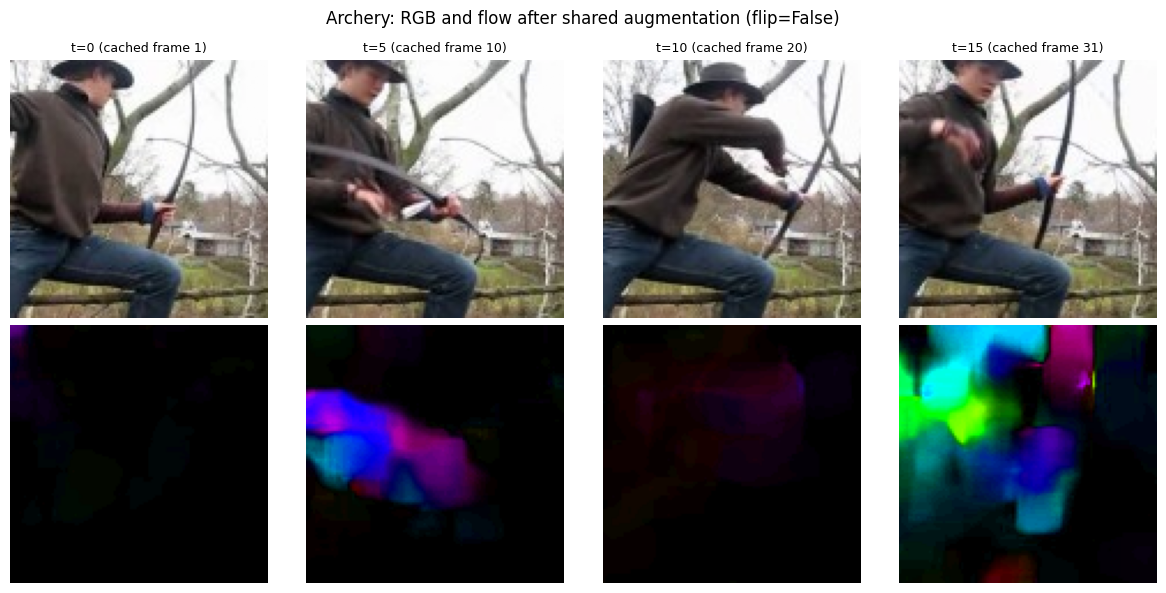

Multimodal loading: 13.8 ms/clip


In [ ]:
# See the alignment: an augmented RGB clip and its flow (same crop/flip/frames)
frames = vds.denormalize(rgb)
flow_px = flow.permute(1, 2, 3, 0).numpy() * FLOW_BOUND
show_t = [0, 5, 10, 15]
mag_max = np.percentile(np.linalg.norm(flow_px, axis=-1), 99) + 1e-6
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, t in enumerate(show_t):
    axes[0, c].imshow(frames[t]); axes[0, c].set_title(f't={t} (cached frame {params["frame_idx"][t]})', fontsize=9)
    axes[1, c].imshow(oflow.flow_to_hsv(flow_px[t], max_mag=mag_max))
for ax in axes.flat:
    ax.axis('off')
plt.suptitle(f'{phase_df["train"].class_name.iloc[0]}: RGB and flow after shared augmentation (flip={params["flip"]})')
plt.tight_layout(); save_fig('flow_rgb_alignment'); plt.show()

print(f'Multimodal loading: {time_loader(mm, min(2, os.cpu_count())):.1f} ms/clip')

Step 5 — C3D from scratch: model, training loop, evaluation (Part 2: Exercises 6–8, 10; Reflection Q11)

Running the whole notebook in one session: pick the GPU runtime (Runtime → Change runtime type → T4 GPU) **before Step 1**. Changing the runtime type later restarts the session and erases every variable and the local caches. Steps 1–4 run fine on a GPU runtime; they just don't use the GPU.

The setup cell below takes everything it needs from Steps 3–4 in this session (config, splits, frame cache). It only falls back to the copies on Drive when those variables don't exist, and it writes the config and split files itself, so `train_3dcnn.py` always finds them.

In [ ]:
import os, sys, json, math, random, subprocess, time, importlib
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# ---- 1. Paths: from Step 1.2 if it ran in this session, otherwise re-mount Drive
if 'DRIVE_ROOT' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/videosense'
    LOCAL_DATA = '/content/videosense/data'
DRIVE_META = f'{DRIVE_ROOT}/metadata'
SUBSET = globals().get('SUBSET', 'mini')
CODE_DIR    = f'{DRIVE_ROOT}/code'
DRIVE_CACHE = f'{DRIVE_ROOT}/cache'
DRIVE_FIG   = f'{DRIVE_ROOT}/figures'
DRIVE_RUNS  = f'{DRIVE_ROOT}/runs'                    # one folder per training run: best.pt, history.json, config.json
RESULTS_CSV = f'{DRIVE_ROOT}/results/results.csv'     # every number that goes into the report tables
for d in [DRIVE_META, DRIVE_FIG, DRIVE_RUNS, os.path.dirname(RESULTS_CSV),
          f'{CODE_DIR}/models', f'{CODE_DIR}/utils', LOCAL_DATA]:
    os.makedirs(d, exist_ok=True)
for pkg in ['utils', 'models']:
    open(f'{CODE_DIR}/{pkg}/__init__.py', 'a').close()
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

def save_fig(name):
    plt.savefig(f'{DRIVE_FIG}/{name}.png', dpi=150, bbox_inches='tight')

def log_result(**row):
    """Upsert one row (keyed by model, subset, variant) into the results table."""
    res = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame(columns=['model', 'subset', 'variant'])
    keep = ~((res.model == row['model']) & (res.subset == row['subset']) & (res.variant == row['variant']))
    res = pd.concat([res[keep], pd.DataFrame([row])], ignore_index=True)
    res.to_csv(RESULTS_CSV, index=False)
    return res

# ---- 2. Preprocessing config: this session's Step 3-4 values first, Drive copy second
PRE_CFG = f'{DRIVE_META}/preprocess_config.json'
PRE_KEYS = ['T', 'CACHE_K', 'CACHE_H', 'CACHE_W', 'CROP', 'JPEG_Q', 'CACHE_NAME', 'SEED']
if all(k in globals() for k in PRE_KEYS):
    pre = {k: globals()[k] for k in PRE_KEYS}
    pre['VAL_GROUPS'] = sorted(globals().get('VAL_GROUPS', {8, 9, 10}))
    for k in ('FLOW_NAME', 'FLOW_BOUND', 'FLOW_JPEG_Q'):          # from Step 4, if it ran
        if k in globals():
            pre[k] = globals()[k]
    pre_source = 'Steps 3-4 in this session'
elif os.path.exists(PRE_CFG):
    pre = json.load(open(PRE_CFG))
    pre_source = PRE_CFG
else:
    raise RuntimeError('No preprocessing settings found: run Step 3 (and Step 4) in this session first.')
json.dump(pre, open(PRE_CFG, 'w'), indent=2)                  # train_3dcnn.py reads this file
T, CROP, SEED = pre['T'], pre['CROP'], pre['SEED']
CACHE_NAME  = pre['CACHE_NAME']
LOCAL_CACHE = f'{LOCAL_DATA}/{CACHE_NAME}'

# ---- 3. Train / val / test split: Step 3's table if in memory, Drive copy otherwise
SPLITS_CSV = f'{DRIVE_META}/splits_{SUBSET}.csv'
if 'data' in globals() and isinstance(data, pd.DataFrame) and 'phase' in data.columns:
    data.to_csv(SPLITS_CSV, index=False)                     # train_3dcnn.py reads this file
    split_source = 'Step 3 in this session'
elif os.path.exists(SPLITS_CSV):
    data = pd.read_csv(SPLITS_CSV)
    split_source = SPLITS_CSV
else:
    raise RuntimeError('No train/val/test split found: run the split cell of Step 3 first.')
N_CLASSES = data.label.nunique()

# ---- 4. Frame cache: local copy from Step 3, else restore the tar from Drive
def cache_path(rel):
    return f'{LOCAL_CACHE}/{rel[:-4]}.npz'

def cache_complete():
    return all(os.path.exists(cache_path(r)) for r in data.rel_path)

CACHE_TAR = f'{DRIVE_CACHE}/{CACHE_NAME}_{SUBSET}.tar'
if not cache_complete() and os.path.exists(CACHE_TAR):
    print('Restoring frame cache from Drive...')
    subprocess.run(['tar', '-xf', CACHE_TAR, '-C', LOCAL_DATA], check=True)
assert cache_complete(), f'Frame cache incomplete in {LOCAL_CACHE}: rerun the "Build the cache" cell of Step 3'

# ---- 5. Device
DEVICE = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True        # fixed input size: let cuDNN pick the fastest conv kernels
NUM_WORKERS = os.cpu_count()
print(f'Config from : {pre_source}')
print(f'Splits from : {split_source}')
print(f'Frame cache : {LOCAL_CACHE} ({len(data)} clips)')
print(f'Device      : {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if DEVICE.type == 'cuda'
                                   else '  <- training needs a GPU runtime (see the note above)'))
print(f'Subset: {SUBSET} | classes: {N_CLASSES} | T={T}, crop={CROP} | '
      + ' / '.join(f'{p} {n}' for p, n in data.phase.value_counts().items()))

Config from : Steps 3-4 in this session
Splits from : Step 3 in this session
Frame cache : /content/videosense/data/frames_k32_128x171_q90 (1212 clips)
Device      : cuda (Tesla T4)
Subset: mini | classes: 10 | T=16, crop=112 | train 721 / test 342 / val 149


Write models/cnn3d.py: C3D as in the assignment (Section 6.1), plus the R(2+1)D block (Section 6.2)

One change: an `in_channels` argument, so the flow stream in Part 4 can build a 2-channel C3D directly instead of swapping out the first conv layer.

Step 6 adds `PretrainedR2Plus1D`: torchvision's Kinetics-400 R(2+1)D-18 with a new head, used for Exercise 9.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/models/cnn3d.py
"""3D CNNs for video: C3D (Tran et al., 2015), an R(2+1)D residual block (Tran et al., 2018),
and torchvision's Kinetics-400 pretrained R(2+1)D-18 with a new classification head."""
import torch
import torch.nn as nn
from torchvision.models.video import R2Plus1D_18_Weights, r2plus1d_18


class C3D(nn.Module):
    """C3D for clip classification.

    Input : (B, in_channels, T=16, H=112, W=112)
    Output: (B, num_classes)
    """

    def __init__(self, num_classes=101, dropout=0.5, in_channels=3):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: pool only spatially, so early layers keep full temporal resolution
            nn.Conv3d(in_channels, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2)),           # (64, 16, 56, 56)
            # Block 2
            nn.Conv3d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool3d(kernel_size=2, stride=2),                            # (128, 8, 28, 28)
            # Block 3
            nn.Conv3d(128, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv3d(256, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool3d(kernel_size=2, stride=2),                            # (256, 4, 14, 14)
            # Block 4
            nn.Conv3d(256, 512, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv3d(512, 512, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool3d(kernel_size=2, stride=2),                            # (512, 2, 7, 7)
            # Block 5
            nn.Conv3d(512, 512, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv3d(512, 512, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool3d(kernel_size=2, stride=2),                            # (512, 1, 3, 3)
        )
        self.feat_dim = 512 * 1 * 3 * 3
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.feat_dim, 4096), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(4096, 4096), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(4096, num_classes),
        )
        self._initialize_weights()

    def forward(self, x):
        return self.classifier(self.features(x))

    def get_embedding(self, x):
        """4096-d fc6 activation (after ReLU), used for t-SNE and as a Siamese baseline."""
        return self.classifier[:3](self.features(x))

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)


class R2Plus1DBlock(nn.Module):
    """One R(2+1)D residual block: 1x3x3 spatial conv, then 3x1x1 temporal conv."""

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.spatial = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=(1, 3, 3), stride=(1, stride, stride),
                      padding=(0, 1, 1), bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
        )
        self.temporal = nn.Sequential(
            nn.Conv3d(out_ch, out_ch, kernel_size=(3, 1, 1), stride=(stride, 1, 1),
                      padding=(1, 0, 0), bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
        )
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm3d(out_ch),
            )

    def forward(self, x):
        return torch.relu(self.temporal(self.spatial(x)) + self.shortcut(x))


class PretrainedR2Plus1D(nn.Module):
    """torchvision R(2+1)D-18 pretrained on Kinetics-400, with a new fc head for our classes.

    finetune='head'   : only the new fc layer trains (linear probe, Exercise 9)
    finetune='layer4' : last residual stage + fc
    finetune='all'    : every layer
    Frozen parts stay in eval mode during training, so their BatchNorm keeps the Kinetics
    running statistics instead of re-estimating them from batches of 8 UCF101 clips.
    Input: (B, 3, T, 112, 112), normalized with the Kinetics mean / std.
    """

    TRAINABLE = {'head': ('fc.',), 'layer4': ('layer4.', 'fc.'), 'all': ('',)}

    def __init__(self, num_classes=101, finetune='head', pretrained=True):
        super().__init__()
        self.net = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1 if pretrained else None)
        self.net.fc = nn.Linear(self.net.fc.in_features, num_classes)
        self.finetune = finetune
        for name, p in self.net.named_parameters():
            p.requires_grad = name.startswith(self.TRAINABLE[finetune])

    def train(self, mode=True):
        super().train(mode)
        for child in self.net.children():
            if not any(p.requires_grad for p in child.parameters()):
                child.eval()
        return self

    def forward(self, x):
        return self.net(x)

    def get_embedding(self, x):
        """512-d clip feature after global average pooling (the input of the fc head)."""
        n = self.net
        x = n.layer4(n.layer3(n.layer2(n.layer1(n.stem(x)))))
        return n.avgpool(x).flatten(1)


Overwriting /content/drive/MyDrive/videosense/code/models/cnn3d.py


Shape trace, receptive field, and complexity (Section 6.1 hint, Reflection Q11, Exercise 10 part 1)

In [ ]:
import models.cnn3d as cnn3d
importlib.reload(cnn3d)

model = cnn3d.C3D(num_classes=N_CLASSES)

# 1) Tensor shape after every pooling layer
rows, h = [], torch.zeros(1, 3, T, CROP, CROP)
with torch.no_grad():
    for i, layer in enumerate(model.features):
        h = layer(h)
        if isinstance(layer, torch.nn.MaxPool3d):
            rows.append({'after': f'pool{len(rows) + 1}', '(C, T, H, W)': tuple(h.shape[1:])})
print(pd.DataFrame(rows).to_string(index=False))
assert tuple(h.shape[1:]) == (512, 1, 3, 3), 'classifier input size assumes (512, 1, 3, 3)'

# 2) Receptive field, analytically: rf += (k - 1) * jump ; jump *= stride
def as3(v):
    return np.broadcast_to(np.array(v), 3).astype(int)

gap_s = ((data.n_frames - 1) / (T - 1) / data.fps).median()     # seconds between sampled frames
rf, jump, rf_rows, n_conv = np.ones(3, int), np.ones(3, int), [], 0
for layer in model.features:
    if isinstance(layer, (torch.nn.Conv3d, torch.nn.MaxPool3d)):
        rf = rf + (as3(layer.kernel_size) - 1) * jump
        jump = jump * as3(layer.stride)
        n_conv += isinstance(layer, torch.nn.Conv3d)
        if isinstance(layer, torch.nn.MaxPool3d) or n_conv == 1:
            rf_rows.append({'layer': f'conv1' if len(rf_rows) == 0 else f'pool{len(rf_rows)}',
                            'RF frames': rf[0], 'RF span in seconds': round((min(rf[0], T) - 1) * gap_s, 2),
                            'RF pixels (H)': rf[1]})
print(f'\nReceptive field (median gap between sampled frames = {gap_s:.2f} s):')
print(pd.DataFrame(rf_rows).to_string(index=False))

# 3) ...and empirically: which input voxels can influence the centre pool5 unit?
x = torch.randn(1, 3, T, CROP, CROP, requires_grad=True)
model.features(x)[0, :, 0, 1, 1].sum().backward()
g = x.grad.abs().sum(dim=(0, 1))                                  # (T, H, W)
frames_hit = int((g.sum(dim=(1, 2)) > 0).sum())
rows_hit = int((g.sum(dim=(0, 2)) > 0).sum())
print(f'\nGradient check: centre pool5 unit depends on {frames_hit}/{T} frames and {rows_hit}/{CROP} rows')

after     (C, T, H, W)
pool1 (64, 16, 56, 56)
pool2 (128, 8, 28, 28)
pool3 (256, 4, 14, 14)
pool4   (512, 2, 7, 7)
pool5   (512, 1, 3, 3)

Receptive field (median gap between sampled frames = 0.38 s):
layer  RF frames  RF span in seconds  RF pixels (H)
conv1          3                0.77              3
pool1          3                0.77              4
pool2          6                1.92             10
pool3         16                5.77             30
pool4         36                5.77             70
pool5         76                5.77            150

Gradient check: centre pool5 unit depends on 16/16 frames and 112/112 rows


Reading the table for Q11: the analytic temporal RF at pool5 is larger than T, so every pool5 unit sees all 16 sampled frames (≈ the whole clip with uniform sampling). But conv1 only spans 3 consecutive samples, about 2 × the median gap in real time (≈ 0.9 s), so motion faster than one sampling gap is invisible to the RGB stream. That is the gap optical flow fills in Part 4.

In [ ]:
try:
    import torchinfo
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torchinfo'], check=True)
    import torchinfo

summ = torchinfo.summary(model, input_size=(1, 3, T, CROP, CROP), depth=2, verbose=0,
                         col_names=('output_size', 'num_params', 'mult_adds'))
print(summ)

n_feat = sum(p.numel() for p in model.features.parameters())
n_cls = sum(p.numel() for p in model.classifier.parameters())
c3d_complexity = dict(params_M=round(summ.total_params / 1e6, 2), gmacs=round(summ.total_mult_adds / 1e9, 2))
print(f'\nParams: {c3d_complexity["params_M"]} M (conv {n_feat / 1e6:.1f} M, fully connected {n_cls / 1e6:.1f} M) | '
      f'{c3d_complexity["gmacs"]} GMACs per clip (~{2 * c3d_complexity["gmacs"]:.0f} GFLOPs)')
del model, x, g

Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
C3D                                      [1, 10]                   --                        --
├─Sequential: 1-1                        [1, 512, 1, 3, 3]         --                        --
│    └─Conv3d: 2-1                       [1, 64, 16, 112, 112]     5,248                     1,053,294,592
│    └─ReLU: 2-2                         [1, 64, 16, 112, 112]     --                        --
│    └─MaxPool3d: 2-3                    [1, 64, 16, 56, 56]       --                        --
│    └─Conv3d: 2-4                       [1, 128, 16, 56, 56]      221,312                   11,104,550,912
│    └─ReLU: 2-5                         [1, 128, 16, 56, 56]      --                        --
│    └─MaxPool3d: 2-6                    [1, 128, 8, 28, 28]       --                        --
│    └─Conv3d: 2-7                       [1, 256, 8, 28, 28]       884,992                   5,550,669,824

Write utils/engine.py: one training and evaluation loop for every model (Exercise 6)

Batches are `(input_1, ..., input_n, label)` and the model is called as `model(*inputs)`, so the same loop trains the two-stream model later. `evaluate()` reports top-1, top-5, and plain cross-entropy (NLL), which stays comparable across label-smoothing values. Checkpoints go to Drive: `best.pt` whenever val top-1 improves, `last.pt` every few epochs so a disconnected session resumes instead of restarting.

Step 8 adds an optional `epoch_extras` hook to `fit()`, so the attention-fusion run can log its learned weight α every epoch. Without it, `fit()` behaves exactly as before.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/utils/engine.py
"""Training and evaluation loops shared by every VideoSense model.

Batches are tuples (input_1, ..., input_n, label); the model is called as model(*inputs),
so the same code trains single-stream (rgb, label) and two-stream (rgb, flow, label) models.
"""
import json
import os
import time

import torch
import torch.nn.functional as F


def split_batch(batch, device):
    *inputs, labels = batch
    return ([x.to(device, non_blocking=True) for x in inputs],
            labels.to(device, non_blocking=True))


def _autocast(device, amp):
    """Mixed precision on CUDA only (fp16 halves memory and roughly doubles T4 throughput)."""
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=amp and device.type == 'cuda')


def topk_hits(logits, labels, ks=(1, 5)):
    """Number of samples whose true label is among the top-k predictions, for each k."""
    maxk = min(max(ks), logits.size(1))
    hit = logits.topk(maxk, dim=1).indices.eq(labels[:, None])
    return {k: hit[:, :min(k, maxk)].any(dim=1).sum().item() for k in ks}


@torch.no_grad()
def evaluate(model, loader, device, criterion=None, amp=True, return_logits=False):
    """Top-1 / top-5 accuracy, plain cross-entropy ('nll') and the training criterion's loss ('loss')."""
    device = torch.device(device)
    model.eval()
    n, nll, crit, hits = 0, 0.0, 0.0, {1: 0, 5: 0}
    logits_all, labels_all = [], []
    for batch in loader:
        inputs, labels = split_batch(batch, device)
        with _autocast(device, amp):
            logits = model(*inputs)
        logits = logits.float()
        nll += F.cross_entropy(logits, labels, reduction='sum').item()
        if criterion is not None:
            crit += criterion(logits, labels).item() * labels.size(0)
        for k, v in topk_hits(logits, labels).items():
            hits[k] += v
        n += labels.size(0)
        if return_logits:
            logits_all.append(logits.cpu())
            labels_all.append(labels.cpu())
    out = {'nll': nll / n, 'top1': hits[1] / n, 'top5': hits[5] / n}
    out['loss'] = crit / n if criterion is not None else out['nll']
    if return_logits:
        out['logits'] = torch.cat(logits_all).numpy()
        out['labels'] = torch.cat(labels_all).numpy()
    return out


def train_one_epoch(model, loader, criterion, optimizer, scaler, device, amp=True, max_grad_norm=None):
    """One pass over the training loader. Accuracy is measured on augmented clips, in train mode."""
    model.train()
    n, total_loss, correct = 0, 0.0, 0
    for batch in loader:
        inputs, labels = split_batch(batch, device)
        optimizer.zero_grad(set_to_none=True)
        with _autocast(device, amp):
            logits = model(*inputs)
        loss = criterion(logits.float(), labels)
        if not torch.isfinite(loss):
            raise FloatingPointError('Loss is NaN/inf: lower the learning rate')
        scaler.scale(loss).backward()
        if max_grad_norm:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        n += labels.size(0)
    return {'loss': total_loss / n, 'top1': correct / n}


def _atomic_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)


def fit(model, loaders, criterion, optimizer, scheduler, epochs, device, run_dir,
        amp=True, save_every=5, max_grad_norm=None, log=print, epoch_extras=None):
    """Train with per-epoch validation and resumable checkpoints.

    Writes to run_dir:
        best.pt       weights with the highest val top-1 (best.json records which epoch)
        last.pt       full training state every `save_every` epochs; deleted once the run finishes
        history.json  one row per epoch
    Re-running with the same run_dir resumes from last.pt; a finished run returns immediately.
    epoch_extras(model) -> dict, if given, adds model-specific values to every history row.
    """
    device = torch.device(device)
    os.makedirs(run_dir, exist_ok=True)
    p_best, p_last = os.path.join(run_dir, 'best.pt'), os.path.join(run_dir, 'last.pt')
    p_hist, p_bjson = os.path.join(run_dir, 'history.json'), os.path.join(run_dir, 'best.json')

    if os.path.exists(p_hist) and os.path.exists(p_best) and not os.path.exists(p_last):
        history = json.load(open(p_hist))
        if len(history) >= epochs:
            log(f'Run already finished ({len(history)} epochs): {run_dir}')
            return history

    scaler = torch.amp.GradScaler(device.type, enabled=amp and device.type == 'cuda')
    history, start, best = [], 0, -1.0
    if os.path.exists(p_last):
        state = torch.load(p_last, map_location=device, weights_only=False)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler'])
        history, start = state['history'], state['epoch']
        if os.path.exists(p_bjson):                  # best.pt may be newer than last.pt
            best = json.load(open(p_bjson))['val_top1']
        log(f'Resumed from epoch {start}')
    best = max([best] + [h['val_top1'] for h in history])

    for epoch in range(start, epochs):
        t0 = time.time()
        lr = optimizer.param_groups[0]['lr']
        tr = train_one_epoch(model, loaders['train'], criterion, optimizer, scaler, device, amp, max_grad_norm)
        va = evaluate(model, loaders['val'], device, criterion, amp)
        scheduler.step()
        row = dict(epoch=epoch + 1, lr=lr, train_loss=tr['loss'], train_top1=tr['top1'],
                   val_loss=va['loss'], val_nll=va['nll'], val_top1=va['top1'], val_top5=va['top5'],
                   epoch_time=time.time() - t0)
        if epoch_extras is not None:
            row.update(epoch_extras(model))
        history.append(row)

        improved = va['top1'] > best
        if improved:
            best = va['top1']
            _atomic_save(model.state_dict(), p_best)
            json.dump({'epoch': epoch + 1, 'val_top1': best}, open(p_bjson, 'w'))
        if (epoch + 1) % save_every == 0 and epoch + 1 < epochs:
            _atomic_save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                              scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
                              history=history, epoch=epoch + 1), p_last)
        json.dump(history, open(p_hist, 'w'), indent=1)
        log(f'Epoch {epoch + 1:>3}/{epochs} | loss {tr["loss"]:.3f} / {va["loss"]:.3f} | '
            f'top-1 {tr["top1"]:.3f} / {va["top1"]:.3f} | val top-5 {va["top5"]:.3f} | '
            f'{row["epoch_time"]:.0f}s' + ('  *best' if improved else ''))

    if os.path.exists(p_last):
        os.remove(p_last)                            # finished: free ~0.75 GB of Drive per run
    return history


Overwriting /content/drive/MyDrive/videosense/code/utils/engine.py


Write train_3dcnn.py: the deliverable training script. The notebook imports its `run()`, so the script and the notebook train exactly the same way.

Step 6 adds `--model r2plus1d` (pretrained R(2+1)D-18, Kinetics normalization, `--finetune head|layer4|all`). The C3D defaults and run names are unchanged, so finished C3D runs still reload instead of retraining.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/train_3dcnn.py
"""Part 2: train C3D from scratch, or fine-tune a Kinetics-pretrained R(2+1)D-18, on UCF101.

Usage (from the code/ folder, once the cache exists):
    python train_3dcnn.py --subset mini --label-smoothing 0.1 --epochs 30
    python train_3dcnn.py --subset mini --model r2plus1d --finetune head --epochs 10 --lr 1e-3
The notebook imports run() from this file, so both train identically.
"""
import argparse
import json
import os
import random

import numpy as np
import pandas as pd
import torch
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader

from models.cnn3d import C3D, PretrainedR2Plus1D
from utils.dataset import UCF101Clips
from utils.engine import evaluate, fit

DRIVE_ROOT = '/content/drive/MyDrive/videosense'
DEFAULTS = dict(subset='mini', epochs=30, batch_size=8, lr=1e-3, weight_decay=1e-4,
                label_smoothing=0.1, dropout=0.5, num_workers=2, seed=42, amp=True,
                meta_dir=f'{DRIVE_ROOT}/metadata', cache_dir=None, run_root=f'{DRIVE_ROOT}/runs',
                name=None, model='c3d', finetune='head', norm=None)
# Each model gets the input statistics it was trained with (Step 3.4)
NORM_FOR_MODEL = {'c3d': 'imagenet', 'r2plus1d': 'kinetics'}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_datasets(cfg):
    """train / val / test UCF101Clips built from the group-based split and preprocessing config."""
    pre = json.load(open(os.path.join(cfg['meta_dir'], 'preprocess_config.json')))
    cache_dir = cfg['cache_dir'] or f"/content/videosense/data/{pre['CACHE_NAME']}"
    norm = cfg.get('norm') or NORM_FOR_MODEL[cfg.get('model', 'c3d')]
    splits = pd.read_csv(os.path.join(cfg['meta_dir'], f"splits_{cfg['subset']}.csv"))
    return {p: UCF101Clips(splits[splits.phase == p], cache_dir, num_frames=pre['T'],
                           train=(p == 'train'), crop=pre['CROP'], norm=norm)
            for p in ('train', 'val', 'test')}


def make_loaders(datasets, cfg):
    nw = cfg['num_workers']
    gen = torch.Generator().manual_seed(cfg['seed'])          # reproducible shuffling
    return {p: DataLoader(d, batch_size=cfg['batch_size'], shuffle=(p == 'train'),
                          drop_last=(p == 'train'), num_workers=nw,
                          pin_memory=torch.cuda.is_available(), persistent_workers=nw > 0,
                          generator=gen if p == 'train' else None)
            for p, d in datasets.items()}


def build_model(cfg, n_classes, pretrained=True):
    if cfg.get('model', 'c3d') == 'r2plus1d':
        return PretrainedR2Plus1D(num_classes=n_classes, finetune=cfg['finetune'], pretrained=pretrained)
    return C3D(num_classes=n_classes, dropout=cfg['dropout'])


def run_name(cfg):
    if cfg['name']:
        return cfg['name']
    if cfg.get('model', 'c3d') == 'r2plus1d':
        return f"r2p1d_{cfg['subset']}_{cfg['finetune']}_ls{cfg['label_smoothing']:g}_lr{cfg['lr']:g}"
    return f"c3d_{cfg['subset']}_ls{cfg['label_smoothing']:g}_lr{cfg['lr']:g}"


def run(overrides=None):
    """Train one configuration (resumable). Returns the best model plus everything used to train it."""
    cfg = {**DEFAULTS, **(overrides or {})}
    seed_everything(cfg['seed'])
    device = torch.device('cuda' if torch.cuda.is_available()
                          else 'mps' if torch.backends.mps.is_available() else 'cpu')
    datasets = make_datasets(cfg)
    loaders = make_loaders(datasets, cfg)
    n_classes = len(set(datasets['train'].labels))

    model = build_model(cfg, n_classes).to(device)
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    trainable = [p for p in model.parameters() if p.requires_grad]     # frozen layers get no updates
    optimizer = Adam(trainable, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=cfg['epochs'])

    run_dir = os.path.join(cfg['run_root'], run_name(cfg))
    os.makedirs(run_dir, exist_ok=True)
    json.dump(cfg, open(os.path.join(run_dir, 'config.json'), 'w'), indent=2)
    history = fit(model, loaders, criterion, optimizer, scheduler, cfg['epochs'], device,
                  run_dir, amp=cfg['amp'])
    model.load_state_dict(torch.load(os.path.join(run_dir, 'best.pt'), map_location=device,
                                     weights_only=True))
    return dict(cfg=cfg, run_dir=run_dir, history=history, model=model, datasets=datasets,
                loaders=loaders, criterion=criterion, device=device)


def main():
    parser = argparse.ArgumentParser(description=__doc__,
                                     formatter_class=argparse.RawDescriptionHelpFormatter)
    for key, val in DEFAULTS.items():
        flag = '--' + key.replace('_', '-')
        if isinstance(val, bool):
            parser.add_argument(flag, type=lambda s: s.lower() in ('1', 'true', 'yes'), default=val)
        else:
            parser.add_argument(flag, type=type(val) if val is not None else str, default=val)
    args = vars(parser.parse_args())

    res = run(args)
    test = evaluate(res['model'], res['loaders']['test'], res['device'])
    print(f"Test top-1 {test['top1']:.4f} | top-5 {test['top5']:.4f}")
    os.makedirs('models', exist_ok=True)
    stem = 'r2plus1d' if args['model'] == 'r2plus1d' else 'c3d'
    out = f"models/{stem}_ucf101{'' if args['subset'] == 'full' else '_' + args['subset']}.pt"
    torch.save(res['model'].state_dict(), out)
    print('Saved', out)


if __name__ == '__main__':
    main()


Overwriting /content/drive/MyDrive/videosense/code/train_3dcnn.py


Smoke test: can C3D memorize 2 clips per class?

C3D has no BatchNorm, and the assignment pairs it with Adam at lr = 1e-3. If the network can't drive the loss to ~0 on 20 clips with augmentation and dropout off, it won't learn 721 clips either, and 30 epochs of GPU time would be wasted finding that out. We test 1e-3 and 1e-4 and keep the assignment's value unless it fails. The starting loss should be close to ln(C), the loss of a uniform guess.

lr=0.001: loss 2.315 -> 1.682 | accuracy on the 20 clips 30%
lr=0.0001: loss 2.315 -> 0.001 | accuracy on the 20 clips 100%
Uniform-guess loss ln(10) = 2.303


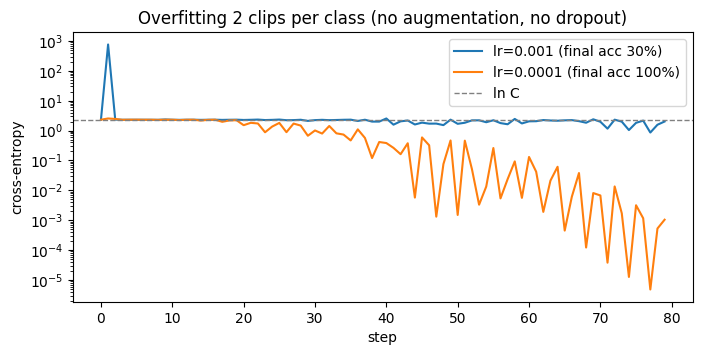

Using LR = 0.0001 (deviation from the assignment: 1e-3 failed this test; report it)


In [ ]:
import utils.dataset as vds, utils.engine as engine
importlib.reload(vds); importlib.reload(engine); importlib.reload(cnn3d)
import train_3dcnn
importlib.reload(train_3dcnn)

tiny = data[data.phase == 'train'].groupby('label').head(2)
tiny_ds = vds.UCF101Clips(tiny, LOCAL_CACHE, num_frames=T, train=False, crop=CROP)
tiny_dl = DataLoader(tiny_ds, batch_size=8, shuffle=False, num_workers=NUM_WORKERS)
tiny_batches = list(tiny_dl)                         # decode once, reuse every step

OVERFIT_STEPS = 80
overfit = {}
for lr in (1e-3, 1e-4):
    train_3dcnn.seed_everything(SEED)
    m = cnn3d.C3D(num_classes=N_CLASSES, dropout=0.0).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    losses = []
    m.train()
    for step in range(OVERFIT_STEPS):
        clips, labels = [t.to(DEVICE) for t in tiny_batches[step % len(tiny_batches)]]
        loss = F.cross_entropy(m(clips), labels)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    acc = engine.evaluate(m, tiny_dl, DEVICE)['top1']
    overfit[lr] = dict(losses=losses, acc=acc)
    print(f'lr={lr:g}: loss {losses[0]:.3f} -> {np.mean(losses[-5:]):.3f} | accuracy on the 20 clips {acc:.0%}')
    del m, opt
print(f'Uniform-guess loss ln({N_CLASSES}) = {math.log(N_CLASSES):.3f}')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

plt.figure(figsize=(8, 3.5))
for lr, r in overfit.items():
    plt.plot(r['losses'], label=f'lr={lr:g} (final acc {r["acc"]:.0%})')
plt.axhline(math.log(N_CLASSES), color='gray', ls='--', lw=1, label='ln C')
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('cross-entropy'); plt.legend()
plt.title('Overfitting 2 clips per class (no augmentation, no dropout)')
save_fig('part2_c3d_overfit_check'); plt.show()

passed = {lr: r['acc'] >= 0.9 for lr, r in overfit.items()}
assert any(passed.values()), 'Neither learning rate can memorize 20 clips: check labels and inputs before training'
LR = 1e-3 if passed[1e-3] else 1e-4
print(f'Using LR = {LR:g}' + (' (assignment default)' if LR == 1e-3
                              else ' (deviation from the assignment: 1e-3 failed this test; report it)'))

Train the baseline: C3D, label smoothing 0.1, 30 epochs (Exercise 7)

Hyperparameters follow Section 6.3 (Adam, weight decay 1e-4, cosine schedule, batch 8), with model selection on the validation split rather than the test set. If Colab disconnects, re-run 1.1–1.2, the setup cell, and this cell: training resumes from the last checkpoint.

In [ ]:
EPOCHS = 30
base_cfg = dict(subset=SUBSET, epochs=EPOCHS, lr=LR, batch_size=8, weight_decay=1e-4, dropout=0.5,
                num_workers=NUM_WORKERS, seed=SEED, meta_dir=DRIVE_META, cache_dir=LOCAL_CACHE,
                run_root=DRIVE_RUNS)
runs = {}

def train_ls(ls):
    """Train (or reload) one label-smoothing setting; keep only lightweight results in memory."""
    res = train_3dcnn.run({**base_cfg, 'label_smoothing': ls})
    runs[ls] = {k: res[k] for k in ('cfg', 'run_dir', 'history')}
    del res
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return runs[ls]

r = train_ls(0.1)
h = pd.DataFrame(r['history'])
b = h.val_top1.idxmax()
print(f'\nBest val top-1 {h.val_top1[b]:.3f} (top-5 {h.val_top5[b]:.3f}) at epoch {h.epoch[b]} | '
      f'{h.epoch_time.mean():.0f} s/epoch | run dir: {r["run_dir"]}')

Epoch   1/30 | loss 2.308 / 2.301 | top-1 0.094 / 0.128 | val top-5 0.544 | 17s  *best
Epoch   2/30 | loss 2.305 / 2.301 | top-1 0.124 / 0.128 | val top-5 0.550 | 14s
Epoch   3/30 | loss 2.303 / 2.302 | top-1 0.100 / 0.094 | val top-5 0.550 | 14s
Epoch   4/30 | loss 2.299 / 2.301 | top-1 0.115 / 0.094 | val top-5 0.523 | 15s
Epoch   5/30 | loss 2.300 / 2.300 | top-1 0.108 / 0.101 | val top-5 0.550 | 15s
Epoch   6/30 | loss 2.300 / 2.299 | top-1 0.114 / 0.128 | val top-5 0.537 | 15s
Epoch   7/30 | loss 2.299 / 2.299 | top-1 0.103 / 0.094 | val top-5 0.550 | 17s
Epoch   8/30 | loss 2.299 / 2.296 | top-1 0.101 / 0.128 | val top-5 0.550 | 15s
Epoch   9/30 | loss 2.295 / 2.299 | top-1 0.113 / 0.128 | val top-5 0.550 | 14s
Epoch  10/30 | loss 2.299 / 2.299 | top-1 0.114 / 0.128 | val top-5 0.550 | 15s
Epoch  11/30 | loss 2.297 / 2.298 | top-1 0.121 / 0.128 | val top-5 0.550 | 15s
Epoch  12/30 | loss 2.304 / 2.299 | top-1 0.119 / 0.094 | val top-5 0.550 | 15s
Epoch  13/30 | loss 2.295 / 2.299

Training curves

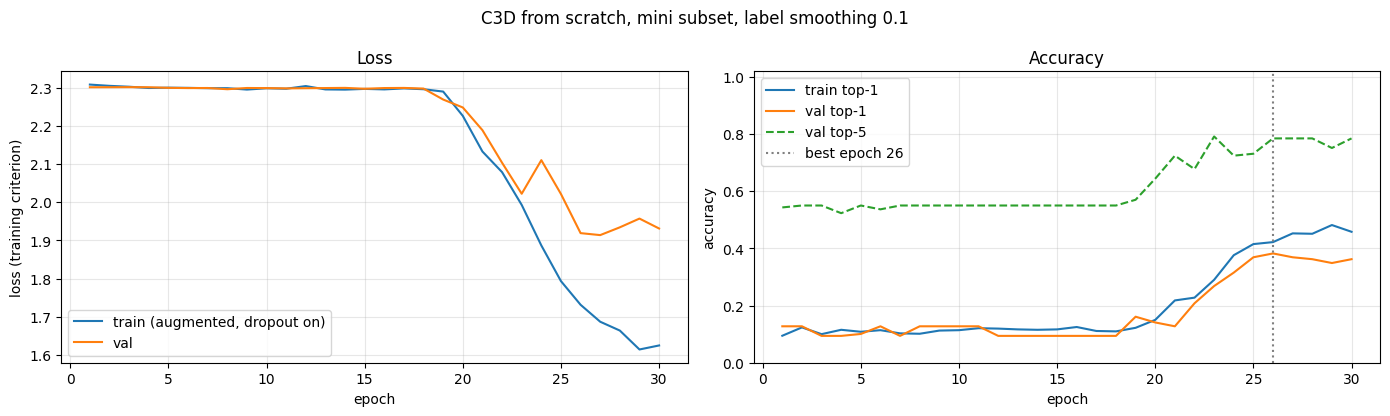

In [ ]:
def plot_curves(history, title, fname):
    h = pd.DataFrame(history)
    b = h.val_top1.idxmax()
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    ax[0].plot(h.epoch, h.train_loss, label='train (augmented, dropout on)')
    ax[0].plot(h.epoch, h.val_loss, label='val')
    ax[0].set(xlabel='epoch', ylabel='loss (training criterion)', title='Loss')
    ax[1].plot(h.epoch, h.train_top1, label='train top-1')
    ax[1].plot(h.epoch, h.val_top1, label='val top-1')
    ax[1].plot(h.epoch, h.val_top5, ls='--', label='val top-5')
    ax[1].axvline(h.epoch[b], color='gray', ls=':', label=f'best epoch {h.epoch[b]}')
    ax[1].set(xlabel='epoch', ylabel='accuracy', ylim=(0, 1.02), title='Accuracy')
    for a in ax:
        a.legend(); a.grid(alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

plot_curves(runs[0.1]['history'], f'C3D from scratch, {SUBSET} subset, label smoothing 0.1', 'part2_c3d_curves')

Label smoothing sweep {0.0, 0.1, 0.2} (Exercise 8)

Smoothing changes the training target itself, so the runs are compared on things it doesn't touch: val top-1, plain NLL, the train–val accuracy gap at the best epoch, and calibration (ECE: how far the model's confidence is from its actual accuracy). The 0.1 run is reused from the cell above.

Epoch   1/30 | loss 2.309 / 2.301 | top-1 0.093 / 0.128 | val top-5 0.530 | 15s  *best
Epoch   2/30 | loss 2.298 / 2.346 | top-1 0.119 / 0.128 | val top-5 0.564 | 14s
Epoch   3/30 | loss 2.302 / 2.301 | top-1 0.115 / 0.094 | val top-5 0.550 | 14s
Epoch   4/30 | loss 2.293 / 2.301 | top-1 0.118 / 0.094 | val top-5 0.550 | 15s
Epoch   5/30 | loss 2.285 / 2.291 | top-1 0.113 / 0.081 | val top-5 0.530 | 15s
Epoch   6/30 | loss 2.228 / 2.160 | top-1 0.178 / 0.228 | val top-5 0.671 | 15s  *best
Epoch   7/30 | loss 2.093 / 2.083 | top-1 0.261 / 0.188 | val top-5 0.678 | 15s
Epoch   8/30 | loss 2.073 / 1.968 | top-1 0.212 / 0.235 | val top-5 0.651 | 15s  *best
Epoch   9/30 | loss 1.908 / 1.866 | top-1 0.306 / 0.336 | val top-5 0.799 | 15s  *best
Epoch  10/30 | loss 1.788 / 1.700 | top-1 0.351 / 0.336 | val top-5 0.886 | 15s
Epoch  11/30 | loss 1.674 / 1.735 | top-1 0.392 / 0.336 | val top-5 0.812 | 15s
Epoch  12/30 | loss 1.576 / 1.788 | top-1 0.439 / 0.383 | val top-5 0.812 | 15s  *best
Epoch

,best_epoch,val_top1,val_top5,val_nll,val_ece,mean_confidence,train_top1_at_best,gap,s_per_epoch
label_smoothing,,,,,,,,,
0.0,20,0.557,0.899,1.663,0.161,0.716,0.819,0.262,14.988
0.1,26,0.383,0.785,1.762,0.094,0.390,0.422,0.040,15.075
0.2,23,0.564,0.859,1.397,0.118,0.472,0.635,0.071,15.079


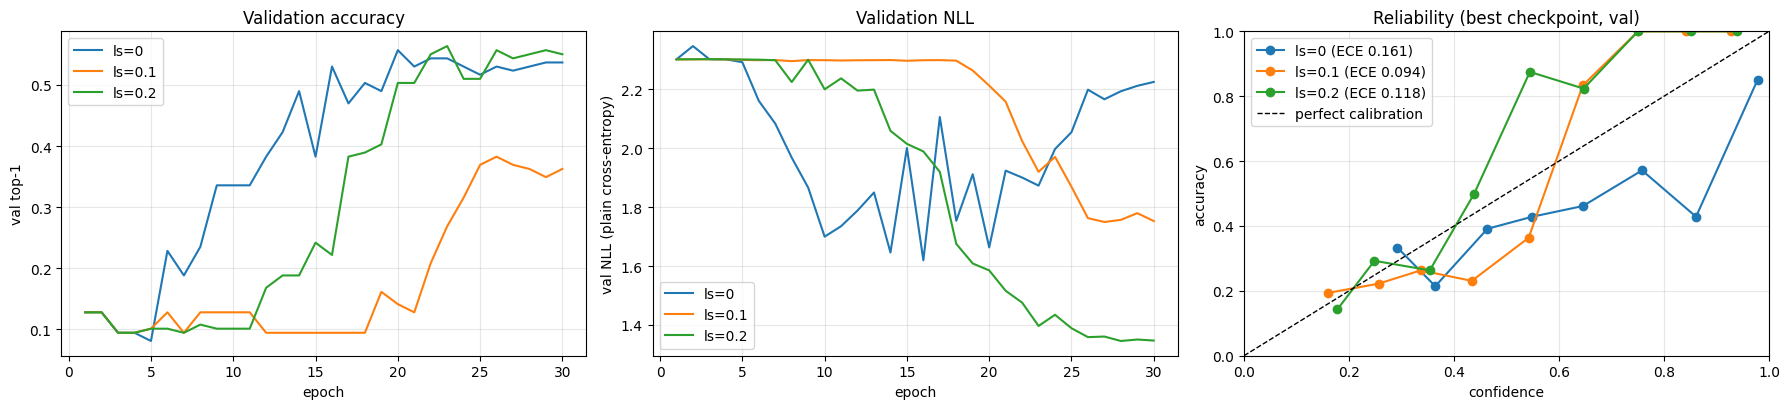

In [ ]:
LS_VALUES = (0.0, 0.1, 0.2)
for ls in LS_VALUES:
    if ls not in runs:
        train_ls(ls)

eval_ds = train_3dcnn.make_datasets(base_cfg)
eval_dl = {p: DataLoader(eval_ds[p], batch_size=16, shuffle=False, num_workers=NUM_WORKERS,
                         pin_memory=DEVICE.type == 'cuda') for p in ('val', 'test')}

def load_best(run_dir):
    m = cnn3d.C3D(num_classes=N_CLASSES).to(DEVICE)
    m.load_state_dict(torch.load(f'{run_dir}/best.pt', map_location=DEVICE, weights_only=True))
    return m.eval()

def calibration(logits, labels, n_bins=10):
    """Expected calibration error, plus per-bin (confidence, accuracy, count) for a reliability plot."""
    probs = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, n_bins + 1)
    bins, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            bins.append((conf[m].mean(), correct[m].mean(), m.sum()))
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return ece, conf.mean(), bins

rows, rel = [], {}
for ls in LS_VALUES:
    h = pd.DataFrame(runs[ls]['history'])
    b = h.val_top1.idxmax()
    m = load_best(runs[ls]['run_dir'])
    va = engine.evaluate(m, eval_dl['val'], DEVICE, return_logits=True)
    ece, mean_conf, rel[ls] = calibration(va['logits'], va['labels'])
    rows.append(dict(label_smoothing=ls, best_epoch=int(h.epoch[b]), val_top1=va['top1'], val_top5=va['top5'],
                     val_nll=va['nll'], val_ece=ece, mean_confidence=mean_conf,
                     train_top1_at_best=h.train_top1[b], gap=h.train_top1[b] - va['top1'],
                     s_per_epoch=h.epoch_time.mean()))
    log_result(model='C3D (scratch)', subset=SUBSET, variant=f'ls={ls:g}', split='val',
               top1=va['top1'], top5=va['top5'], nll=va['nll'], ece=ece, best_epoch=int(h.epoch[b]),
               s_per_epoch=h.epoch_time.mean(), **c3d_complexity)
    del m
sweep = pd.DataFrame(rows).set_index('label_smoothing')
display(sweep.round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for ls in LS_VALUES:
    h = pd.DataFrame(runs[ls]['history'])
    ax[0].plot(h.epoch, h.val_top1, label=f'ls={ls:g}')
    ax[1].plot(h.epoch, h.val_nll, label=f'ls={ls:g}')
    c, a, _ = zip(*rel[ls])
    ax[2].plot(c, a, marker='o', label=f'ls={ls:g} (ECE {sweep.val_ece[ls]:.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', lw=1, label='perfect calibration')
ax[0].set(xlabel='epoch', ylabel='val top-1', title='Validation accuracy')
ax[1].set(xlabel='epoch', ylabel='val NLL (plain cross-entropy)', title='Validation NLL')
ax[2].set(xlabel='confidence', ylabel='accuracy', title='Reliability (best checkpoint, val)', xlim=(0, 1), ylim=(0, 1))
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); save_fig('part2_label_smoothing_sweep'); plt.show()

What to look for: smoothing usually lowers mean confidence and narrows the train–val gap. Whether it helps top-1 on a dataset this small is an empirical question; the reliability curves show whether the model moved from over-confident (curve below the diagonal) toward calibrated, or past it into under-confident (curve above).

Final model: chosen on validation, evaluated on test once

Selection rule: highest val top-1, ties broken by lower val NLL. The test logits are saved for the per-class comparison in Part 4 (Exercise 24) and the evaluation in Part 5.

In [ ]:
BEST_LS = sweep.sort_values(['val_top1', 'val_nll'], ascending=[False, True]).index[0]
best_run = runs[BEST_LS]
model = load_best(best_run['run_dir'])
te = engine.evaluate(model, eval_dl['test'], DEVICE, return_logits=True)
ece_te, _, _ = calibration(te['logits'], te['labels'])
print(f'Selected label smoothing = {BEST_LS:g}')
print(f'TEST  top-1 {te["top1"]:.4f} | top-5 {te["top5"]:.4f} | NLL {te["nll"]:.3f} | ECE {ece_te:.3f}')
print(f'(val  top-1 {sweep.val_top1[BEST_LS]:.4f}: a large val/test gap would mean the val groups are unrepresentative)')

class_names = eval_ds['test'].class_names
pred = te['logits'].argmax(1)
per_class = (pd.DataFrame({'class': np.array(class_names)[te['labels']], 'correct': pred == te['labels']})
               .groupby('class').correct.agg(['mean', 'size']).rename(columns={'mean': 'acc', 'size': 'n'})
               .sort_values('acc'))
print('\nPer-class test accuracy (worst first):')
print(per_class.round(3).to_string())

suffix = '' if SUBSET == 'full' else f'_{SUBSET}'
np.savez(f'{DRIVE_ROOT}/results/c3d{suffix}_test_logits.npz', logits=te['logits'], labels=te['labels'],
         class_names=np.array(class_names), rel_path=eval_ds['test'].df.rel_path.values)
torch.save(model.state_dict(), f'{CODE_DIR}/models/c3d_ucf101{suffix}.pt')    # deliverable 11.2
log_result(model='C3D (scratch)', subset=SUBSET, variant=f'ls={BEST_LS:g} (selected)', split='test',
           top1=te['top1'], top5=te['top5'], nll=te['nll'], ece=ece_te,
           best_epoch=int(sweep.best_epoch[BEST_LS]), s_per_epoch=sweep.s_per_epoch[BEST_LS], **c3d_complexity)
print('\nSaved checkpoint, test logits, and results.csv')
pd.read_csv(RESULTS_CSV)

Selected label smoothing = 0.2
TEST  top-1 0.3392 | top-5 0.7895 | NLL 2.021 | ECE 0.053
(val  top-1 0.5638: a large val/test gap would mean the val groups are unrepresentative)

Per-class test accuracy (worst first):
                    acc   n
class                      
PushUps           0.000  30
HandstandWalking  0.147  34
BabyCrawling      0.171  35
Archery           0.195  41
WalkingWithDog    0.306  36
YoYo              0.361  36
PullUps           0.393  28
Fencing           0.412  34
Basketball        0.486  35
Surfing           0.939  33

Saved checkpoint, test logits, and results.csv


,model,subset,variant,split,top1,top5,nll,ece,best_epoch,s_per_epoch,params_M,gmacs
0,C3D (scratch),mini,ls=0,val,0.557047,0.899329,1.663115,0.160620,20.0,14.988038,63.36,38.56
1,C3D (scratch),mini,ls=0.1,val,0.382550,0.785235,1.762375,0.093716,26.0,15.074711,63.36,38.56
2,C3D (scratch),mini,ls=0.2,val,0.563758,0.859060,1.396669,0.118304,23.0,15.078910,63.36,38.56
3,C3D (scratch),mini,ls=0.2 (selected),test,0.339181,0.789474,2.020667,0.053093,23.0,15.078910,63.36,38.56


Step 5 checklist
- [ ] Tensor shapes traced through all 5 pooling stages; receptive field table saved for Q11
- [ ] Parameter and MAC counts recorded (Exercise 10, C3D half)
- [ ] Overfit smoke test passed; learning rate decision recorded
- [ ] `evaluate()` with top-1 / top-5 in `utils/engine.py` (Exercise 6)
- [ ] 30-epoch curves saved: `part2_c3d_curves.png` (Exercise 7)
- [ ] Label-smoothing table and figure: `part2_label_smoothing_sweep.png` (Exercise 8)
- [ ] Test evaluated once; `models/c3d_ucf101_mini.pt`, test logits, and `results.csv` saved

Next — Step 6: pretrained R(2+1)D-18 from torchvision, fine-tune only the head for 10 epochs (Kinetics normalization), and finish Exercise 10 with a side-by-side parameter/MAC/accuracy table against this C3D.

## Step 6 — Pretrained R(2+1)D-18: fine-tune only the head (Part 2: Exercises 9–10; Reflection Q12)

**Goal:** check how far *transferred* video features get without learning any of them on UCF101. The 63 M-parameter C3D above was trained from scratch on 721 clips (≈ 18 source videos per class).

| Decision | Choice | Why |
|---|---|---|
| Weights | `R2Plus1D_18_Weights.KINETICS400_V1` | `pretrained=True` (assignment template) is deprecated in torchvision |
| What trains | the new `fc` (512 → 10) only | Exercise 9 asks for the head only. It's a *linear probe*: it measures how separable UCF101 already is in Kinetics feature space |
| Frozen BatchNorm | backbone kept in eval mode | otherwise `model.train()` would overwrite the Kinetics BN statistics with noisy estimates from batches of 8 |
| Input size | same frame cache: 128×171 → crop 112, T=16 | torchvision trained this model on 16-frame 112×112 crops of 128×171 frames, so no new cache is needed |
| Normalization | **Kinetics** mean / std (Step 3.4 table) | pretrained filters expect the statistics they were trained on |
| Optimizer | Adam, lr **1e-3**, weight decay 1e-4, cosine, batch 8, **10 epochs** | 1e-3 failed for C3D because of its large randomly initialized FC stack. A single linear layer on fixed features is a convex problem, and 1e-3 is the assignment's value |
| Label smoothing | the value selected for C3D in Step 5 | same recipe, so the comparison isolates architecture + pretraining + normalization |

One mismatch to keep in mind for Q12: torchvision's training clips are 16 *nearly consecutive* frames (about 1 s of video), while our segment sampling spreads 16 frames over the whole clip (median 0.43 s apart). The pretrained temporal filters therefore see motion at a coarser time scale than they were trained on.

> `models/cnn3d.py` and `train_3dcnn.py` gained the R(2+1)D option. **Re-run their two `%%writefile` cells in Step 5 first**, then the cells below. The C3D run names are unchanged, so finished C3D runs reload in seconds instead of retraining.

In [ ]:
# ---- Session check. Step 5's setup cell defines the paths and puts the code folder on the import
# path; in a new Colab session (disconnect, restart, reopened notebook) nothing above has run yet.
import os, sys
if 'CODE_DIR' not in globals():
    raise RuntimeError('New Colab session: click this cell, then Runtime -> "Run before" to re-run everything '
                       'above it. Finished training runs reload from Drive instead of retraining.')
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

import models.cnn3d as cnn3d, utils.dataset as vds, utils.engine as engine
import torchinfo                                       # installed in Step 5
import train_3dcnn
for mod in (cnn3d, vds, engine, train_3dcnn):          # dependencies before the script that imports them
    importlib.reload(mod)
assert hasattr(cnn3d, 'PretrainedR2Plus1D'), 'Re-run the %%writefile cells for models/cnn3d.py and train_3dcnn.py'

# Step 5 results this step compares against. After a disconnect, re-run Step 5's cells:
# finished runs reload from Drive instead of retraining.
missing = [v for v in ('base_cfg', 'runs', 'sweep', 'BEST_LS', 'te', 'ece_te', 'c3d_complexity',
                       'load_best', 'calibration', 'plot_curves') if v not in globals()]
assert not missing, f'Run the Step 5 cells first (missing: {missing})'

R2_EPOCHS, R2_LR = 10, 1e-3
r2_cfg = {**base_cfg, 'model': 'r2plus1d', 'finetune': 'head', 'epochs': R2_EPOCHS, 'lr': R2_LR,
          'label_smoothing': float(BEST_LS)}

# Build once to inspect: what is frozen, and what does it cost (Exercise 10, R(2+1)D half)
r2 = train_3dcnn.build_model(r2_cfg, N_CLASSES).to(DEVICE)
summ = torchinfo.summary(r2, input_size=(1, 3, T, CROP, CROP), depth=2, verbose=0,
                         col_names=('output_size', 'num_params', 'mult_adds'))
print(summ)
r2_complexity = dict(params_M=round(summ.total_params / 1e6, 2), gmacs=round(summ.total_mult_adds / 1e9, 2))
r2_trainable_M = sum(p.numel() for p in r2.parameters() if p.requires_grad) / 1e6
print(f'\nParams: {r2_complexity["params_M"]} M total, {r2_trainable_M * 1e3:.1f} K trainable '
      f'({r2_trainable_M / r2_complexity["params_M"]:.3%}) | {r2_complexity["gmacs"]} GMACs per clip '
      f'(~{2 * r2_complexity["gmacs"]:.0f} GFLOPs)')

# Frozen BatchNorm must stay in eval mode even after model.train()
r2.train()
bn_updating = [n for n, m in r2.named_modules() if isinstance(m, torch.nn.BatchNorm3d) and m.training]
assert not bn_updating, f'Frozen BatchNorm layers would update their statistics: {bn_updating[:3]}'
assert r2.net.fc.training, 'the head should be in train mode'
print('Frozen backbone stays in eval mode; only fc trains')
del r2
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Train the head for 10 epochs (Exercise 9)

Only the 5 K-parameter head receives gradients, so autograd stores no backbone activations and an epoch costs little more than a forward pass. Epoch-1 val loss should already be well below ln(10) = 2.30; C3D sat at that value for its first ~10–18 epochs.

In [ ]:
res = train_3dcnn.run(r2_cfg)
r2_run = {k: res[k] for k in ('cfg', 'run_dir', 'history')}
r2_model = res['model'].eval()
del res

r2_h = pd.DataFrame(r2_run['history'])
b = r2_h.val_top1.idxmax()
print(f'\nBest val top-1 {r2_h.val_top1[b]:.3f} (top-5 {r2_h.val_top5[b]:.3f}) at epoch {r2_h.epoch[b]} | '
      f'{r2_h.epoch_time.mean():.0f} s/epoch | run dir: {r2_run["run_dir"]}')
plot_curves(r2_run['history'], f'R(2+1)D-18 (Kinetics-400), head only, {SUBSET} subset, '
            f'label smoothing {BEST_LS:g}', 'part2_r2plus1d_curves')

Evaluate on validation, then test once

There is only one R(2+1)D configuration, so `best.pt` (chosen on val top-1) is the final model. The test clips are the same, in the same order, as for C3D, so the per-class comparison is clip-for-clip.

In [ ]:
r2_eval_ds = train_3dcnn.make_datasets(r2_cfg)                 # Kinetics-normalized, deterministic eval view
r2_eval_dl = {p: DataLoader(r2_eval_ds[p], batch_size=16, shuffle=False, num_workers=NUM_WORKERS,
                            pin_memory=DEVICE.type == 'cuda') for p in ('val', 'test')}
r2_va = engine.evaluate(r2_model, r2_eval_dl['val'], DEVICE, return_logits=True)
r2_te = engine.evaluate(r2_model, r2_eval_dl['test'], DEVICE, return_logits=True)
r2_ece_va, _, _ = calibration(r2_va['logits'], r2_va['labels'])
r2_ece_te, _, _ = calibration(r2_te['logits'], r2_te['labels'])
assert (r2_te['labels'] == te['labels']).all(), 'test clips differ from the C3D evaluation'

print(f'VAL   top-1 {r2_va["top1"]:.4f} | top-5 {r2_va["top5"]:.4f} | NLL {r2_va["nll"]:.3f} | ECE {r2_ece_va:.3f}')
print(f'TEST  top-1 {r2_te["top1"]:.4f} | top-5 {r2_te["top5"]:.4f} | NLL {r2_te["nll"]:.3f} | ECE {r2_ece_te:.3f}')
print(f'C3D   top-1 {te["top1"]:.4f} | top-5 {te["top5"]:.4f} | NLL {te["nll"]:.3f} | ECE {ece_te:.3f}  (Step 5, test)')

R2_NAME = 'R(2+1)D-18 (Kinetics, head only)'
r2_best_epoch, r2_s_epoch = int(r2_h.epoch[r2_h.val_top1.idxmax()]), r2_h.epoch_time.mean()
log_result(model=R2_NAME, subset=SUBSET, variant=f'ls={BEST_LS:g}', split='val', top1=r2_va['top1'],
           top5=r2_va['top5'], nll=r2_va['nll'], ece=r2_ece_va, best_epoch=r2_best_epoch,
           s_per_epoch=r2_s_epoch, **r2_complexity)
log_result(model=R2_NAME, subset=SUBSET, variant=f'ls={BEST_LS:g} (selected)', split='test', top1=r2_te['top1'],
           top5=r2_te['top5'], nll=r2_te['nll'], ece=r2_ece_te, best_epoch=r2_best_epoch,
           s_per_epoch=r2_s_epoch, **r2_complexity)

# Clip-for-clip per-class comparison (evidence for Q12: which classes does pretraining fix?)
class_names = r2_eval_ds['test'].class_names
per_class_cmp = (pd.DataFrame({'class': np.array(class_names)[te['labels']],
                               'C3D': te['logits'].argmax(1) == te['labels'],
                               'R(2+1)D': r2_te['logits'].argmax(1) == r2_te['labels']})
                 .groupby('class').mean())
per_class_cmp['gain'] = per_class_cmp['R(2+1)D'] - per_class_cmp['C3D']
print('\nPer-class test accuracy (largest gain first):')
print(per_class_cmp.sort_values('gain', ascending=False).round(3).to_string())

suffix = '' if SUBSET == 'full' else f'_{SUBSET}'
np.savez(f'{DRIVE_ROOT}/results/r2plus1d{suffix}_test_logits.npz', logits=r2_te['logits'], labels=r2_te['labels'],
         class_names=np.array(class_names), rel_path=r2_eval_ds['test'].df.rel_path.values)
torch.save(r2_model.state_dict(), f'{CODE_DIR}/models/r2plus1d_ucf101{suffix}.pt')
print('\nSaved checkpoint, test logits, and results.csv')

Exercise 10: complexity vs. accuracy, side by side

Parameters and multiply-accumulates (MACs) come from `torchinfo` (1 MAC ≈ 2 FLOPs). Inference time is measured on this GPU with batch 8 and fp16, the same setting as training, so it reflects real throughput rather than a single-clip latency. Training cost is the wall-clock time each model actually needed.

In [ ]:
def inference_ms(model, bs=8, n_iter=20):
    """Average forward time per clip (ms) on random input, after warm-up."""
    model.eval()
    x = torch.randn(bs, 3, T, CROP, CROP, device=DEVICE)
    sync = torch.cuda.synchronize if DEVICE.type == 'cuda' else (lambda: None)
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
        for _ in range(3):
            model(x)
        sync()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            model(x)
        sync()
    return (time.perf_counter() - t0) / (n_iter * bs) * 1000

c3d_model = load_best(runs[BEST_LS]['run_dir'])
c3d_h = pd.DataFrame(runs[BEST_LS]['history'])
ex10 = pd.DataFrame([
    dict(model='C3D', pretraining='none', trained='all layers',
         params_M=c3d_complexity['params_M'], trainable_M=c3d_complexity['params_M'],
         gmacs=c3d_complexity['gmacs'], gflops=2 * c3d_complexity['gmacs'],
         infer_ms_per_clip=inference_ms(c3d_model), epochs=len(c3d_h),
         s_per_epoch=c3d_h.epoch_time.mean(), train_min=c3d_h.epoch_time.sum() / 60,
         val_top1=sweep.val_top1[BEST_LS], test_top1=te['top1'], test_top5=te['top5'],
         test_nll=te['nll'], test_ece=ece_te),
    dict(model='R(2+1)D-18', pretraining='Kinetics-400', trained='fc only',
         params_M=r2_complexity['params_M'], trainable_M=r2_trainable_M,
         gmacs=r2_complexity['gmacs'], gflops=2 * r2_complexity['gmacs'],
         infer_ms_per_clip=inference_ms(r2_model), epochs=len(r2_h),
         s_per_epoch=r2_h.epoch_time.mean(), train_min=r2_h.epoch_time.sum() / 60,
         val_top1=r2_va['top1'], test_top1=r2_te['top1'], test_top5=r2_te['top5'],
         test_nll=r2_te['nll'], test_ece=r2_ece_te),
]).set_index('model')
del c3d_model
ex10.to_csv(f'{DRIVE_ROOT}/results/part2_ex10_complexity_vs_accuracy{suffix}.csv')
display(ex10.round(4))

# Figure: cost (left) vs. what it buys (right). One color per model, same in both panels.
COLORS = {'C3D': '#2a78d6', 'R(2+1)D-18': '#eb6834'}
names = list(ex10.index)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
panels = [('params_M', 'Parameters (M)', 'Total parameters'),
          ('gmacs', 'GMACs per clip', 'Compute per 16x112x112 clip'),
          ('test_top1', 'Test top-1 accuracy', 'Test accuracy (top-1)')]
for a, (col, ylabel, title) in zip(ax, panels):
    vals = ex10[col].values
    bars = a.bar(names, vals, width=0.5, color=[COLORS[n] for n in names])
    a.bar_label(bars, labels=[f'{v:.3f}' if col == 'test_top1' else f'{v:.1f}' for v in vals],
                padding=3, color='#333333', fontsize=10)
    a.set(ylabel=ylabel, title=title)
    a.set_ylim(0, (1.0 if col == 'test_top1' else vals.max()) * 1.15)
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis='y', alpha=0.3); a.set_axisbelow(True)
# Trainable share drawn inside the parameter bars (hatched) so "trainable" isn't conveyed by color alone
ax[0].bar(names, ex10.trainable_M.values, width=0.5, color='none', edgecolor='white', hatch='//', lw=0,
          label='trainable')
ax[0].legend(frameon=False, loc='upper right')
plt.suptitle(f'Exercise 10: C3D from scratch vs. pretrained R(2+1)D-18, head only ({SUBSET} subset)')
plt.tight_layout(); save_fig('part2_ex10_complexity_vs_accuracy'); plt.show()

**What to look for (Exercise 9–10, Q12)**

- **Accuracy per unit of training.** The R(2+1)D head trains under 0.02 % of the parameters, for a third of the epochs. If it still beats C3D by a wide margin, the gap comes from the *features*, not from more fitting capacity. UCF101's ~18 independent source videos per class can't teach general spatiotemporal filters from scratch; 240 K Kinetics videos can, and actions in the two datasets share low- and mid-level structure (edges, limbs, motion patterns), so the features transfer.
- **Parameters ≠ compute.** C3D has about 2× the parameters, but most sit in fc6/fc7, which cost almost no MACs. So the compute gap per clip can be much smaller than the parameter gap, or even reversed. Parameter count alone is a poor proxy for speed: compare the `gmacs` and `infer_ms_per_clip` columns.
- **Per-class table.** Classes where C3D was near 0 (e.g. PushUps) and R(2+1)D recovers point to appearance and motion knowledge the small dataset couldn't supply. Classes where neither does well are candidates for the confusion analysis in Part 5.
- **Val vs. test.** C3D's selected run scored much higher on val than on test (0.56 vs 0.34), so with only ~15 val clips per class, single-run val numbers are noisy. If R(2+1)D's val and test agree closely, that's a sign its predictions depend less on which clips were sampled.
- **Optional follow-up:** `finetune='layer4'` with `lr=1e-4` adapts the last residual stage too. It usually gains a few more points and is a natural middle ground between a linear probe and full fine-tuning.

Step 6 checklist
- [ ] Re-ran the `models/cnn3d.py` and `train_3dcnn.py` `%%writefile` cells (Step 5) before this step
- [ ] Frozen-BatchNorm check passed; trainable parameters = head only
- [ ] 10-epoch curves saved: `part2_r2plus1d_curves.png` (Exercise 9)
- [ ] Val and test evaluated; `models/r2plus1d_ucf101_mini.pt`, test logits, and `results.csv` rows saved
- [ ] Exercise 10 table `part2_ex10_complexity_vs_accuracy_mini.csv` and figure `part2_ex10_complexity_vs_accuracy.png` saved
- [ ] Per-class gain table noted for the Q12 answer

Next — Step 7: Siamese network for video similarity (Part 3: Exercises 14–17).

## Step 7 — Siamese network for video similarity (Part 3: Exercises 14–17; Reflection Q18–Q20)

**Goal:** learn an embedding where clips of the same action are close and different actions are far apart, then use it to recognize **classes the network has never seen** from 1 or 5 examples.

| Decision | Choice | Why |
|---|---|---|
| Base vs. novel classes | Train on the 10 mini classes; evaluate few-shot on **20 other UCF101 classes** (their test-split clips) | Section 7.5 needs classes held out from training. Holding out 5 of the 10 mini classes would leave 5 training classes, and every 5-way episode would be the same 5-class task. With a pool of 20 novel classes, each episode is a different task. The novel classes are never used for training *or* model selection |
| Encoder initialization | conv layers of Step 5's selected C3D; new projection head | From scratch, C3D needed ~18 epochs just to leave chance level, so a from-scratch Siamese run would mostly measure optimization difficulty. C3D was trained on the base classes only, so the novel classes stay unseen. `init_c3d=None` trains from scratch |
| Embedding | 512-d, **L2-normalized** (Section 7.2) | All distances lie in [0, 2]; two random unit vectors in 512-d are ≈ √2 ≈ 1.41 apart (Q18). This fixes what a margin means |
| Pairs per epoch | **1 000** (template: 10 000), 50/50 balance, batch 8 pairs | 1 000 pairs = 2 000 clip passes ≈ 45 s/epoch on a T4, so ~15 min per 20-epoch run. 10 000 would take ~2.5 h per run, ×4 runs. 1 000 pairs still show each of the 721 training clips ~3× per epoch |
| Optimizer | Adam lr 1e-4, weight decay 1e-4, cosine, 20 epochs | lr 1e-4 is what worked for C3D in Step 5 |
| Model selection | **ROC AUC** on 600 fixed pairs of base-class *val* clips (groups 8–10) | AUC doesn't depend on the distance scale, so it compares fairly across margins and losses |
| Few-shot protocol | 5-way, K = 1 and 5, 15 queries/class, 200 episodes; **same episodes for every model**; queries from different groups than supports | Embeddings are computed once (not per episode as in the template). Identical episodes make model differences paired comparisons, and the group rule stops a query from matching a near-duplicate support clip |
| Triplet (Ex. 17) | margin 0.2 (FaceNet's value on the unit sphere), same number of clips per step and per epoch | equal compute, so only the loss differs |

> Step 7 adds `PairDataset` and `TripletDataset` to `utils/dataset.py`. **Re-run the `utils/dataset.py` `%%writefile` cell in Step 3 first.** Building the novel-class frame cache (once, about 750 clips, backed up to Drive) needs the raw videos, so in a fresh session also run Steps 1.1–1.4 and the Step 3 cache-helper cell before the cell below.

In [ ]:
# ---- Session check. Step 5's setup cell defines the paths and puts the code folder on the import
# path; in a new Colab session (disconnect, restart, reopened notebook) nothing above has run yet.
import os, sys
if 'CODE_DIR' not in globals():
    raise RuntimeError('New Colab session: click this cell, then Runtime -> "Run before" to re-run everything '
                       'above it. Finished training runs reload from Drive instead of retraining.')
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
import utils.dataset as vds, utils.engine as engine, models.cnn3d as cnn3d
import train_3dcnn
for mod in (vds, engine, cnn3d, train_3dcnn):          # dependencies before the scripts that import them
    importlib.reload(mod)
assert hasattr(vds, 'PairDataset'), 'Re-run the %%writefile cell for utils/dataset.py (Step 3) first'
missing = [v for v in ('base_cfg', 'runs', 'BEST_LS', 'load_best', 'cache_path') if v not in globals()]
assert not missing, f'Run the Step 5 cells first (missing: {missing})'

C3D_INIT = f"{runs[BEST_LS]['run_dir']}/best.pt"      # Step 5's selected C3D (base classes only)

# ---- Novel classes: no model in this notebook trains on them or uses them for selection
N_NOVEL = 20
splits_full = pd.read_csv(f'{DRIVE_META}/splits_full.csv')
base_classes = sorted(data.class_name.unique())
novel_pool = sorted(set(splits_full.class_name) - set(base_classes))
assert len(novel_pool) >= N_NOVEL, 'SUBSET=full leaves no unseen classes: hold out classes from training instead'
NOVEL_CLASSES = sorted(random.Random(SEED).sample(novel_pool, N_NOVEL))
novel = splits_full[splits_full.class_name.isin(NOVEL_CLASSES) & (splits_full.phase == 'test')].copy()
novel['orig_label'] = novel.label
novel['label'] = novel.class_name.map({c: i for i, c in enumerate(NOVEL_CLASSES)})
novel = novel.reset_index(drop=True)
NOVEL_CSV = f'{DRIVE_META}/novel_{SUBSET}.csv'
novel.to_csv(NOVEL_CSV, index=False)                     # train_siamese.py reads this file
print(f'Base classes ({len(base_classes)}): {base_classes}')
print(f'Novel classes ({N_NOVEL}): {NOVEL_CLASSES}')
per_cls = novel.groupby('class_name').agg(clips=('rel_path', 'size'), groups=('group', 'nunique'))
print(f'Novel clips: {len(novel)} | per class {per_cls.clips.min()}-{per_cls.clips.max()} clips '
      f'from {per_cls.groups.min()}-{per_cls.groups.max()} groups')

# ---- Frame cache for the novel clips: restore from Drive, else build once and back up
NOVEL_TAR = f'{DRIVE_CACHE}/{CACHE_NAME}_novel{N_NOVEL}_seed{SEED}.tar'
def novel_cached():
    return all(os.path.exists(cache_path(r)) for r in novel.rel_path)

if not novel_cached() and os.path.exists(NOVEL_TAR):
    print('Restoring novel-class cache from Drive...')
    subprocess.run(['tar', '-xf', NOVEL_TAR, '-C', LOCAL_DATA], check=True)
todo = [(r, n) for r, n in zip(novel.rel_path, novel.n_frames) if not os.path.exists(cache_path(r))]
if todo:
    assert 'build_clip_cache' in globals() and 'VIDEO_DIR' in globals() and os.path.isdir(VIDEO_DIR), (
        'Building the novel cache needs the raw videos and the Step 3 helpers: '
        'run Steps 1.1-1.4 and the Step 3 cache-helper cell first')
    t0 = time.perf_counter()
    with ThreadPoolExecutor(max_workers=min(8, 2 * os.cpu_count())) as ex:
        status = list(tqdm(ex.map(lambda a: build_clip_cache(*a), todo), total=len(todo), desc='Caching novel'))
    print(pd.Series(status).value_counts().to_string())
    print(f'Built {len(todo)} clips in {(time.perf_counter() - t0) / 60:.1f} min')
    subprocess.run(['tar', '-cf', NOVEL_TAR, '-C', LOCAL_DATA] + [f'{CACHE_NAME}/{c}' for c in NOVEL_CLASSES],
                   check=True)
    print(f'Backed up to {NOVEL_TAR} ({os.path.getsize(NOVEL_TAR) / 1e9:.2f} GB)')
assert novel_cached(), 'novel-class cache incomplete'
print(f'All {len(novel)} novel clips cached')

Write models/siamese.py: the Siamese network (Section 7.2), contrastive loss (Section 7.3) and triplet loss (Exercise 17)

Two changes from the template: both clips go through the shared encoder in **one** batched pass (same weights, same gradients, faster), and the encoder can be initialized from a trained C3D.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/models/siamese.py
"""Siamese network for video similarity: shared C3D encoder, contrastive and triplet losses."""
import torch
import torch.nn as nn
import torch.nn.functional as F

from models.cnn3d import C3D


def pair_distance(z1, z2):
    """Euclidean distance per row; the epsilon keeps the sqrt gradient finite at d = 0."""
    return torch.sqrt(((z1 - z2) ** 2).sum(dim=1) + 1e-8)


class VideoSiamese(nn.Module):
    """Siamese network for video similarity (Section 7.2).

    One C3D encoder (shared weights) -> projection head -> L2-normalized embedding.
    Input : two clips (B, 3, T, H, W)
    Output: Euclidean distance (B,) in [0, 2]; small = similar, large = dissimilar
    """

    def __init__(self, embed_dim=512, dropout=0.5):
        super().__init__()
        backbone = C3D(num_classes=1)                 # num_classes unused: only .features is kept
        self.encoder = backbone.features              # spatiotemporal feature extractor
        self.projector = nn.Sequential(
            nn.Flatten(),
            nn.Linear(backbone.feat_dim, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, embed_dim),
        )
        self.embed_dim = embed_dim

    def encode(self, x):
        """L2-normalized embedding of a batch of clips (always float32, also under autocast)."""
        return F.normalize(self.projector(self.encoder(x)).float(), p=2, dim=1)

    get_embedding = encode                            # name the t-SNE code in Part 5 expects

    def encode_many(self, *clips):
        """Embed several equally sized batches in ONE pass through the shared encoder.

        Same weights, twice (or three times) the batch: this is what "twin networks" means in practice.
        """
        return self.encode(torch.cat(clips)).chunk(len(clips))

    def forward(self, x1, x2):
        z1, z2 = self.encode_many(x1, x2)
        return pair_distance(z1, z2)

    def similarity(self, x1, x2):
        """Cosine similarity in [-1, 1]. On unit vectors, d^2 = 2 - 2 cos, so both rank pairs identically."""
        z1, z2 = self.encode_many(x1, x2)
        return F.cosine_similarity(z1, z2)

    def load_c3d_features(self, c3d_state_dict):
        """Initialize the shared encoder from a trained C3D checkpoint (its `features.*` weights)."""
        feats = {k[len('features.'):]: v for k, v in c3d_state_dict.items() if k.startswith('features.')}
        self.encoder.load_state_dict(feats)


class ContrastiveLoss(nn.Module):
    """Hadsell et al. (2006), Section 7.3.

    L = (1 - y) * 0.5 * d^2 + y * 0.5 * max(0, margin - d)^2
    y = 0 -> same class (pull together); y = 1 -> different class (push apart, up to the margin)
    """

    def __init__(self, margin=2.0):
        super().__init__()
        self.margin = margin

    def forward(self, dist, label):
        similar_loss = (1 - label) * 0.5 * dist.pow(2)
        dissim_loss = label * 0.5 * torch.clamp(self.margin - dist, min=0).pow(2)
        return (similar_loss + dissim_loss).mean()


class TripletLoss(nn.Module):
    """Schroff et al. (2015): L = max(0, d(a, p) - d(a, n) + margin).

    Only the ORDER of distances matters (positive closer than negative by the margin),
    not their absolute values as in the contrastive loss.
    """

    def __init__(self, margin=0.2):
        super().__init__()
        self.margin = margin

    def forward(self, d_ap, d_an):
        return F.relu(d_ap - d_an + self.margin).mean()


Write train_siamese.py: the deliverable training script. It also holds the few-shot evaluation (Exercise 15), which runs on embeddings computed once.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/train_siamese.py
"""Part 3: train the Siamese network (contrastive or triplet loss) and evaluate few-shot matching.

Trains on the subset's base classes (train split; model selection on the val split) and evaluates
N-way K-shot on the novel classes listed in <meta_dir>/novel_<subset>.csv, which no model has seen.

Usage (from the code/ folder, once the caches exist):
    python train_siamese.py --subset mini --loss contrastive --margin 1.0 --init-c3d <c3d run>/best.pt
    python train_siamese.py --subset mini --loss triplet --margin 0.2 --init-c3d <c3d run>/best.pt
The notebook imports run(), embed_dataset() and few_shot_eval() from this file.
"""
import argparse
import json
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader

from models.siamese import ContrastiveLoss, TripletLoss, VideoSiamese, pair_distance
from train_3dcnn import make_datasets, seed_everything
from utils.dataset import PairDataset, TripletDataset, UCF101Clips
from utils.engine import _atomic_save, _autocast

DRIVE_ROOT = '/content/drive/MyDrive/videosense'
DEFAULTS = dict(subset='mini', loss='contrastive', margin=1.0, epochs=20, batch_size=8, lr=1e-4,
                weight_decay=1e-4, embed_dim=512, dropout=0.5, pairs_per_epoch=1000, pos_fraction=0.5,
                val_pairs=600, num_workers=2, seed=42, amp=True, init_c3d=None,
                meta_dir=f'{DRIVE_ROOT}/metadata', cache_dir=None, run_root=f'{DRIVE_ROOT}/runs',
                name=None)


def run_name(cfg):
    if cfg['name']:
        return cfg['name']
    init = 'c3dinit' if cfg['init_c3d'] else 'scratch'
    pos = '' if cfg['pos_fraction'] == 0.5 else f"_pos{cfg['pos_fraction']:g}"
    return f"siam_{cfg['subset']}_{cfg['loss']}_m{cfg['margin']:g}_{init}{pos}"


@torch.no_grad()
def embed_dataset(embed_fn, dataset, device, batch_size=16, num_workers=2, amp=True):
    """Embed every clip of a dataset -> (N, D) float32, L2-normalized. Put the model in eval mode first."""
    device = torch.device(device)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers,
                        pin_memory=device.type == 'cuda')
    out = []
    for clips, _ in loader:
        with _autocast(device, amp):
            z = embed_fn(clips.to(device, non_blocking=True))
        out.append(F.normalize(z.float(), dim=1).cpu())
    return torch.cat(out).numpy()


def fixed_pairs(labels, n_pairs, seed):
    """Balanced evaluation pairs as rows (i, j, y): y = 0 same class, y = 1 different classes."""
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    by_cls = {c: np.flatnonzero(labels == c) for c in np.unique(labels)}
    classes = list(by_cls)
    rows = []
    for k in range(n_pairs):
        if k % 2 == 0:
            i, j = rng.choice(by_cls[rng.choice(classes)], 2, replace=False)
            rows.append((i, j, 0))
        else:
            c1, c2 = rng.choice(classes, 2, replace=False)
            rows.append((rng.choice(by_cls[c1]), rng.choice(by_cls[c2]), 1))
    return np.array(rows)


def pair_metrics(Z, pairs, margin=None):
    """Distances of fixed pairs + ROC AUC (how well distance separates same from different class)."""
    d = np.linalg.norm(Z[pairs[:, 0]] - Z[pairs[:, 1]], axis=1)
    y = pairs[:, 2]
    out = dict(val_auc=float(roc_auc_score(y, d)), val_d_pos=float(d[y == 0].mean()),
               val_d_neg=float(d[y == 1].mean()), val_loss=float('nan'))
    if margin is not None:
        out['val_loss'] = ContrastiveLoss(margin)(torch.from_numpy(d), torch.from_numpy(y).float()).item()
    return out, d


def train_one_epoch(model, loader, criterion, loss_type, optimizer, scaler, device, amp=True):
    model.train()
    n, total_loss = 0, 0.0
    sums, counts = {'pos': 0.0, 'neg': 0.0}, {'pos': 0, 'neg': 0}
    for batch in loader:
        batch = [t.to(device, non_blocking=True) for t in batch]
        optimizer.zero_grad(set_to_none=True)
        if loss_type == 'contrastive':
            x1, x2, y = batch
            with _autocast(device, amp):
                d = model(x1, x2)
            loss = criterion(d, y)
            d_pos, d_neg = d[y == 0], d[y == 1]
        else:
            with _autocast(device, amp):
                za, zp, zn = model.encode_many(*batch)
            d_pos, d_neg = pair_distance(za, zp), pair_distance(za, zn)
            loss = criterion(d_pos, d_neg)
        if not torch.isfinite(loss):
            raise FloatingPointError('Loss is NaN/inf: lower the learning rate')
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        bs = batch[0].size(0)
        total_loss += loss.item() * bs
        n += bs
        for key, dd in (('pos', d_pos), ('neg', d_neg)):
            sums[key] += dd.detach().sum().item()
            counts[key] += dd.numel()
    return dict(train_loss=total_loss / n, train_d_pos=sums['pos'] / max(counts['pos'], 1),
                train_d_neg=sums['neg'] / max(counts['neg'], 1))


def fit_siamese(model, train_dl, val_ds, val_pairs, criterion, cfg, optimizer, scheduler, device, run_dir,
                save_every=5, log=print):
    """Train with per-epoch validation on fixed pairs; same resume behaviour as utils.engine.fit.

    Writes to run_dir: best.pt (highest val AUC), best.json, last.pt (deleted when finished),
    history.json, and distances/epoch_XXX.npz (val pair distances, for the distribution plots).
    """
    os.makedirs(os.path.join(run_dir, 'distances'), exist_ok=True)
    p_best, p_last = os.path.join(run_dir, 'best.pt'), os.path.join(run_dir, 'last.pt')
    p_hist, p_bjson = os.path.join(run_dir, 'history.json'), os.path.join(run_dir, 'best.json')
    epochs, amp = cfg['epochs'], cfg['amp']
    if os.path.exists(p_hist) and os.path.exists(p_best) and not os.path.exists(p_last):
        history = json.load(open(p_hist))
        if len(history) >= epochs:
            log(f'Run already finished ({len(history)} epochs): {run_dir}')
            return history

    scaler = torch.amp.GradScaler(device.type, enabled=amp and device.type == 'cuda')
    history, start, best = [], 0, -1.0
    if os.path.exists(p_last):
        state = torch.load(p_last, map_location=device, weights_only=False)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler'])
        history, start = state['history'], state['epoch']
        if os.path.exists(p_bjson):
            best = json.load(open(p_bjson))['val_auc']
        log(f'Resumed from epoch {start}')
    best = max([best] + [h['val_auc'] for h in history])
    margin = cfg['margin'] if cfg['loss'] == 'contrastive' else None

    for epoch in range(start, epochs):
        t0 = time.time()
        lr = optimizer.param_groups[0]['lr']
        tr = train_one_epoch(model, train_dl, criterion, cfg['loss'], optimizer, scaler, device, amp)
        model.eval()
        Z = embed_dataset(model.encode, val_ds, device, num_workers=cfg['num_workers'], amp=amp)
        va, d = pair_metrics(Z, val_pairs, margin)
        np.savez(os.path.join(run_dir, 'distances', f'epoch_{epoch + 1:03d}.npz'), d=d, y=val_pairs[:, 2])
        scheduler.step()
        row = dict(epoch=epoch + 1, lr=lr, **tr, **va, epoch_time=time.time() - t0)
        history.append(row)

        improved = va['val_auc'] > best
        if improved:
            best = va['val_auc']
            _atomic_save(model.state_dict(), p_best)
            json.dump({'epoch': epoch + 1, 'val_auc': best}, open(p_bjson, 'w'))
        if (epoch + 1) % save_every == 0 and epoch + 1 < epochs:
            _atomic_save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                              scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
                              history=history, epoch=epoch + 1), p_last)
        json.dump(history, open(p_hist, 'w'), indent=1)
        log(f'Epoch {epoch + 1:>3}/{epochs} | loss {tr["train_loss"]:.4f} / {va["val_loss"]:.4f} | '
            f'val d+ {va["val_d_pos"]:.3f} d- {va["val_d_neg"]:.3f} | val AUC {va["val_auc"]:.3f} | '
            f'{row["epoch_time"]:.0f}s' + ('  *best' if improved else ''))

    if os.path.exists(p_last):
        os.remove(p_last)
    return history


def few_shot_eval(Z, labels, groups, n_way=5, k_shot=1, n_query=15, n_episodes=200, seed=0):
    """N-way K-shot accuracy per episode on precomputed L2-normalized embeddings (Section 7.5).

    Episode sampling depends only on (labels, groups, seed), so every model is scored on the
    SAME episodes. Support clips are taken group by group and queries only from the other groups,
    so a query is never a near-duplicate (same source video) of a support clip.
    Returns {'nn': 1-NN accuracies (the assignment's rule), 'proto': nearest-class-mean accuracies}.
    """
    rng = np.random.default_rng(seed)
    labels, groups = np.asarray(labels), np.asarray(groups)
    classes = np.unique(labels)
    acc = {'nn': [], 'proto': []}
    for _ in range(n_episodes):
        sup, sup_y, qry, qry_y = [], [], [], []
        for way, c in enumerate(rng.choice(classes, n_way, replace=False)):
            idx = np.flatnonzero(labels == c)
            s, used = [], []
            for g in rng.permutation(np.unique(groups[idx])):
                if len(s) >= k_shot:
                    break
                s += rng.permutation(idx[groups[idx] == g])[:k_shot - len(s)].tolist()
                used.append(g)
            pool = idx[~np.isin(groups[idx], used)]
            q = rng.choice(pool, min(n_query, len(pool)), replace=False)
            sup += s
            sup_y += [way] * len(s)
            qry += q.tolist()
            qry_y += [way] * len(q)
        S, Q = Z[sup], Z[qry]
        sup_y, qry_y = np.array(sup_y), np.array(qry_y)
        d = ((Q[:, None] - S[None]) ** 2).sum(-1)
        acc['nn'].append((sup_y[d.argmin(1)] == qry_y).mean())
        protos = np.stack([S[sup_y == w].mean(0) for w in range(n_way)])
        acc['proto'].append((((Q[:, None] - protos[None]) ** 2).sum(-1).argmin(1) == qry_y).mean())
    return {k: np.array(v) for k, v in acc.items()}


def summarize(acc):
    """Mean, std and 95% confidence half-width of per-episode accuracies."""
    return dict(mean=float(acc.mean()), std=float(acc.std()),
                ci95=float(1.96 * acc.std(ddof=1) / np.sqrt(len(acc))))


def run(overrides=None):
    """Train one Siamese configuration (resumable). Returns the best model plus everything used to train it."""
    cfg = {**DEFAULTS, **(overrides or {})}
    assert cfg['loss'] in ('contrastive', 'triplet'), cfg['loss']
    seed_everything(cfg['seed'])
    device = torch.device('cuda' if torch.cuda.is_available()
                          else 'mps' if torch.backends.mps.is_available() else 'cpu')
    datasets = make_datasets(cfg)                       # base classes: train (augmented) / val / test

    # Triplets hold 3 clips, pairs 2: scale both counts so every loss encodes the same number of clips
    if cfg['loss'] == 'contrastive':
        train_set = PairDataset(datasets['train'], cfg['pairs_per_epoch'], cfg['pos_fraction'])
        batch_size = cfg['batch_size']
    else:
        train_set = TripletDataset(datasets['train'], cfg['pairs_per_epoch'] * 2 // 3)
        batch_size = max(2, cfg['batch_size'] * 2 // 3)
    nw = cfg['num_workers']
    train_dl = DataLoader(train_set, batch_size=batch_size, shuffle=False, drop_last=True, num_workers=nw,
                          pin_memory=device.type == 'cuda', persistent_workers=nw > 0)
    val_pairs = fixed_pairs(datasets['val'].labels, cfg['val_pairs'], cfg['seed'])

    model = VideoSiamese(embed_dim=cfg['embed_dim'], dropout=cfg['dropout']).to(device)
    if cfg['init_c3d']:
        model.load_c3d_features(torch.load(cfg['init_c3d'], map_location=device, weights_only=True))
    criterion = ContrastiveLoss(cfg['margin']) if cfg['loss'] == 'contrastive' else TripletLoss(cfg['margin'])
    optimizer = Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=cfg['epochs'])

    run_dir = os.path.join(cfg['run_root'], run_name(cfg))
    os.makedirs(run_dir, exist_ok=True)
    json.dump(cfg, open(os.path.join(run_dir, 'config.json'), 'w'), indent=2)
    history = fit_siamese(model, train_dl, datasets['val'], val_pairs, criterion, cfg, optimizer, scheduler,
                          device, run_dir)
    model.load_state_dict(torch.load(os.path.join(run_dir, 'best.pt'), map_location=device, weights_only=True))
    return dict(cfg=cfg, run_dir=run_dir, history=history, model=model.eval(), datasets=datasets,
                val_pairs=val_pairs, device=device)


def main():
    parser = argparse.ArgumentParser(description=__doc__,
                                     formatter_class=argparse.RawDescriptionHelpFormatter)
    for key, val in DEFAULTS.items():
        flag = '--' + key.replace('_', '-')
        if isinstance(val, bool):
            parser.add_argument(flag, type=lambda s: s.lower() in ('1', 'true', 'yes'), default=val)
        else:
            parser.add_argument(flag, type=type(val) if val is not None else str, default=val)
    args = vars(parser.parse_args())

    res = run(args)
    novel_csv = os.path.join(args['meta_dir'], f"novel_{args['subset']}.csv")
    if os.path.exists(novel_csv):
        pre = json.load(open(os.path.join(args['meta_dir'], 'preprocess_config.json')))
        novel = pd.read_csv(novel_csv)
        ds = UCF101Clips(novel, args['cache_dir'] or f"/content/videosense/data/{pre['CACHE_NAME']}",
                         num_frames=pre['T'], train=False, crop=pre['CROP'], norm='imagenet')
        Z = embed_dataset(res['model'].encode, ds, res['device'], num_workers=args['num_workers'])
        fewshot = {}
        for k in (1, 5):
            acc = few_shot_eval(Z, novel.label.values, novel.group.values, n_way=5, k_shot=k)
            fewshot[f'5way_{k}shot'] = {rule: summarize(a) for rule, a in acc.items()}
            s = fewshot[f'5way_{k}shot']['nn']
            print(f"5-way {k}-shot (novel classes, 1-NN): {s['mean']:.3f} +/- {s['std']:.3f} "
                  f"(95% CI +/- {s['ci95']:.3f})")
        json.dump(fewshot, open(os.path.join(res['run_dir'], 'fewshot.json'), 'w'), indent=2)
    os.makedirs('models', exist_ok=True)
    out = f"models/siamese_ucf101{'' if args['subset'] == 'full' else '_' + args['subset']}.pt"
    torch.save(res['model'].state_dict(), out)
    print('Saved', out)


if __name__ == '__main__':
    main()


Sanity checks before training

What these confirm: pairs are balanced, the encoder really starts from the C3D weights, embeddings are unit length, and distances lie in [0, 2]. The loss table shows what each margin asks of a negative pair: with margin 4, even the largest possible distance (2) still produces loss, so negatives never stop pushing.

In [ ]:
import models.siamese as siam, train_siamese
importlib.reload(siam); importlib.reload(train_siamese)

base_ds = train_3dcnn.make_datasets(base_cfg)
pairs = vds.PairDataset(base_ds['train'], pairs_per_epoch=200)
ys = np.array([pairs[i][2].item() for i in range(len(pairs))])
print(f'PairDataset: {(ys == 0).mean():.0%} positive pairs in 200 draws (target 50%)')

m = siam.VideoSiamese().to(DEVICE)
c3d_sd = torch.load(C3D_INIT, map_location=DEVICE, weights_only=True)
m.load_c3d_features(c3d_sd)
assert torch.equal(m.encoder[0].weight, c3d_sd['features.0.weight']), 'encoder not initialized from C3D'
m.eval()
x1, x2, y = next(iter(DataLoader(pairs, batch_size=4)))
with torch.no_grad():
    x1, x2 = x1.to(DEVICE), x2.to(DEVICE)
    norms = m.encode(x1).norm(dim=1)
    d, d_self = m(x1, x2), m(x1, x1)
assert torch.allclose(norms, torch.ones_like(norms), atol=1e-4), 'embeddings are not unit length'
assert d.min() >= 0 and d.max() <= 2 + 1e-4, 'distances outside [0, 2]'
print(f'Embedding norms {norms.cpu().numpy().round(4)} | pair distances {d.cpu().numpy().round(3)} | '
      f'same clip twice {d_self.max().item():.4f}')

# Epoch-0 reference: C3D features + random projection head, on the fixed val pairs used during training
val_pairs0 = train_siamese.fixed_pairs(base_ds['val'].labels, 600, SEED)
Z0 = train_siamese.embed_dataset(m.encode, base_ds['val'], DEVICE, num_workers=NUM_WORKERS)
va0, _ = train_siamese.pair_metrics(Z0, val_pairs0)
print(f'Before training: val AUC {va0["val_auc"]:.3f} | mean d+ {va0["val_d_pos"]:.3f}, '
      f'd- {va0["val_d_neg"]:.3f} (random unit vectors: ~{np.sqrt(2):.2f})')
del m, c3d_sd
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

# What each margin asks of a pair (y=0 same class, y=1 different)
dist = torch.tensor([0.0, 0.5, 1.0, np.sqrt(2), 2.0])
loss_tab = {}
for mg in (1.0, 2.0, 4.0):
    crit = siam.ContrastiveLoss(margin=mg)
    loss_tab[f'neg pair, margin {mg:g}'] = [crit(dv[None], torch.ones(1)).item() for dv in dist]
loss_tab['pos pair (any margin)'] = [siam.ContrastiveLoss()(dv[None], torch.zeros(1)).item() for dv in dist]
display(pd.DataFrame(loss_tab, index=[f'd={v:.2f}' for v in dist.tolist()]).T.round(3))

Train the main run: contrastive loss, margin 1.0, 20 epochs (Exercise 14)

Margin 1.0 is reachable on the unit sphere (distances lie in [0, 2]), so negative pairs that are already more than 1.0 apart stop producing gradient. The 2.0 and 4.0 runs follow below. If Colab disconnects, re-run the setup cells and this cell: training resumes from the last checkpoint.

In [ ]:
SIAM_EPOCHS, PAIRS_PER_EPOCH = 20, 1000
siam_cfg = dict(subset=SUBSET, epochs=SIAM_EPOCHS, pairs_per_epoch=PAIRS_PER_EPOCH, lr=1e-4, batch_size=8,
                weight_decay=1e-4, num_workers=NUM_WORKERS, seed=SEED, meta_dir=DRIVE_META,
                cache_dir=LOCAL_CACHE, run_root=DRIVE_RUNS, init_c3d=C3D_INIT)
siam_runs = {}

def train_siam(key, **overrides):
    """Train (or reload) one Siamese configuration; keep only lightweight results in memory."""
    res = train_siamese.run({**siam_cfg, **overrides})
    siam_runs[key] = {k: res[k] for k in ('cfg', 'run_dir', 'history')}
    del res
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return siam_runs[key]

POS_C, NEG_C = '#2a78d6', '#eb6834'          # positive / negative pairs, same in every Step 7 figure

def load_distances(run_dir, epoch):
    z = np.load(f'{run_dir}/distances/epoch_{epoch:03d}.npz')
    return z['d'], z['y']

def dist_hist(ax, d, y, title, margin=None):
    bins = np.linspace(0, 2, 41)
    ax.hist(d[y == 0], bins=bins, color=POS_C, alpha=0.6, label=f'same class (mean {d[y == 0].mean():.2f})')
    ax.hist(d[y == 1], bins=bins, color=NEG_C, alpha=0.6, label=f'different (mean {d[y == 1].mean():.2f})')
    if margin is not None and margin <= 2:
        ax.axvline(margin, color='#333333', ls='--', lw=1, label=f'margin {margin:g}')
    ax.set(xlabel='embedding distance (val pairs)', ylabel='# pairs', title=title, xlim=(0, 2))
    ax.legend(fontsize=8, frameon=False)

def plot_siamese(run, title, fname):
    """Exercise 14: loss curves, per-epoch distance distributions, val AUC, first vs. best epoch."""
    h = pd.DataFrame(run['history'])
    best_ep = int(h.epoch[h.val_auc.idxmax()])
    margin = run['cfg']['margin'] if run['cfg']['loss'] == 'contrastive' else None
    q = {k: [] for k in ('pos', 'neg')}
    for e in h.epoch:
        d, y = load_distances(run['run_dir'], int(e))
        q['pos'].append(np.percentile(d[y == 0], [25, 50, 75]))
        q['neg'].append(np.percentile(d[y == 1], [25, 50, 75]))
    fig = plt.figure(figsize=(18, 8.5))
    gs = fig.add_gridspec(2, 6)
    ax = [fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4]), fig.add_subplot(gs[0, 4:6]),
          fig.add_subplot(gs[1, 0:3]), fig.add_subplot(gs[1, 3:6])]
    ax[0].plot(h.epoch, h.train_loss, color=POS_C, lw=2, label='train (augmented pairs)')
    if h.val_loss.notna().any():
        ax[0].plot(h.epoch, h.val_loss, color=NEG_C, lw=2, label='val (fixed pairs)')
    ax[0].set(xlabel='epoch', ylabel=f'{run["cfg"]["loss"]} loss', title='Loss')
    for key, color, name in (('pos', POS_C, 'same class'), ('neg', NEG_C, 'different class')):
        arr = np.array(q[key])
        ax[1].fill_between(h.epoch, arr[:, 0], arr[:, 2], color=color, alpha=0.2)
        ax[1].plot(h.epoch, arr[:, 1], color=color, lw=2, label=f'{name}: median, IQR band')
    if margin is not None and margin <= 2:
        ax[1].axhline(margin, color='#333333', ls='--', lw=1, label=f'margin {margin:g}')
    ax[1].axhline(np.sqrt(2), color='#999999', ls=':', lw=1, label='random unit vectors (sqrt 2)')
    ax[1].set(xlabel='epoch', ylabel='distance', ylim=(0, 2), title='Val pair distances per epoch')
    ax[2].plot(h.epoch, h.val_auc, color=POS_C, lw=2, marker='o', ms=4)
    ax[2].axvline(best_ep, color='#999999', ls=':', label=f'best epoch {best_ep}')
    ax[2].set(xlabel='epoch', ylabel='ROC AUC', ylim=(0.4, 1.0), title='Val AUC (model selection)')
    for a in ax[:3]:
        a.legend(fontsize=8, frameon=False); a.grid(alpha=0.3)
    dist_hist(ax[3], *load_distances(run['run_dir'], 1), 'Epoch 1', margin)
    dist_hist(ax[4], *load_distances(run['run_dir'], best_ep), f'Best epoch ({best_ep})', margin)
    plt.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

r = train_siam('contrastive m=1', loss='contrastive', margin=1.0)
h = pd.DataFrame(r['history'])
b = h.val_auc.idxmax()
print(f'\nBest val AUC {h.val_auc[b]:.3f} at epoch {h.epoch[b]} (d+ {h.val_d_pos[b]:.3f}, d- {h.val_d_neg[b]:.3f}) | '
      f'{h.epoch_time.mean():.0f} s/epoch | run dir: {r["run_dir"]}')
plot_siamese(r, f'Siamese C3D, contrastive loss, margin 1.0 ({SUBSET} subset, base classes)', 'part3_siamese_m1_training')

Margin study: {1.0, 2.0, 4.0} (Exercise 16)

Everything except the margin is identical. Expect the negative distances to be pushed toward the margin while it's reachable, and toward 2 (opposite points on the sphere) once it isn't. With margin 4, every negative pair keeps producing gradient no matter how far apart it is, and that pressure competes with pulling positives together.

In [ ]:
MARGINS = (1.0, 2.0, 4.0)
for mg in MARGINS:
    if f'contrastive m={mg:g}' not in siam_runs:
        train_siam(f'contrastive m={mg:g}', loss='contrastive', margin=mg)

fig, axes = plt.subplots(1, len(MARGINS), figsize=(18, 4.2), sharey=True)
margin_rows = []
for ax, mg in zip(axes, MARGINS):
    run = siam_runs[f'contrastive m={mg:g}']
    h = pd.DataFrame(run['history'])
    best_ep = int(h.epoch[h.val_auc.idxmax()])
    d, y = load_distances(run['run_dir'], best_ep)
    dist_hist(ax, d, y, f'margin {mg:g} (best epoch {best_ep}, val AUC {h.val_auc.max():.3f})', mg)
    margin_rows.append(dict(margin=mg, best_epoch=best_ep, val_auc=h.val_auc.max(),
                            d_pos_mean=d[y == 0].mean(), d_neg_mean=d[y == 1].mean(),
                            gap=d[y == 1].mean() - d[y == 0].mean(),
                            neg_beyond_margin=(d[y == 1] >= mg).mean()))
plt.suptitle('Exercise 16: val pair distances at the best epoch, by contrastive margin (distances are bounded by 2)')
plt.tight_layout(); save_fig('part3_margin_histograms'); plt.show()
margin_table = pd.DataFrame(margin_rows).set_index('margin')
display(margin_table.round(3))

Triplet loss (Exercise 17)

Contrastive loss pushes every distance toward an absolute target (0 for positives, at least the margin for negatives). Triplet loss only asks that, for each anchor, the positive is closer than the negative by 0.2. That matches what 1-NN classification actually uses: the ranking of distances. Same initialization, epochs, learning rate and number of clips per epoch as the contrastive runs.

In [ ]:
r = train_siam('triplet m=0.2', loss='triplet', margin=0.2)
h = pd.DataFrame(r['history'])
b = h.val_auc.idxmax()
print(f'\nBest val AUC {h.val_auc[b]:.3f} at epoch {h.epoch[b]} | {h.epoch_time.mean():.0f} s/epoch')
plot_siamese(r, f'Siamese C3D, triplet loss, margin 0.2 ({SUBSET} subset, base classes)', 'part3_siamese_triplet_training')

Few-shot evaluation on the novel classes (Exercises 15 and 17)

Every model embeds the 20 novel classes' clips once; then 200 identical 5-way episodes are scored for K = 1 and K = 5. Chance is 20 %. Two reference rows show what the Siamese training adds:

- **C3D fc6, no Siamese training:** the 4096-d embedding of Step 5's classifier, i.e. the starting point.
- **R(2+1)D-18 Kinetics features** (only if Step 6 ran in this session): strong pretrained features. Kinetics-400 contains actions similar to many UCF101 classes, so these classes are novel *to our training* but not to its pretraining. Treat that row as a reference, not a fair competitor.

The contrastive run with the best **val AUC** (base classes) becomes the deliverable `siamese_ucf101` checkpoint; the novel classes play no part in that choice.

In [ ]:
novel_ds = vds.UCF101Clips(novel, LOCAL_CACHE, num_frames=T, train=False, crop=CROP, norm='imagenet')
FS_SEED, N_EPISODES = SEED, 200

def load_siamese(run):
    m = siam.VideoSiamese(embed_dim=run['cfg']['embed_dim'], dropout=run['cfg']['dropout']).to(DEVICE)
    m.load_state_dict(torch.load(f"{run['run_dir']}/best.pt", map_location=DEVICE, weights_only=True))
    return m.eval()

def fewshot_row(name, Z, val_auc=np.nan):
    row = dict(model=name, val_auc=val_auc)
    for k in (1, 5):
        acc = train_siamese.few_shot_eval(Z, novel.label.values, novel.group.values, n_way=5, k_shot=k,
                                          n_episodes=N_EPISODES, seed=FS_SEED)
        for rule in ('nn', 'proto') if k > 1 else ('nn',):
            s = train_siamese.summarize(acc[rule])
            tag = f'{k}shot' + ('' if rule == 'nn' else '_proto')
            row.update({f'{tag}_mean': s['mean'], f'{tag}_std': s['std'], f'{tag}_ci95': s['ci95']})
    return row

novel_Z, fs_rows = {}, []
c3d_ref = load_best(runs[BEST_LS]['run_dir'])
novel_Z['C3D fc6 (no Siamese training)'] = train_siamese.embed_dataset(c3d_ref.get_embedding, novel_ds, DEVICE,
                                                                        num_workers=NUM_WORKERS)
del c3d_ref
for key, run in siam_runs.items():
    m = load_siamese(run)
    novel_Z[f'Siamese {key}'] = train_siamese.embed_dataset(m.encode, novel_ds, DEVICE, num_workers=NUM_WORKERS)
    del m
if 'r2_model' in globals():
    novel_ds_kin = vds.UCF101Clips(novel, LOCAL_CACHE, num_frames=T, train=False, crop=CROP, norm='kinetics')
    novel_Z['R(2+1)D-18 Kinetics features (reference)'] = train_siamese.embed_dataset(
        r2_model.eval().get_embedding, novel_ds_kin, DEVICE, num_workers=NUM_WORKERS)
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

auc_of = {f'Siamese {k}': pd.DataFrame(r['history']).val_auc.max() for k, r in siam_runs.items()}
fewshot = pd.DataFrame([fewshot_row(name, Z, auc_of.get(name, np.nan)) for name, Z in novel_Z.items()]).set_index('model')
fewshot.to_csv(f'{DRIVE_ROOT}/results/part3_fewshot{"" if SUBSET == "full" else "_" + SUBSET}.csv')
show = pd.DataFrame({
    'val AUC (base)': fewshot.val_auc.round(3),
    '5-way 1-shot (1-NN)': [f'{m:.3f} ± {s:.3f}' for m, s in zip(fewshot['1shot_mean'], fewshot['1shot_std'])],
    '5-way 5-shot (1-NN)': [f'{m:.3f} ± {s:.3f}' for m, s in zip(fewshot['5shot_mean'], fewshot['5shot_std'])],
    '5-way 5-shot (prototype)': [f'{m:.3f} ± {s:.3f}' for m, s in zip(fewshot['5shot_proto_mean'], fewshot['5shot_proto_std'])],
    '95% CI (1-shot)': fewshot['1shot_ci95'].map(lambda v: f'± {v:.3f}'),
}, index=fewshot.index)
print(f'Novel classes: {N_NOVEL} | {N_EPISODES} episodes | 15 queries per class | chance = 0.200 | mean ± std over episodes')
display(show)

# Grouped bars with 95% CI: 1-shot vs 5-shot for every model
fig, ax = plt.subplots(figsize=(max(9, 1.6 * len(fewshot)), 4.5))
xpos, w = np.arange(len(fewshot)), 0.38
for off, k, color in ((-w / 2, 1, POS_C), (w / 2, 5, NEG_C)):
    bars = ax.bar(xpos + off, fewshot[f'{k}shot_mean'], width=w * 0.95, color=color,
                  yerr=fewshot[f'{k}shot_ci95'], capsize=3, label=f'5-way {k}-shot (1-NN)')
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in fewshot[f'{k}shot_mean']], padding=3, fontsize=8, color='#333333')
ax.axhline(0.2, color='#999999', ls=':', lw=1, label='chance (0.20)')
ax.set_xticks(xpos, [n.replace(' (', '\n(') for n in fewshot.index], fontsize=8)
ax.set(ylabel='accuracy on novel classes', ylim=(0, 1.05), title='Few-shot recognition of 20 unseen UCF101 classes (95% CI)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout(); save_fig('part3_fewshot_accuracy'); plt.show()

# Deliverable: the contrastive run chosen on base-class val AUC (novel classes not involved)
contrastive_keys = [f'contrastive m={mg:g}' for mg in MARGINS]
SIAM_BEST = max(contrastive_keys, key=lambda k: pd.DataFrame(siam_runs[k]['history']).val_auc.max())
suffix = '' if SUBSET == 'full' else f'_{SUBSET}'
torch.save(torch.load(f"{siam_runs[SIAM_BEST]['run_dir']}/best.pt", map_location='cpu', weights_only=True),
           f'{CODE_DIR}/models/siamese_ucf101{suffix}.pt')                    # deliverable 11.2
for key in siam_runs:
    row, h = fewshot.loc[f'Siamese {key}'], pd.DataFrame(siam_runs[key]['history'])
    log_result(model='Siamese C3D', subset=SUBSET, variant=key + (' (selected)' if key == SIAM_BEST else ''),
               split='novel', val_auc=row.val_auc,
               fs_5w1s=row['1shot_mean'], fs_5w1s_std=row['1shot_std'],
               fs_5w5s=row['5shot_mean'], fs_5w5s_std=row['5shot_std'], fs_5w5s_proto=row['5shot_proto_mean'],
               best_epoch=int(h.epoch[h.val_auc.idxmax()]), s_per_epoch=h.epoch_time.mean())
print(f'Selected on val AUC: {SIAM_BEST} -> saved models/siamese_ucf101{suffix}.pt and results.csv rows')

Optional: 90 % negative pairs (evidence for Reflection Q19)

Set `RUN_Q19 = True` to train one more margin-1.0 run with `pos_fraction=0.1` (≈ 15 min). Compare its histograms and few-shot accuracy with the balanced run. With few positive pairs, most of the gradient pushes clips apart, and the loss can drop just by spreading every clip out, without pulling same-class clips together.

In [ ]:
RUN_Q19 = False
if RUN_Q19:
    r = train_siam('contrastive m=1 pos=0.1', loss='contrastive', margin=1.0, pos_fraction=0.1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    for ax, key in zip(axes, ('contrastive m=1', 'contrastive m=1 pos=0.1')):
        h = pd.DataFrame(siam_runs[key]['history'])
        best_ep = int(h.epoch[h.val_auc.idxmax()])
        dist_hist(ax, *load_distances(siam_runs[key]['run_dir'], best_ep),
                  f'{key} (val AUC {h.val_auc.max():.3f})', 1.0)
    plt.suptitle('Reflection Q19: 50% vs 10% positive pairs'); plt.tight_layout()
    save_fig('part3_q19_pos_fraction'); plt.show()
    m = load_siamese(r)
    Z = train_siamese.embed_dataset(m.encode, novel_ds, DEVICE, num_workers=NUM_WORKERS)
    del m
    q19 = pd.concat([fewshot.loc[['Siamese contrastive m=1']],
                     pd.DataFrame([fewshot_row('Siamese contrastive m=1 pos=0.1', Z,
                                               pd.DataFrame(r['history']).val_auc.max())]).set_index('model')])
    display(q19[['val_auc', '1shot_mean', '1shot_std', '5shot_mean', '5shot_std']].round(3))

**What to look for (Exercises 14–17, Q18–Q20)**

- **Training curves (Ex. 14).** The two median lines should separate: same-class distances fall, different-class distances rise. Val AUC tells you whether that separation generalizes to clips from unseen groups. Train loss falling while val AUC stalls is the Siamese version of overfitting.
- **Margins (Ex. 16, Q18).** Because embeddings live on the unit sphere, margin 1.0 is reachable. Margin 2.0 is only met by exactly opposite points, and margin 4.0 can never be met. Check whether `neg_beyond_margin` collapses to 0 for 4.0, and whether the positive distances creep up as the margin grows (the push on negatives fights the pull on positives). Without L2 normalization the network could satisfy any margin just by scaling every embedding up, which is the problem normalization prevents.
- **Few-shot (Ex. 15).** Compare each Siamese row with the *C3D fc6* row: that difference is what metric learning added on top of the classifier features it started from. 5-shot should beat 1-shot because more references cover more of each class's variation. The prototype rule often helps further, because averaging cancels clip-specific noise (the idea behind Prototypical Networks, Bonus D).
- **Contrastive vs. triplet (Ex. 17).** Read the 1-shot column with its CI. If the intervals overlap heavily, the honest conclusion is "no clear difference at this budget", not a winner.
- **Geometry (Q20).** The epoch-1 vs. best-epoch histograms show the embedding space changing: the two distributions start nearly on top of each other and separate during training. The ideal space has tight same-class clusters and large gaps between classes, *including for classes it never trained on*. The few-shot table measures exactly that last part.

Step 7 checklist
- [ ] Re-ran the `utils/dataset.py` `%%writefile` cell (Step 3) before this step
- [ ] Novel-class manifest `novel_mini.csv` and frame cache built (backed up to Drive)
- [ ] Sanity checks passed: balanced pairs, C3D-initialized encoder, unit-length embeddings, distances in [0, 2]
- [ ] Contrastive margin-1.0 curves and distance distributions: `part3_siamese_m1_training.png` (Exercise 14)
- [ ] Margin study figure and table: `part3_margin_histograms.png` (Exercise 16)
- [ ] Triplet run: `part3_siamese_triplet_training.png` (Exercise 17)
- [ ] Few-shot table and figure: `part3_fewshot_mini.csv`, `part3_fewshot_accuracy.png` (Exercises 15, 17)
- [ ] `models/siamese_ucf101_mini.pt` saved; `results.csv` rows logged
- [ ] (Optional) Q19 run with 10 % positive pairs

Next — Step 8: two-stream RGB + optical-flow fusion (Part 4: Exercises 21–24).

## Step 8 — Two-stream RGB + optical-flow fusion (Part 4: Exercises 21–24; Reflection Q25–Q27)

**Goal:** add a second network that sees only **motion** (the Step 4 optical flow) and combine it with the appearance network, then measure what each modality contributes.

| Decision | Choice | Why |
|---|---|---|
| Data | `MultimodalClips` from Step 4: RGB and flow share the frame choice, crop and flip (flip negates u) | every mode reads identical clips with identical augmentation, so differences between runs come only from the model |
| Ablation (Ex. 22) | `rgb`, `flow`, `concat` trained with the **same code, recipe and data**; all from scratch | the Part 2 C3D (Step 5) has a different head (4096-unit FC layers), so it's reported as a separate reference row, not as the ablation's RGB-only arm |
| Recipe | Step 5's C3D recipe: Adam lr 1e-4, weight decay 1e-4, cosine, batch 8, 30 epochs, label smoothing as selected in Step 5 | only the inputs and fusion change between runs |
| Flow input scale | divide flow by its training-set std (estimated once, stored in the checkpoint) | Step 4 stored flow in units of a 14 px bound, so most values are close to 0 (median motion 0.04 px). C3D has no BatchNorm and is initialized for unit-variance input; at the raw scale its activations, and the flow stream's gradients, would start tiny |
| Flow conv1 | built with 2 input channels | the template copies averaged RGB conv1 weights into the flow stream, which only helps when the RGB stream is pretrained. Here both start from scratch |
| Attention fusion (Ex. 23) | α = sigmoid(w), w = 0 → α starts at **0.5**; both embeddings pass through LayerNorm before mixing; w has its own lr (1e-2) and no weight decay | the sigmoid keeps α in (0, 1). Without normalization, the network could keep α at 0.5 and simply make one embedding larger. Adam moves a single scalar by about lr per step, so at the network's lr of 1e-4, α could drift at most ~0.07 in a whole run, and weight decay would pull it back to 0.5. Either way α would read ≈ 0.5 no matter what the data says |
| Model selection | val top-1 (ties: val NLL); test evaluated once per run | same rule as Steps 5–6 |

Compute (estimated from Step 5's 15 s/epoch for one C3D): about 8 min each for `rgb` and `flow`, and about 15 min each for `concat` and `attention`, so ≈ 45 min on a T4. Two optional runs (logit averaging, and stage-wise fusion from the trained single streams) are off by default.

> `utils/engine.py` gained an optional `epoch_extras` hook (used to log α every epoch). **Re-run the `utils/engine.py` `%%writefile` cell in Step 5 first**; nothing else in Step 5 changes. The flow cache from Step 4 must exist; the cell below restores it from Drive if this is a fresh session.

In [ ]:
# ---- Session check. Step 5's setup cell defines the paths and puts the code folder on the import
# path; in a new Colab session (disconnect, restart, reopened notebook) nothing above has run yet.
import os, sys
if 'CODE_DIR' not in globals():
    raise RuntimeError('New Colab session: click this cell, then Runtime -> "Run before" to re-run everything '
                       'above it. Finished training runs reload from Drive instead of retraining.')
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

import inspect
import torchinfo
import utils.dataset as vds, utils.flow_dataset as fds, utils.engine as engine, models.cnn3d as cnn3d
import train_3dcnn
for mod in (vds, fds, engine, cnn3d, train_3dcnn):      # dependencies before the scripts that import them
    importlib.reload(mod)
assert 'epoch_extras' in inspect.signature(engine.fit).parameters, \
    'Re-run the %%writefile cell for utils/engine.py (Step 5) first'
missing = [v for v in ('base_cfg', 'runs', 'sweep', 'BEST_LS', 'te', 'ece_te', 'calibration', 'plot_curves',
                       'c3d_complexity', 'pre') if v not in globals()]
assert not missing, f'Run the Step 5 cells first (missing: {missing})'
assert 'FLOW_NAME' in pre, 'No optical-flow settings in preprocess_config.json: run Step 4 first'

# ---- Flow cache (Step 4): local copy, else restore the tar from Drive
FLOW_NAME, FLOW_BOUND = pre['FLOW_NAME'], pre['FLOW_BOUND']
LOCAL_FLOW = f'{LOCAL_DATA}/{FLOW_NAME}'
FLOW_TAR = f'{DRIVE_CACHE}/{FLOW_NAME}_{SUBSET}.tar'
def flow_complete():
    return all(os.path.exists(f'{LOCAL_FLOW}/{r[:-4]}.npz') for r in data.rel_path)
if not flow_complete() and os.path.exists(FLOW_TAR):
    print('Restoring flow cache from Drive...')
    subprocess.run(['tar', '-xf', FLOW_TAR, '-C', LOCAL_DATA], check=True)
assert flow_complete(), f'Flow cache incomplete in {LOCAL_FLOW}: run the Step 4 flow-cache cell'
print(f'Flow cache: {LOCAL_FLOW} ({len(data)} clips, bound {FLOW_BOUND:g} px)')

Write models/fusion.py: the two-stream network (Section 8.2) with every fusion mode used below (Section 8.4)

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/models/fusion.py
"""Two-stream RGB + optical-flow networks (Simonyan & Zisserman, 2014) with several late-fusion strategies."""
import torch
import torch.nn as nn
import torch.nn.functional as F

from models.cnn3d import C3D

MODES = ('rgb', 'flow', 'concat', 'avg', 'attention')


def _stream(in_channels, embed_dim):
    """C3D conv encoder + projection to an embed_dim embedding (Section 8.2)."""
    backbone = C3D(num_classes=1, in_channels=in_channels)       # num_classes unused: only .features is kept
    head = nn.Sequential(nn.Flatten(), nn.Linear(backbone.feat_dim, embed_dim), nn.ReLU())
    return backbone.features, head


class TwoStreamFusion(nn.Module):
    """Late-fusion two-stream network.

    Input : rgb (B, 3, T, H, W), flow (B, 2, T, H, W); a single-stream mode ignores the other input
    Output: logits (B, num_classes)
    mode  : 'rgb' | 'flow'  one stream only (ablation, Exercise 22)
            'concat'        concatenate the two embeddings -> classifier (Section 8.2, Exercise 21)
            'avg'           average the two streams' class logits (Section 8.4)
            'attention'     alpha * z_rgb + (1 - alpha) * z_flow, alpha learned from 0.5 (Exercise 23)
    flow_std rescales flow to unit variance. The cached flow is in units of the global bound, so its
    raw std is far below 1, while a from-scratch C3D (no BatchNorm) is initialized for unit-variance input.
    """

    def __init__(self, num_classes=101, mode='concat', embed_dim=512, dropout=0.5, flow_std=1.0):
        super().__init__()
        assert mode in MODES, mode
        self.mode = mode
        self.use_rgb, self.use_flow = mode != 'flow', mode != 'rgb'
        if self.use_rgb:
            self.rgb_encoder, self.rgb_head = _stream(3, embed_dim)
        if self.use_flow:
            # Built with 2 input channels directly; the template's trick of averaging RGB conv1 weights
            # only helps when the RGB stream is pretrained, and here both streams start from scratch.
            self.flow_encoder, self.flow_head = _stream(2, embed_dim)
        self.register_buffer('flow_std', torch.tensor(float(flow_std)))
        if mode == 'avg':
            self.rgb_cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(embed_dim, num_classes))
            self.flow_cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(embed_dim, num_classes))
        else:
            in_dim = 2 * embed_dim if mode == 'concat' else embed_dim
            self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_dim, num_classes))
        if mode == 'attention':
            # alpha = sigmoid(w) stays inside (0, 1); w = 0 gives the required starting value 0.5
            self.alpha_logit = nn.Parameter(torch.zeros(()))

    @property
    def alpha(self):
        """Learned weight on the RGB stream (attention mode only)."""
        return torch.sigmoid(self.alpha_logit).item() if self.mode == 'attention' else None

    def stream_embeddings(self, rgb, flow):
        """(z_rgb, z_flow); None for a stream the mode doesn't use (useful for analysis)."""
        z_rgb = self.rgb_head(self.rgb_encoder(rgb)) if self.use_rgb else None
        z_flow = self.flow_head(self.flow_encoder(flow / self.flow_std)) if self.use_flow else None
        return z_rgb, z_flow

    def get_embedding(self, rgb, flow):
        """The embedding the classifier sees (for 'avg': the concatenation), used for t-SNE in Part 5."""
        z_rgb, z_flow = self.stream_embeddings(rgb, flow)
        if self.mode == 'rgb':
            return z_rgb
        if self.mode == 'flow':
            return z_flow
        if self.mode == 'attention':
            a = torch.sigmoid(self.alpha_logit)
            # LayerNorm without learned scale puts both embeddings on the same scale, which removes the
            # easiest way to undo alpha: making one stream's embedding larger instead of changing alpha.
            return (a * F.layer_norm(z_rgb, z_rgb.shape[-1:])
                    + (1 - a) * F.layer_norm(z_flow, z_flow.shape[-1:]))
        return torch.cat([z_rgb, z_flow], dim=1)

    def forward(self, rgb, flow):
        if self.mode == 'avg':
            z_rgb, z_flow = self.stream_embeddings(rgb, flow)
            return (self.rgb_cls(z_rgb) + self.flow_cls(z_flow)) / 2
        return self.classifier(self.get_embedding(rgb, flow))


Write train_fusion.py: the deliverable training script. Like `train_3dcnn.py`, the notebook imports its `run()`, and it reuses that script's data splits, loaders and training loop.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/train_fusion.py
"""Part 4: two-stream RGB + optical-flow fusion on UCF101, reading the frame and flow caches (Steps 3-4).

Usage (from the code/ folder, once both caches exist):
    python train_fusion.py --subset mini --mode concat --epochs 30
    python train_fusion.py --subset mini --mode rgb          # ablation; also --mode flow
    python train_fusion.py --subset mini --mode attention
The notebook imports run() from this file, so both train identically.
"""
import argparse
import json
import os

import numpy as np
import torch
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

from models.fusion import TwoStreamFusion
from train_3dcnn import make_datasets as make_rgb_datasets
from train_3dcnn import make_loaders, seed_everything
from utils.engine import evaluate, fit
from utils.flow_dataset import FlowClips, MultimodalClips

DRIVE_ROOT = '/content/drive/MyDrive/videosense'
DEFAULTS = dict(subset='mini', mode='concat', epochs=30, batch_size=8, lr=1e-4, weight_decay=1e-4,
                label_smoothing=0.1, dropout=0.5, embed_dim=512, num_workers=2, seed=42, amp=True,
                camera_comp=False, flow_std=None, alpha_lr=1e-2, init_rgb=None, init_flow=None, freeze_encoders=False,
                meta_dir=f'{DRIVE_ROOT}/metadata', cache_dir=None, flow_dir=None,
                run_root=f'{DRIVE_ROOT}/runs', name=None)


def make_datasets(cfg):
    """train / val / test MultimodalClips: RGB and flow share frame choice, crop and flip."""
    pre = json.load(open(os.path.join(cfg['meta_dir'], 'preprocess_config.json')))
    flow_dir = cfg['flow_dir'] or f"/content/videosense/data/{pre['FLOW_NAME']}"
    rgb = make_rgb_datasets({**cfg, 'model': 'c3d'})      # ImageNet-normalized RGB, same splits as Part 2
    return {p: MultimodalClips(d, FlowClips(d.df, flow_dir, num_frames=pre['T'], train=d.train,
                                            crop=pre['CROP'], camera_comp=cfg.get('camera_comp', False)))
            for p, d in rgb.items()}


def estimate_flow_std(flow_ds, n=64, seed=0):
    """Std of the stored flow values over n training clips (deterministic eval view)."""
    ev = FlowClips(flow_ds.df, flow_ds.flow_dir, num_frames=flow_ds.num_frames, train=False,
                   crop=flow_ds.transform.crop, camera_comp=flow_ds.camera_comp)
    idx = np.random.default_rng(seed).choice(len(ev), min(n, len(ev)), replace=False)
    return float(torch.cat([ev[int(i)][0].flatten() for i in idx]).std())


def build_model(cfg, n_classes):
    return TwoStreamFusion(num_classes=n_classes, mode=cfg['mode'], embed_dim=cfg['embed_dim'],
                           dropout=cfg['dropout'], flow_std=cfg['flow_std'] or 1.0)


def load_stream(model, ckpt_path, stream, device):
    """Copy one stream's encoder + head from a single-stream run's best.pt (stage-wise fusion)."""
    sd = torch.load(ckpt_path, map_location=device, weights_only=True)
    keep = {k: v for k, v in sd.items() if k.startswith((f'{stream}_encoder.', f'{stream}_head.'))}
    assert keep, f'no {stream} stream weights in {ckpt_path}'
    model.load_state_dict(keep, strict=False)


def run_name(cfg):
    if cfg['name']:
        return cfg['name']
    extra = (('_init' if cfg['init_rgb'] or cfg['init_flow'] else '')
             + ('_frozen' if cfg['freeze_encoders'] else '') + ('_camcomp' if cfg['camera_comp'] else ''))
    return f"fusion_{cfg['subset']}_{cfg['mode']}{extra}_ls{cfg['label_smoothing']:g}_lr{cfg['lr']:g}"


def run(overrides=None):
    """Train one configuration (resumable). Returns the best model plus everything used to train it."""
    cfg = {**DEFAULTS, **(overrides or {})}
    seed_everything(cfg['seed'])
    device = torch.device('cuda' if torch.cuda.is_available()
                          else 'mps' if torch.backends.mps.is_available() else 'cpu')
    datasets = make_datasets(cfg)
    if cfg['flow_std'] is None:            # saved in config.json and, as a buffer, in every checkpoint
        cfg['flow_std'] = estimate_flow_std(datasets['train'].flow, seed=cfg['seed'])
    loaders = make_loaders(datasets, cfg)
    n_classes = len(set(datasets['train'].labels))

    model = build_model(cfg, n_classes).to(device)
    for stream in ('rgb', 'flow'):
        if cfg[f'init_{stream}']:
            load_stream(model, cfg[f'init_{stream}'], stream, device)
    if cfg['freeze_encoders']:
        for name, p in model.named_parameters():
            if '_encoder.' in name:
                p.requires_grad = False
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    # alpha is one scalar: Adam moves it by about lr per step, so at lr 1e-4 it could drift at most ~0.07
    # from 0.5 in a whole run, and weight decay would pull it back to 0.5. It gets its own lr, without decay.
    weights = [p for n, p in model.named_parameters() if p.requires_grad and n != 'alpha_logit']
    groups = [dict(params=weights)]
    if cfg['mode'] == 'attention':
        groups.append(dict(params=[model.alpha_logit], lr=cfg['alpha_lr'], weight_decay=0.0))
    optimizer = Adam(groups, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=cfg['epochs'])

    run_dir = os.path.join(cfg['run_root'], run_name(cfg))
    os.makedirs(run_dir, exist_ok=True)
    json.dump(cfg, open(os.path.join(run_dir, 'config.json'), 'w'), indent=2)
    extras = (lambda m: {'alpha_rgb': m.alpha}) if cfg['mode'] == 'attention' else None
    history = fit(model, loaders, criterion, optimizer, scheduler, cfg['epochs'], device,
                  run_dir, amp=cfg['amp'], epoch_extras=extras)
    model.load_state_dict(torch.load(os.path.join(run_dir, 'best.pt'), map_location=device,
                                     weights_only=True))
    return dict(cfg=cfg, run_dir=run_dir, history=history, model=model.eval(), datasets=datasets,
                loaders=loaders, criterion=criterion, device=device)


def main():
    parser = argparse.ArgumentParser(description=__doc__,
                                     formatter_class=argparse.RawDescriptionHelpFormatter)
    for key, val in DEFAULTS.items():
        flag = '--' + key.replace('_', '-')
        if isinstance(val, bool):
            parser.add_argument(flag, type=lambda s: s.lower() in ('1', 'true', 'yes'), default=val)
        elif key == 'flow_std':
            parser.add_argument(flag, type=float, default=val)
        else:
            parser.add_argument(flag, type=type(val) if val is not None else str, default=val)
    args = vars(parser.parse_args())

    res = run(args)
    test = evaluate(res['model'], res['loaders']['test'], res['device'])
    print(f"Test top-1 {test['top1']:.4f} | top-5 {test['top5']:.4f}"
          + (f" | alpha_rgb {res['model'].alpha:.3f}" if args['mode'] == 'attention' else ''))
    os.makedirs('models', exist_ok=True)
    stem = f"fusion_{args['mode']}" if args['mode'] in ('rgb', 'flow') else 'twostream'
    out = f"models/{stem}_ucf101{'' if args['subset'] == 'full' else '_' + args['subset']}.pt"
    torch.save(res['model'].state_dict(), out)
    print('Saved', out)


if __name__ == '__main__':
    main()


Sanity checks: data, flow scale, every mode's output and cost, and a flow-stream overfit test

Like the Step 5 smoke test, the flow-only network must be able to memorize 2 clips per class. Flow is a new input type, so a scale or sign problem would show up here in a minute rather than after a 30-epoch run.

In [ ]:
import models.fusion as fusion, train_fusion
importlib.reload(fusion); importlib.reload(train_fusion)

fus_cfg = dict(subset=SUBSET, epochs=30, lr=base_cfg['lr'], batch_size=8, weight_decay=1e-4, dropout=0.5,
               label_smoothing=float(BEST_LS), num_workers=NUM_WORKERS, seed=SEED, meta_dir=DRIVE_META,
               cache_dir=LOCAL_CACHE, flow_dir=LOCAL_FLOW, run_root=DRIVE_RUNS)
fus_ds = train_fusion.make_datasets(fus_cfg)
FLOW_STD = train_fusion.estimate_flow_std(fus_ds['train'].flow, seed=SEED)
fus_cfg['flow_std'] = FLOW_STD
print(f'Flow std over 64 training clips: {FLOW_STD:.4f} bound units = {FLOW_STD * FLOW_BOUND:.2f} px/frame '
      f'-> flow is divided by {FLOW_STD:.4f} before the flow stream')

rgb, flow, label = fus_ds['train'][0]
assert rgb.shape[1:] == flow.shape[1:] and flow.shape[0] == 2
print(f'Sample: rgb {tuple(rgb.shape)} | flow {tuple(flow.shape)} | label {label}')

# Every mode: output shape, parameters and multiply-accumulates (Exercise 22 table columns)
batch = next(iter(DataLoader(fus_ds['val'], batch_size=2)))
rgb_b, flow_b = batch[0].to(DEVICE), batch[1].to(DEVICE)
fus_complexity = {}
for mode in fusion.MODES:
    m = fusion.TwoStreamFusion(num_classes=N_CLASSES, mode=mode, flow_std=FLOW_STD).to(DEVICE).eval()
    with torch.no_grad():
        out = m(rgb_b, flow_b)
    assert out.shape == (2, N_CLASSES), (mode, out.shape)
    summ = torchinfo.summary(m, input_data=[rgb_b[:1], flow_b[:1]], verbose=0)
    fus_complexity[mode] = dict(params_M=round(summ.total_params / 1e6, 2),
                                gmacs=round(summ.total_mult_adds / 1e9, 2))
    if mode == 'attention':
        assert abs(m.alpha - 0.5) < 1e-6, 'alpha must start at 0.5'
    del m
display(pd.DataFrame(fus_complexity).T.rename_axis('mode'))

# Overfit test: flow-only, 2 clips per class, no augmentation or dropout
tiny = data[data.phase == 'train'].groupby('label').head(2)
tiny_mm = fds.MultimodalClips(vds.UCF101Clips(tiny, LOCAL_CACHE, num_frames=T, train=False, crop=CROP),
                              fds.FlowClips(tiny, LOCAL_FLOW, num_frames=T, train=False, crop=CROP))
tiny_batches = list(DataLoader(tiny_mm, batch_size=8, shuffle=False, num_workers=NUM_WORKERS))
train_3dcnn.seed_everything(SEED)
m = fusion.TwoStreamFusion(num_classes=N_CLASSES, mode='flow', dropout=0.0, flow_std=FLOW_STD).to(DEVICE)
opt = torch.optim.Adam(m.parameters(), lr=fus_cfg['lr'])
losses = []
m.train()
for step in range(80):
    r_, f_, y_ = [t.to(DEVICE) for t in tiny_batches[step % len(tiny_batches)]]
    loss = F.cross_entropy(m(r_, f_), y_)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
tiny_dl = DataLoader(tiny_mm, batch_size=8, shuffle=False, num_workers=NUM_WORKERS)
acc = engine.evaluate(m, tiny_dl, DEVICE)['top1']
print(f'Flow-only overfit: loss {losses[0]:.3f} -> {np.mean(losses[-5:]):.3f} | accuracy on the 20 clips {acc:.0%} '
      f'(uniform guess ln({N_CLASSES}) = {math.log(N_CLASSES):.3f})')
assert acc >= 0.9, 'The flow stream cannot memorize 20 clips: check the flow cache and FLOW_STD before training'
del m, opt, tiny_batches
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Ablation: RGB only, flow only, RGB + flow (concat), 30 epochs each (Exercises 21–22)

If Colab disconnects, re-run the Step 5 setup cell, the cells above, and this cell: unfinished runs resume from their last checkpoint and finished runs reload.

In [ ]:
fus_runs = {}

def train_fus(key, **overrides):
    """Train (or reload) one fusion configuration; keep only lightweight results in memory."""
    res = train_fusion.run({**fus_cfg, **overrides})
    fus_runs[key] = {k: res[k] for k in ('cfg', 'run_dir', 'history')}
    del res
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return fus_runs[key]

# Fixed color per configuration, used in every Step 8 figure
FUS_COLORS = {'rgb': '#2a78d6', 'flow': '#eb6834', 'concat': '#1baf7a', 'attention': '#eda100',
              'avg': '#e87ba4', 'concat (stage-wise)': '#008300'}

for mode in ('rgb', 'flow', 'concat'):
    if mode not in fus_runs:
        train_fus(mode, mode=mode)

def plot_fusion_curves(keys, fname, title):
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
    for key in keys:
        h = pd.DataFrame(fus_runs[key]['history'])
        c = FUS_COLORS.get(key, '#666666')
        ax[0].plot(h.epoch, h.train_loss, color=c, lw=2, label=key)
        ax[1].plot(h.epoch, h.val_top1, color=c, lw=2, label=key)
        ax[2].plot(h.epoch, h.val_nll, color=c, lw=2, label=key)
    ax[0].set(xlabel='epoch', ylabel='train loss (augmented, dropout on)', title='Training loss')
    ax[1].set(xlabel='epoch', ylabel='val top-1', ylim=(0, 1.02), title='Validation accuracy')
    ax[2].set(xlabel='epoch', ylabel='val NLL (plain cross-entropy)', title='Validation NLL')
    for a in ax:
        a.legend(frameon=False); a.grid(alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

plot_fusion_curves(['rgb', 'flow', 'concat'], 'part4_ablation_curves',
                   f'Exercise 22 ablation: same network, data and recipe; only the input streams differ ({SUBSET} subset)')
plot_curves(fus_runs['concat']['history'], f'Two-stream late fusion (concat), {SUBSET} subset', 'part4_concat_curves')

Attention-weighted fusion (Exercise 23)

`alpha_rgb` is logged after every epoch. Reading it (Q27): α → 1 means the classifier relies on appearance and flow adds little; α → 0 means motion dominates; α staying near 0.5 means either both streams are useful, or α barely moved. The trajectory distinguishes those two cases: compare how far it travels with how much val accuracy changes.

In [ ]:
r = train_fus('attention', mode='attention')
h = pd.DataFrame(r['history'])
best_ep = int(h.epoch[h.val_top1.idxmax()])
alpha_best = float(h.alpha_rgb[h.val_top1.idxmax()])
print(f'alpha_rgb: start 0.500 -> best epoch ({best_ep}) {alpha_best:.3f} -> last epoch {h.alpha_rgb.iloc[-1]:.3f} '
      f'| weight on flow at best epoch: {1 - alpha_best:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(h.epoch, h.alpha_rgb, color=FUS_COLORS['attention'], lw=2, marker='o', ms=4, label='alpha (RGB weight)')
ax[0].axhline(0.5, color='#999999', ls=':', lw=1, label='start (0.5)')
ax[0].axvline(best_ep, color='#333333', ls='--', lw=1, label=f'best epoch {best_ep}')
ax[0].set(xlabel='epoch', ylabel='alpha_rgb  (1 - alpha = flow weight)', ylim=(0, 1), title='Learned fusion weight')
ax[1].plot(h.epoch, h.val_top1, color=FUS_COLORS['attention'], lw=2, label='attention fusion')
for key in ('rgb', 'flow', 'concat'):
    hh = pd.DataFrame(fus_runs[key]['history'])
    ax[1].plot(hh.epoch, hh.val_top1, color=FUS_COLORS[key], lw=1.5, alpha=0.7, label=key)
ax[1].set(xlabel='epoch', ylabel='val top-1', ylim=(0, 1.02), title='Validation accuracy')
for a in ax:
    a.legend(frameon=False, fontsize=9); a.grid(alpha=0.3)
plt.suptitle(f'Exercise 23: attention-weighted fusion ({SUBSET} subset)'); plt.tight_layout()
save_fig('part4_attention_alpha'); plt.show()

Optional runs (off by default)

- `RUN_AVG`: late fusion by **averaging the two streams' logits** (Section 8.4), about 15 min.
- `RUN_STAGEWISE`: **stage-wise fusion**. Both encoders are copied from the trained `rgb` and `flow` runs and frozen; only the two projection heads and a new classifier train, for 10 epochs (a few minutes). Joint training from scratch often lets one stream learn faster and dominate while the other stays under-trained (Wang, Tran & Feiszli, CVPR 2020). This run shows whether that happened here. Note it builds on 30 + 30 epochs of single-stream training, so report it as a separate strategy, not as a like-for-like row of the ablation.

Run the evaluation cell below after these, so they appear in the tables.

In [ ]:
RUN_AVG, RUN_STAGEWISE = False, False
if RUN_AVG:
    train_fus('avg', mode='avg')
if RUN_STAGEWISE:
    train_fus('concat (stage-wise)', mode='concat', epochs=10, freeze_encoders=True,
              init_rgb=f"{fus_runs['rgb']['run_dir']}/best.pt", init_flow=f"{fus_runs['flow']['run_dir']}/best.pt")
extra = [k for k in ('avg', 'concat (stage-wise)') if k in fus_runs]
if extra:
    plot_fusion_curves(['concat'] + extra, 'part4_optional_fusion_curves', 'Optional fusion strategies vs. joint concat')

Evaluate every run on validation, then test once (Exercises 21–23)

The Part 2 C3D (Step 5) is included as a reference row. The deliverable `twostream_ucf101` checkpoint is the **fusion** run (not `rgb` / `flow`) with the best val top-1, ties broken by lower val NLL.

In [ ]:
fus_eval_ds = train_fusion.make_datasets(fus_cfg)
fus_eval_dl = {p: DataLoader(fus_eval_ds[p], batch_size=16, shuffle=False, num_workers=NUM_WORKERS,
                             pin_memory=DEVICE.type == 'cuda') for p in ('val', 'test')}

def load_fusion(run):
    m = train_fusion.build_model(run['cfg'], N_CLASSES).to(DEVICE)
    m.load_state_dict(torch.load(f"{run['run_dir']}/best.pt", map_location=DEVICE, weights_only=True))
    return m.eval()

FUS_LABELS = {'rgb': 'RGB only', 'flow': 'Flow only', 'concat': 'RGB + Flow (concat)',
              'attention': 'RGB + Flow (attention α)', 'avg': 'RGB + Flow (logit average)',
              'concat (stage-wise)': 'RGB + Flow (concat, stage-wise)'}
suffix = '' if SUBSET == 'full' else f'_{SUBSET}'
fus_test = {}
rows = [dict(run='C3D, Part 2 (Step 5)', mode='rgb (4096-d FC head)', **c3d_complexity,
             best_epoch=int(sweep.best_epoch[BEST_LS]), val_top1=sweep.val_top1[BEST_LS],
             val_nll=sweep.val_nll[BEST_LS], test_top1=te['top1'], test_top5=te['top5'], test_nll=te['nll'],
             test_ece=ece_te, alpha_rgb=np.nan)]
for key, run in fus_runs.items():
    m = load_fusion(run)
    va = engine.evaluate(m, fus_eval_dl['val'], DEVICE, return_logits=True)
    tst = engine.evaluate(m, fus_eval_dl['test'], DEVICE, return_logits=True)
    assert (tst['labels'] == te['labels']).all(), 'test clips differ from the Step 5 evaluation'
    ece_t, _, _ = calibration(tst['logits'], tst['labels'])
    h = pd.DataFrame(run['history'])
    mode = run['cfg']['mode']
    row = dict(run=FUS_LABELS.get(key, key), mode=mode, **fus_complexity[mode],
               best_epoch=int(h.epoch[h.val_top1.idxmax()]), val_top1=va['top1'], val_nll=va['nll'],
               test_top1=tst['top1'], test_top5=tst['top5'], test_nll=tst['nll'], test_ece=ece_t,
               alpha_rgb=m.alpha if m.alpha is not None else np.nan)
    rows.append(row)
    fus_test[key] = tst
    common = dict(model=f'Two-stream ({key})', subset=SUBSET, best_epoch=row['best_epoch'],
                  s_per_epoch=h.epoch_time.mean(), params_M=row['params_M'], gmacs=row['gmacs'],
                  alpha_rgb=row['alpha_rgb'])
    log_result(**common, variant=f'ls={BEST_LS:g}', split='val', top1=va['top1'], top5=va['top5'], nll=va['nll'])
    log_result(**common, variant=f'ls={BEST_LS:g} (test)', split='test', top1=tst['top1'], top5=tst['top5'],
               nll=tst['nll'], ece=ece_t)
    np.savez(f'{DRIVE_ROOT}/results/fusion_{key.replace(" ", "_").replace("(", "").replace(")", "")}{suffix}_test_logits.npz',
             logits=tst['logits'], labels=tst['labels'], class_names=np.array(fus_eval_ds['test'].rgb.class_names),
             rel_path=fus_eval_ds['test'].rgb.df.rel_path.values)
    del m
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

fus_table = pd.DataFrame(rows).set_index('run')
fus_table.to_csv(f'{DRIVE_ROOT}/results/part4_fusion_ablation{suffix}.csv')
display(fus_table.round(3))

# Deliverable 11.2: best FUSION run on validation
fusion_keys = [k for k in fus_runs if fus_runs[k]['cfg']['mode'] not in ('rgb', 'flow')]
FUS_BEST = min(fusion_keys, key=lambda k: (-fus_table.loc[FUS_LABELS.get(k, k), 'val_top1'],
                                           fus_table.loc[FUS_LABELS.get(k, k), 'val_nll']))
torch.save(torch.load(f"{fus_runs[FUS_BEST]['run_dir']}/best.pt", map_location='cpu', weights_only=True),
           f'{CODE_DIR}/models/twostream_ucf101{suffix}.pt')
b = fus_table.loc[FUS_LABELS.get(FUS_BEST, FUS_BEST)]
print(f'\nSelected fusion (val top-1): {FUS_BEST} -> saved models/twostream_ucf101{suffix}.pt')
print(f'Exercise 21 | test top-1 / top-5: fusion {b.test_top1:.3f} / {b.test_top5:.3f} | '
      f'RGB-only (same pipeline) {fus_table.loc["RGB only", "test_top1"]:.3f} / {fus_table.loc["RGB only", "test_top5"]:.3f} | '
      f'C3D Part 2 {te["top1"]:.3f} / {te["top5"]:.3f}')
if 'attention' in fus_runs:
    print(f'Exercise 23 | learned alpha_rgb at the best checkpoint: {fus_table.loc[FUS_LABELS["attention"], "alpha_rgb"]:.3f}')

# Figure: test top-1 and top-5 per configuration (one color per metric)
fig, ax = plt.subplots(figsize=(max(9, 1.7 * len(fus_table)), 4.5))
xpos, w = np.arange(len(fus_table)), 0.38
for off, col, c, lab in ((-w / 2, 'test_top1', '#2a78d6', 'test top-1'), (w / 2, 'test_top5', '#eb6834', 'test top-5')):
    bars = ax.bar(xpos + off, fus_table[col], width=w * 0.95, color=c, label=lab)
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in fus_table[col]], padding=3, fontsize=8, color='#333333')
ax.set_xticks(xpos, [n.replace(' (', '\n(') for n in fus_table.index], fontsize=8)
ax.set(ylabel='accuracy', ylim=(0, 1.08), title=f'Exercises 21-22: test accuracy by input stream and fusion ({SUBSET} subset)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save_fig('part4_fusion_accuracy'); plt.show()

Per-class accuracy: fusion vs. RGB only (Exercise 24)

Both columns come from the same pipeline, test clips and recipe, so a gain is what the flow stream added for that class. The test split has about 34 clips per class, so one clip is ≈ 3 points: `clips_gained` shows how many clips a difference really is. When Step 4's motion statistics are in memory, they're shown next to the gain: mean flow magnitude, and the share of it explained by camera motion.

In [ ]:
class_names_fus = fus_eval_ds['test'].rgb.class_names
labels = te['labels']
pred = {k: fus_test[k]['logits'].argmax(1) for k in fus_test}
pc = pd.DataFrame({'class': np.array(class_names_fus)[labels],
                   'RGB only': pred['rgb'] == labels, 'Flow only': pred['flow'] == labels,
                   f'Fusion ({FUS_BEST})': pred[FUS_BEST] == labels,
                   'C3D Part 2': te['logits'].argmax(1) == labels}).groupby('class')
per_class_fus = pc.mean()
per_class_fus['n'] = pc.size()
per_class_fus['gain'] = per_class_fus[f'Fusion ({FUS_BEST})'] - per_class_fus['RGB only']
per_class_fus['clips_gained'] = (per_class_fus.gain * per_class_fus.n).round().astype(int)
if 'flow_stats' in globals():                       # Step 4 probe, same session only
    motion = flow_stats.groupby('class_name')[['mag', 'mag_comp']].mean()
    per_class_fus['flow_mag_px'] = motion.mag
    per_class_fus['camera_share'] = 1 - motion.mag_comp / motion.mag
per_class_fus = per_class_fus.sort_values('gain', ascending=False)
per_class_fus.to_csv(f'{DRIVE_ROOT}/results/part4_per_class{suffix}.csv')
print(f'Top 5 classes where flow helps most (fusion = {FUS_BEST} vs RGB only, same pipeline):')
display(per_class_fus.head(5).round(3))
print('All classes:')
display(per_class_fus.round(3))

fig, ax = plt.subplots(figsize=(10, 0.45 * len(per_class_fus) + 1.5))
ypos, hgt = np.arange(len(per_class_fus)), 0.38
for off, col, c in ((-hgt / 2, 'RGB only', FUS_COLORS['rgb']),
                    (hgt / 2, f'Fusion ({FUS_BEST})', FUS_COLORS.get(FUS_BEST, FUS_COLORS['concat']))):
    ax.barh(ypos + off, per_class_fus[col], height=hgt * 0.95, color=c, label=col)
for y, (g, k) in enumerate(zip(per_class_fus.gain, per_class_fus.clips_gained)):
    ax.text(1.02, y, f'{g:+.2f} ({k:+d} clips)', va='center', fontsize=8, color='#333333')
ax.set_yticks(ypos, per_class_fus.index); ax.invert_yaxis()
ax.set(xlim=(0, 1.25), xlabel='test accuracy', title='Exercise 24: per-class test accuracy, sorted by gain from adding flow')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', alpha=0.3); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc='lower right')
plt.tight_layout(); save_fig('part4_per_class_gain'); plt.show()

**What to look for (Exercises 21–24, Q25–Q27)**

- **Which modality is more informative (Ex. 22)?** Compare `RGB only` and `Flow only` on val and test. UCF101 is known for strong scene cues (pools, courts, instruments), which favour RGB. Flow is blind to the scene, so a flow-only score far above chance means the motion pattern alone identifies many actions. Read both with the val/test caveat from Step 5: with ~15 val clips per class, a few points of difference can be noise.
- **Does fusion beat its best single stream?** If `concat` doesn't beat both single streams, look at the curves: a fusion run whose val accuracy tracks one stream's curve suggests that stream dominated joint training. The optional stage-wise run is the standard remedy.
- **α (Ex. 23, Q27).** Report the value at the best checkpoint *and* the trajectory. α near 1: the classifier leans on appearance, and flow is close to redundant for these classes. Near 0: motion carries the decision. Near 0.5 with a flat trajectory: inconclusive, and the ablation table answers the question better.
- **Per class (Ex. 24).** Classes with a large *positive* gain and a high flow magnitude are the motion-critical ones (repetitive or whole-body movements against a similar background). Treat gains of only one or two clips as noise. A *high* `camera_share` warns that the "motion" the flow stream sees is partly the camera, which the optional `camera_comp=True` setting removes (Q2).
- **Q25 (middle fusion):** fuse after an intermediate block, e.g. concatenate the two pool3 feature maps, (256, 4, 14, 14) each, and continue with shared conv layers. That lets the network relate *where* motion happens to *what* is there, at the cost of tying the two streams' resolutions together. The cross-attention row of Section 8.4 is one way to do it.
- **Q26 (cheap motion):** frame differences (Step 2.8's motion probe costs almost nothing), motion vectors that the video codec already stores, or learned motion features inside the network (e.g. R(2+1)D's temporal convolutions) instead of precomputed Farneback flow. Use the timing measured in Step 4 for the cost comparison.

Step 8 checklist
- [ ] Re-ran the `utils/engine.py` `%%writefile` cell (Step 5) before this step
- [ ] Flow std estimated; flow-only overfit test passed; per-mode parameter / GMAC table recorded
- [ ] Ablation curves: `part4_ablation_curves.png`, `part4_concat_curves.png` (Exercises 21–22)
- [ ] Attention α trajectory and final value: `part4_attention_alpha.png` (Exercise 23)
- [ ] Ablation table `part4_fusion_ablation_mini.csv` and figure `part4_fusion_accuracy.png`; `models/twostream_ucf101_mini.pt` saved
- [ ] Per-class table `part4_per_class_mini.csv` and figure `part4_per_class_gain.png` (Exercise 24)
- [ ] (Optional) logit-average and stage-wise fusion runs

Next — Step 9: evaluation, visualization and interpretation (Part 5: Exercises 28–32).

## Step 9 — Evaluation, visualization and interpretation (Part 5: Exercises 28–32; Reflection Q33–Q35)

**Goal:** go beyond one accuracy number: which classes fail and why, what the embedding spaces look like, where the network looks, and how sensitive it is to which frames it sees.

| Decision | Choice | Why |
|---|---|---|
| "Best model" (Ex. 28–29, 31–32) | the classifier with the highest **val** top-1 (ties: lower val NLL) among Step 5's C3D, Step 6's R(2+1)D (if it ran in this session) and every Step 8 run | chosen on validation, like every earlier choice; the test split only reports |
| Confusion matrix (Ex. 29) | row-normalized, classes ordered by error rate; for the mini subset (10 classes) this is the full matrix | the template's "top-20 most confused classes" selection only matters on the full dataset |
| Embeddings (Ex. 30) | C3D fc6 (4096-d), Siamese (512-d, Step 7's selected run), two-stream fusion (Step 8's selected run), all on the same **base-class test clips**; L2-normalized before t-SNE and silhouette | normalizing removes scale differences between models, so silhouette compares cluster *shape*, not embedding size |
| Embedding accuracy (Q35) | nearest-class-mean accuracy with train-clip embeddings as references, for all three models | the Siamese network has no classifier head, so this gives all three models one comparable accuracy to set against silhouette |
| Grad-CAM (Ex. 31) | output-tensor hook on the last conv block, input made to require grad, one normalization per clip | see `VideoGradCAM` below; the per-clip normalization shows *which frames* matter, which per-frame normalization (the template) hides |
| Clips for Grad-CAM | 3 confidently correct + 2 misclassified test clips, all from different classes | failures say more about spurious cues than successes do |
| TTA (Ex. 32) | 5 random temporal crops (one random frame per segment), center crop, logits averaged | compared with the fixed evaluation view used everywhere else, and with single random crops |

> Run Steps 5, 7 and 8 in this session first (finished runs reload from Drive in seconds). Step 6 is optional; if it ran, R(2+1)D joins the candidates.

In [ ]:
# ---- Session check. Step 5's setup cell defines the paths and puts the code folder on the import
# path; in a new Colab session (disconnect, restart, reopened notebook) nothing above has run yet.
import os, sys
if 'CODE_DIR' not in globals():
    raise RuntimeError('New Colab session: click this cell, then Runtime -> "Run before" to re-run everything '
                       'above it. Finished training runs reload from Drive instead of retraining.')
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

import utils.dataset as vds, utils.flow_dataset as fds, utils.engine as engine, models.cnn3d as cnn3d
import models.siamese as siam, models.fusion as fusion
import train_3dcnn, train_siamese, train_fusion
for mod in (vds, fds, engine, cnn3d, siam, fusion, train_3dcnn, train_siamese, train_fusion):
    importlib.reload(mod)
missing = [v for v in ('runs', 'BEST_LS', 'sweep', 'base_cfg', 'load_best',            # Step 5
                       'siam_runs', 'SIAM_BEST', 'load_siamese',                       # Step 7
                       'fus_runs', 'fus_table', 'FUS_LABELS', 'FUS_BEST', 'fus_cfg', 'load_fusion')  # Step 8
           if v not in globals()]
assert not missing, f'Run Steps 5, 7 and 8 in this session first (missing: {missing})'

# Candidate classifiers, each with its validation score from the step that trained it
candidates = {'C3D (Step 5)': dict(kind='c3d', run=runs[BEST_LS], val_top1=sweep.val_top1[BEST_LS],
                                   val_nll=sweep.val_nll[BEST_LS], cfg=base_cfg)}
if 'r2_run' in globals():
    candidates['R(2+1)D-18 head (Step 6)'] = dict(kind='r2plus1d', run=r2_run, val_top1=r2_va['top1'],
                                                   val_nll=r2_va['nll'], cfg=r2_cfg)
for key, run in fus_runs.items():
    lab = FUS_LABELS.get(key, key)
    candidates[f'{lab} (Step 8)'] = dict(kind='fusion', run=run, val_top1=fus_table.loc[lab, 'val_top1'],
                                         val_nll=fus_table.loc[lab, 'val_nll'], cfg=fus_cfg)

def load_candidate(c):
    """-> (model in eval mode, evaluation datasets dict with 'val' and 'test')."""
    if c['kind'] == 'c3d':
        return load_best(c['run']['run_dir']), train_3dcnn.make_datasets(c['cfg'])
    if c['kind'] == 'r2plus1d':
        m = train_3dcnn.build_model(c['run']['cfg'], N_CLASSES).to(DEVICE)
        m.load_state_dict(torch.load(f"{c['run']['run_dir']}/best.pt", map_location=DEVICE, weights_only=True))
        return m.eval(), train_3dcnn.make_datasets(c['cfg'])
    return load_fusion(c['run']), train_fusion.make_datasets(c['cfg'])

cand_table = pd.DataFrame({k: dict(kind=v['kind'], val_top1=v['val_top1'], val_nll=v['val_nll'])
                           for k, v in candidates.items()}).T.sort_values(['val_top1', 'val_nll'], ascending=[False, True])
BEST_NAME = cand_table.index[0]
display(cand_table)
print(f'Best model on validation: {BEST_NAME}')
suffix = '' if SUBSET == 'full' else f'_{SUBSET}'
EVAL_FIG = f'{DRIVE_FIG}/part5'
os.makedirs(f'{EVAL_FIG}/gradcam', exist_ok=True)

Write evaluate.py: the Part 5 deliverable script (Section 9). The notebook imports its functions, so the figures below and the script compute the same things.

In [ ]:
%%writefile /content/drive/MyDrive/videosense/code/evaluate.py
"""Part 5: evaluation, visualization and interpretation for the VideoSense models.

The notebook imports these functions. As a script it evaluates one saved classifier on the test split:
    python evaluate.py --kind c3d --checkpoint models/c3d_ucf101_mini.pt --subset mini
    python evaluate.py --kind r2plus1d --checkpoint models/r2plus1d_ucf101_mini.pt --subset mini
    python evaluate.py --kind fusion --mode concat --checkpoint models/twostream_ucf101_mini.pt --subset mini
and writes the classification report, confusion matrix, most-confused pairs and TTA result to --out-dir.
t-SNE and Grad-CAM compare several models, so they run in the notebook (Step 9).
"""
import argparse
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, f1_score, silhouette_score
from torch.utils.data import DataLoader, Dataset

from utils.dataset import decode_frames, segment_indices, to_normalized_tensor
from utils.engine import _autocast, split_batch

DRIVE_ROOT = '/content/drive/MyDrive/videosense'


# ------------------------------------------------------------------ metrics (Section 9.1, Exercise 28)
def top_k_accuracy(logits, labels, k=5):
    """Fraction of clips whose true label is among the k highest logits."""
    logits, labels = torch.as_tensor(logits), torch.as_tensor(labels)
    k = min(k, logits.size(1))
    return logits.topk(k, dim=1).indices.eq(labels[:, None]).any(dim=1).float().mean().item()


@torch.no_grad()
def collect(model, loader, device, amp=True, fn=None):
    """Run batches (input_1, ..., input_n, label) -> (outputs (N, D) float32, labels (N,)).

    fn(*inputs) replaces model(*inputs), e.g. model.get_embedding to extract embeddings instead of logits.
    """
    device = torch.device(device)
    model.eval()
    fn = fn or model
    outs, labs = [], []
    for batch in loader:
        inputs, labels = split_batch(batch, device)
        with _autocast(device, amp):
            out = fn(*inputs)
        outs.append(out.float().cpu())
        labs.append(labels.cpu())
    return torch.cat(outs).numpy(), torch.cat(labs).numpy()


def full_report(logits, labels, class_names):
    """Top-1, top-5, macro-F1, plus per-class precision / recall / F1 / support."""
    preds = logits.argmax(1)
    rep = classification_report(labels, preds, labels=range(len(class_names)), target_names=class_names,
                                output_dict=True, zero_division=0)
    per_class = pd.DataFrame({c: rep[c] for c in class_names}).T[['precision', 'recall', 'f1-score', 'support']]
    summary = dict(top1=float((preds == labels).mean()), top5=top_k_accuracy(logits, labels, 5),
                   macro_f1=float(f1_score(labels, preds, average='macro')),
                   macro_precision=rep['macro avg']['precision'], macro_recall=rep['macro avg']['recall'])
    return summary, per_class


# ------------------------------------------------------------------ confusion (Section 9.2, Exercise 29)
def plot_confusion_matrix(labels, preds, class_names, top_n=20, title=None, path=None):
    """Row-normalized confusion matrix over the top_n classes with the highest error rate.

    With 20 or fewer classes this is the full matrix. Rows are ordered by error rate, worst first.
    """
    cm = confusion_matrix(labels, preds, labels=range(len(class_names)), normalize='true')
    idx = np.argsort(cm.diagonal())[:min(top_n, len(class_names))]
    names = [class_names[i] for i in idx]
    side = 0.65 * len(idx) + 3
    fig, ax = plt.subplots(figsize=(side + 1.5, side))
    sns.heatmap(cm[np.ix_(idx, idx)], xticklabels=names, yticklabels=names, annot=True, fmt='.2f',
                cmap='Blues', vmin=0, vmax=1, ax=ax, cbar_kws=dict(label='fraction of the true class'))
    ax.set(xlabel='predicted class', ylabel='true class',
           title=title or f'Confusion matrix ({len(idx)} classes with the highest error rate)')
    ax.tick_params(axis='y', labelrotation=0)
    plt.setp(ax.get_xticklabels(), rotation=40, ha='right')
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches='tight')
    return fig


def most_confused_pairs(labels, preds, class_names, k=3):
    """Class pairs ranked by confusion in both directions (row-normalized rates, summed)."""
    n = len(class_names)
    cm = confusion_matrix(labels, preds, labels=range(n), normalize='true')
    counts = confusion_matrix(labels, preds, labels=range(n))
    rows = [dict(class_a=class_names[i], class_b=class_names[j], a_as_b=cm[i, j], b_as_a=cm[j, i],
                 clips=int(counts[i, j] + counts[j, i]), total_rate=cm[i, j] + cm[j, i])
            for i in range(n) for j in range(i + 1, n)]
    return pd.DataFrame(rows).sort_values('total_rate', ascending=False).head(k).reset_index(drop=True)


# ------------------------------------------------------------------ embeddings (Section 9.3, Exercise 30)
def l2n(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)


def tsne_2d(X, seed=0, perplexity=30):
    """t-SNE of L2-normalized embeddings (so models with different embedding scales are comparable)."""
    perplexity = min(perplexity, (len(X) - 1) / 3)
    return TSNE(n_components=2, perplexity=perplexity, init='pca', random_state=seed).fit_transform(l2n(X))


def silhouette(X, labels):
    """Silhouette score in [-1, 1] on L2-normalized embeddings (Euclidean on unit vectors ranks like cosine)."""
    return float(silhouette_score(l2n(X), labels))


def nearest_centroid_accuracy(X_ref, y_ref, X, y):
    """Classify each embedding by the nearest class mean of the reference embeddings (cosine geometry)."""
    X_ref, X = l2n(X_ref), l2n(X)
    classes = np.unique(y_ref)
    cents = l2n(np.stack([X_ref[y_ref == c].mean(0) for c in classes]))
    return float((classes[(X @ cents.T).argmax(1)] == y).mean())


# Eight validated categorical hues; classes 9+ reuse them with a different marker, and every cluster
# is also labelled at its centroid, so class identity never depends on color alone.
CLASS_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
CLASS_MARKERS = ['o', '^', 's', 'D']


def plot_tsne_panels(panels, class_names, path=None, title=None):
    """panels: list of (title, X_2d (N, 2), labels (N,)); one panel per model, same class encoding."""
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 6.2), squeeze=False)
    for ax, (ptitle, X2, y) in zip(axes[0], panels):
        for c in np.unique(y):
            m = y == c
            ax.scatter(X2[m, 0], X2[m, 1], s=16, alpha=0.75, color=CLASS_COLORS[c % 8],
                       marker=CLASS_MARKERS[(c // 8) % 4], edgecolors='white', linewidths=0.4,
                       label=class_names[c])
            cx, cy = np.median(X2[m], axis=0)
            ax.text(cx, cy, class_names[c], fontsize=7, ha='center', va='center', color='#222222',
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.7))
        ax.set(title=ptitle, xticks=[], yticks=[])
    axes[0, -1].legend(fontsize=7, markerscale=1.5, frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5))
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches='tight')
    return fig


# ------------------------------------------------------------------ Grad-CAM (Section 9.4, Exercise 31)
def gradcam_layer(model):
    """Last spatiotemporal conv block of the (RGB) stream, for each VideoSense model type."""
    if hasattr(model, 'net'):                              # PretrainedR2Plus1D
        return model.net.layer4
    if hasattr(model, 'features'):                         # C3D: features[-3] is the last Conv3d
        return model.features[-3]
    return model.rgb_encoder[-3] if model.use_rgb else model.flow_encoder[-3]     # TwoStreamFusion


class VideoGradCAM:
    """Grad-CAM for 3D CNNs (Selvaraju et al., 2017).

    Differences from the Section 9.4 template:
    - the gradient comes from a hook on the layer's OUTPUT tensor; register_backward_hook is deprecated
      and can report the gradient of the wrong tensor for modules made of several operations;
    - the input is made to require grad, so the method also works when the backbone is frozen
      (Step 6's R(2+1)D), where the layer's output would otherwise carry no gradient;
    - the map is normalized once per clip, not per frame, so frames can be compared with each other.
    """

    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        self.acts = output.detach()
        output.register_hook(lambda g: setattr(self, 'grads', g.detach()))

    def remove(self):
        self.handle.remove()

    def __call__(self, inputs, class_idx=None):
        """inputs: tuple of (1, C, T, H, W) tensors -> (cam (T, H, W) in [0, 1], logits (num_classes,), layer shape)."""
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        inputs = [x.detach().clone().requires_grad_(True) for x in inputs]
        with torch.enable_grad():
            logits = self.model(*inputs)
            cls = int(logits.argmax(1)) if class_idx is None else int(class_idx)
            logits[0, cls].backward()
        weights = self.grads.mean(dim=(2, 3, 4), keepdim=True)          # (1, C, 1, 1, 1)
        cam = F.relu((weights * self.acts).sum(dim=1, keepdim=True))     # (1, 1, t, h, w)
        layer_shape = tuple(cam.shape[2:])
        cam = F.interpolate(cam, size=inputs[0].shape[2:], mode='trilinear', align_corners=False)[0, 0]
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy(), logits.detach().float().cpu()[0], layer_shape


def overlay(frames, cam, alpha=0.5, cmap='inferno'):
    """frames (T, H, W, 3) in [0, 1] + cam (T, H, W) in [0, 1] -> blended frames; low saliency stays untinted."""
    heat = plt.get_cmap(cmap)(cam)[..., :3]
    w = alpha * cam[..., None]
    return (1 - w) * frames + w * heat


def border_share(cam, frac=0.5):
    """Share of saliency mass outside the central box covering `frac` of each side (background attention, Q33)."""
    T, H, W = cam.shape
    h0, w0 = int(H * (1 - frac) / 2), int(W * (1 - frac) / 2)
    center = cam[:, h0:H - h0, w0:W - w0].sum()
    return float(1 - center / (cam.sum() + 1e-8))


def save_gif(frames, cam, path, scale=2, fps=4):
    """Side-by-side GIF (original | saliency overlay), upscaled for viewing."""
    over = overlay(frames, cam)
    imgs = []
    for f, o in zip(frames, over):
        im = Image.fromarray((np.concatenate([f, o], axis=1) * 255).clip(0, 255).astype(np.uint8))
        imgs.append(im.resize((im.width * scale, im.height * scale), Image.BILINEAR))
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=int(1000 / fps), loop=0)


# ------------------------------------------------------------------ test-time augmentation (Exercise 32)
class TemporalJitterView(Dataset):
    """Evaluation view (center crop, no flip) with a random frame inside every temporal segment.

    Wraps an evaluation UCF101Clips or MultimodalClips; one pass over it is one random temporal crop
    per clip. For two-stream data the flow stream reads the same frames.
    """

    def __init__(self, ds):
        self.ds = ds
        self.rgb = getattr(ds, 'rgb', ds)
        assert not self.rgb.train, 'wrap the evaluation (train=False) dataset'

    def __len__(self):
        return len(self.rgb)

    def __getitem__(self, i):
        z = np.load(self.rgb.path(i))
        data, off = z['data'], z['offsets']
        which = segment_indices(len(off) - 1, self.rgb.num_frames, train=True)
        frames, params = self.rgb.transform(decode_frames(data, off, which))
        params['frame_idx'] = which
        clip, label = to_normalized_tensor(frames, self.rgb.norm), self.rgb.labels[i]
        if self.rgb is self.ds:
            return clip, label
        flow, _, _ = self.ds.flow.get(i, params=params)
        return clip, flow, label


def tta_logits(model, eval_ds, device, n_views=5, seed=0, batch_size=16, num_workers=2, amp=True):
    """Logits of n_views random temporal crops per clip -> (n_views, N, C) array, labels."""
    view, out = TemporalJitterView(eval_ds), []
    for v in range(n_views):
        random.seed(seed + v)            # main process (num_workers=0)
        torch.manual_seed(seed + v)      # DataLoader workers derive their seeds from torch's RNG
        loader = DataLoader(view, batch_size=batch_size, shuffle=False, num_workers=num_workers)
        logits, labels = collect(model, loader, device, amp)
        out.append(logits)
    return np.stack(out), labels


def tta_summary(base_logits, views, labels):
    """Fixed center view vs. single random crops vs. the average of all crops' logits."""
    single = [(v.argmax(1) == labels).mean() for v in views]
    return dict(fixed_view_top1=float((base_logits.argmax(1) == labels).mean()),
                single_crop_top1_mean=float(np.mean(single)), single_crop_top1_std=float(np.std(single)),
                tta_top1=float((views.mean(0).argmax(1) == labels).mean()),
                tta_top5=top_k_accuracy(views.mean(0), labels, 5))


# ------------------------------------------------------------------ script
def build(kind, checkpoint, cfg, device):
    """Rebuild a saved classifier and its train/val/test datasets from a plain state_dict."""
    if kind == 'fusion':
        from train_fusion import build_model, make_datasets
        datasets = make_datasets(cfg)
        cfg = {**cfg, 'embed_dim': 512, 'dropout': 0.5, 'flow_std': 1.0}   # flow_std is restored from the checkpoint
    else:
        from train_3dcnn import build_model, make_datasets
        cfg = {**cfg, 'model': kind, 'finetune': 'head', 'dropout': 0.5}
        datasets = make_datasets(cfg)
    n_classes = len(set(datasets['test'].labels))
    model = build_model(cfg, n_classes) if kind == 'fusion' else build_model(cfg, n_classes, pretrained=False)
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    return model.to(device).eval(), datasets


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument('--kind', choices=('c3d', 'r2plus1d', 'fusion'), required=True)
    parser.add_argument('--checkpoint', required=True)
    parser.add_argument('--mode', default='concat', help='fusion mode (fusion only)')
    parser.add_argument('--subset', default='mini')
    parser.add_argument('--meta-dir', default=f'{DRIVE_ROOT}/metadata')
    parser.add_argument('--cache-dir', default=None)
    parser.add_argument('--flow-dir', default=None)
    parser.add_argument('--out-dir', default='evaluation')
    parser.add_argument('--tta-views', type=int, default=5)
    parser.add_argument('--num-workers', type=int, default=2)
    parser.add_argument('--seed', type=int, default=42)
    a = parser.parse_args()
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    cfg = dict(subset=a.subset, mode=a.mode, meta_dir=a.meta_dir, cache_dir=a.cache_dir, flow_dir=a.flow_dir)
    model, datasets = build(a.kind, a.checkpoint, cfg, device)
    test = datasets['test']
    names = getattr(test, 'rgb', test).class_names
    loader = DataLoader(test, batch_size=16, shuffle=False, num_workers=a.num_workers)
    logits, labels = collect(model, loader, device)

    os.makedirs(a.out_dir, exist_ok=True)
    summary, per_class = full_report(logits, labels, names)
    per_class.to_csv(os.path.join(a.out_dir, 'per_class_report.csv'))
    plot_confusion_matrix(labels, logits.argmax(1), names, path=os.path.join(a.out_dir, 'confusion_matrix.png'))
    pairs = most_confused_pairs(labels, logits.argmax(1), names)
    pairs.to_csv(os.path.join(a.out_dir, 'most_confused_pairs.csv'), index=False)
    views, _ = tta_logits(model, test, device, n_views=a.tta_views, seed=a.seed, num_workers=a.num_workers)
    summary['tta'] = tta_summary(logits, views, labels)
    json.dump(summary, open(os.path.join(a.out_dir, 'summary.json'), 'w'), indent=2)
    print(json.dumps(summary, indent=2))
    print(per_class.round(3).to_string())
    print(pairs.round(3).to_string())


if __name__ == '__main__':
    main()


Full evaluation report (Exercise 28)

The best model gets the complete per-class report. Every candidate also gets top-1 / top-5 / macro-F1 on test, for the report's results table. Nothing here is used to choose anything.

In [ ]:
import evaluate as ev
importlib.reload(ev)

def test_loader(ds):
    return DataLoader(ds['test'], batch_size=16, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')

all_test, summary_rows = {}, []
for name, c in candidates.items():
    m, dsets = load_candidate(c)
    logits, labels = ev.collect(m, test_loader(dsets), DEVICE)
    s, pc = ev.full_report(logits, labels, getattr(dsets['test'], 'rgb', dsets['test']).class_names)
    all_test[name] = dict(logits=logits, labels=labels, per_class=pc)
    summary_rows.append(dict(model=name, **s))
    del m
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

class_names = vds.UCF101Clips(data[data.phase == 'test'], LOCAL_CACHE).class_names
summary_all = pd.DataFrame(summary_rows).set_index('model').loc[cand_table.index]
summary_all.to_csv(f'{DRIVE_ROOT}/results/part5_test_summary{suffix}.csv')
print('Test results for every candidate (ordered by validation rank):')
display(summary_all.round(3))

best = all_test[BEST_NAME]
best_pred = best['logits'].argmax(1)
print(f'\nExercise 28: {BEST_NAME}')
print(f'Top-1 {summary_all.loc[BEST_NAME, "top1"]:.4f} | Top-5 {summary_all.loc[BEST_NAME, "top5"]:.4f} | '
      f'macro-F1 {summary_all.loc[BEST_NAME, "macro_f1"]:.4f} | macro precision {summary_all.loc[BEST_NAME, "macro_precision"]:.4f} | '
      f'macro recall {summary_all.loc[BEST_NAME, "macro_recall"]:.4f}')
display(best['per_class'].sort_values('f1-score').round(3))
best['per_class'].to_csv(f'{DRIVE_ROOT}/results/part5_per_class_report{suffix}.csv')
log_result(model=f'Best model: {BEST_NAME}', subset=SUBSET, variant='Part 5 report', split='test',
           top1=summary_all.loc[BEST_NAME, 'top1'], top5=summary_all.loc[BEST_NAME, 'top5'],
           macro_f1=summary_all.loc[BEST_NAME, 'macro_f1'])

Confusion matrix and the most-confused pairs (Exercise 29)

For each of the top three pairs, look at a frame of each class (Step 2's montage) and, if Step 4 ran, their flow statistics: is the confusion about **appearance** (same scene, objects or clothing), **motion** (same movement pattern), or both? `clips` is the number of test clips behind the rate; a pair resting on 2–3 clips is a weak basis for a hypothesis.

In [ ]:
fig = ev.plot_confusion_matrix(best['labels'], best_pred, class_names, top_n=20,
                               title=f'Confusion matrix, {BEST_NAME} (test, row-normalized)',
                               path=f'{EVAL_FIG}/confusion_matrix.png')
plt.show()
pairs = ev.most_confused_pairs(best['labels'], best_pred, class_names, k=3)
pairs.to_csv(f'{DRIVE_ROOT}/results/part5_most_confused_pairs{suffix}.csv', index=False)
print('Most-confused pairs (a_as_b = share of class a predicted as b):')
display(pairs.round(3))

# Evidence for the hypotheses: one middle frame per class in each pair, plus motion statistics if available
fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 3.2 * len(pairs)), squeeze=False)
test_df = data[data.phase == 'test']
for r_, row in pairs.iterrows():
    for c_, cls in enumerate((row.class_a, row.class_b)):
        clip_row = test_df[test_df.class_name == cls].iloc[0]
        frames = vds.load_cached_frames(cache_path(clip_row.rel_path), which=[15])
        axes[r_, c_].imshow(frames[0]); axes[r_, c_].axis('off')
        extra = ''
        if 'flow_stats' in globals():
            fs = flow_stats[flow_stats.class_name == cls]
            extra = f'\nflow {fs.mag.mean():.2f} px, camera share {1 - fs.mag_comp.mean() / fs.mag.mean():.2f}'
        axes[r_, c_].set_title(f'{cls}{extra}', fontsize=9)
plt.suptitle('Exercise 29: what the most-confused pairs look like'); plt.tight_layout()
save_fig('part5/confused_pairs_frames'); plt.show()

t-SNE of three embedding spaces + silhouette scores (Exercise 30, Q34–Q35)

Silhouette is computed on the **normalized high-dimensional** embeddings: t-SNE preserves neighbourhoods but distorts distances between clusters, so a silhouette computed on the 2-D map says more about t-SNE than about the model (it's shown only for reference). Nearest-class-mean accuracy (train clips as references, test clips classified) puts all three models on one accuracy scale for Q35.

In [ ]:
phase_rows = {p: data[data.phase == p] for p in ('train', 'test')}
rgb_eval = {p: vds.UCF101Clips(d, LOCAL_CACHE, num_frames=T, train=False, crop=CROP) for p, d in phase_rows.items()}
mm_eval = {p: fds.MultimodalClips(rgb_eval[p], fds.FlowClips(d, LOCAL_FLOW, num_frames=T, train=False, crop=CROP))
           for p, d in phase_rows.items()}

def loader_of(ds):
    return DataLoader(ds, batch_size=16, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')

emb_models = {}
c3d_m = load_best(runs[BEST_LS]['run_dir'])
emb_models['C3D fc6 (Step 5)'] = (c3d_m, c3d_m.get_embedding, rgb_eval)
siam_m = load_siamese(siam_runs[SIAM_BEST])
emb_models[f'Siamese {SIAM_BEST} (Step 7)'] = (siam_m, siam_m.encode, rgb_eval)
fus_m = load_fusion(fus_runs[FUS_BEST])
emb_models[f'Fusion {FUS_BEST} (Step 8)'] = (fus_m, fus_m.get_embedding, mm_eval)
fus_label = FUS_LABELS.get(FUS_BEST, FUS_BEST)
clf_top1 = {'C3D fc6 (Step 5)': summary_all.loc['C3D (Step 5)', 'top1'],
            f'Fusion {FUS_BEST} (Step 8)': summary_all.loc[f'{fus_label} (Step 8)', 'top1']}

emb, sil_rows, panels = {}, [], []
for name, (m, fn, dsets) in emb_models.items():
    X_tr, y_tr = ev.collect(m, loader_of(dsets['train']), DEVICE, fn=fn)
    X_te, y_te = ev.collect(m, loader_of(dsets['test']), DEVICE, fn=fn)
    X2 = ev.tsne_2d(X_te, seed=SEED)
    emb[name] = dict(X=X_te, y=y_te, X2=X2)
    panels.append((f'{name}\nsilhouette {ev.silhouette(X_te, y_te):.3f}', X2, y_te))
    sil_rows.append(dict(model=name, dim=X_te.shape[1], silhouette=ev.silhouette(X_te, y_te),
                         silhouette_tsne_2d=float(ev.silhouette_score(X2, y_te)),
                         nearest_centroid_top1=ev.nearest_centroid_accuracy(X_tr, y_tr, X_te, y_te),
                         classifier_test_top1=clf_top1.get(name, np.nan)))
del c3d_m, siam_m, fus_m, emb_models
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

ev.plot_tsne_panels(panels, class_names, path=f'{EVAL_FIG}/tsne_embeddings.png',
                    title=f'Exercise 30: t-SNE of test-clip embeddings ({SUBSET} subset, {len(class_names)} classes)')
plt.show()
sil_table = pd.DataFrame(sil_rows).set_index('model')
sil_table.to_csv(f'{DRIVE_ROOT}/results/part5_silhouette{suffix}.csv')
display(sil_table.round(3))
np.savez(f'{DRIVE_ROOT}/results/part5_test_embeddings{suffix}.npz',
         **{f'{i}_X': v['X'] for i, v in enumerate(emb.values())}, labels=next(iter(emb.values()))['y'],
         names=np.array(list(emb)))

Grad-CAM saliency for 5 test clips (Exercise 31, Q33)

For each clip: the model's target class is its **prediction** (what made it decide), the GIF shows original | overlay side by side, and the static figure (for the PDF report) shows 6 of the 16 frames plus how saliency is spread over time. `border_share` is the fraction of saliency outside the central half of the frame: a high value on a correct prediction suggests the background (pool, court, sky) drove the decision, which is Q33's spurious correlation.

**Resolution caveat:** the target layer is coarse in time (C3D's last conv: 2 × 7 × 7; R(2+1)D's layer4: 2 × 7 × 7), so the saliency has only 2 independent time steps, upsampled to 16 frames. It can say "early vs. late in the clip", not "this exact frame". State that in the report.

In [ ]:
best_c = candidates[BEST_NAME]
model, dsets = load_candidate(best_c)
test_ds = dsets['test']
rgb_test = getattr(test_ds, 'rgb', test_ds)
labels_t, probs = best['labels'], torch.softmax(torch.from_numpy(best['logits']), 1).numpy()
conf = probs.max(1)

# 3 confidently correct + 2 misclassified clips, all from different classes
order = np.argsort(-conf)
chosen, used = [], set()
for want_correct, n_pick in ((True, 3), (False, 2)):
    for i in order:
        if (best_pred[i] == labels_t[i]) == want_correct and labels_t[i] not in used:
            chosen.append(int(i)); used.add(labels_t[i])
            if sum((best_pred[j] == labels_t[j]) == want_correct for j in chosen) == n_pick:
                break

cam_engine = ev.VideoGradCAM(model, ev.gradcam_layer(model))
cam_rows, show_t = [], np.linspace(0, T - 1, 6).astype(int)
fig, axes = plt.subplots(len(chosen), len(show_t) + 1, figsize=(2.2 * (len(show_t) + 1) + 1, 2.4 * len(chosen)),
                         gridspec_kw={'width_ratios': [1] * len(show_t) + [1.4]}, squeeze=False)
for r_, i in enumerate(chosen):
    sample = test_ds[i]
    inputs = [x.unsqueeze(0).to(DEVICE) for x in sample[:-1]]
    cam, logits, layer_shape = cam_engine(inputs)
    frames = vds.denormalize(sample[0], rgb_test.norm)
    true_c, pred_c = class_names[labels_t[i]], class_names[int(logits.argmax())]
    tag = f'clip{r_ + 1}_{"correct" if true_c == pred_c else "wrong"}_{true_c}_as_{pred_c}'
    ev.save_gif(frames, cam, f'{EVAL_FIG}/gradcam/{tag}.gif')
    over = ev.overlay(frames, cam)
    for c_, t in enumerate(show_t):
        axes[r_, c_].imshow(over[t]); axes[r_, c_].axis('off')
        axes[r_, c_].set_title(f'frame {t}', fontsize=8)
    axes[r_, 0].text(-8, 56, f'true: {true_c}\npred: {pred_c}\n({conf[i]:.2f})', ha='right', va='center', fontsize=8)
    per_frame = cam.reshape(T, -1).mean(1)
    axes[r_, -1].bar(range(T), per_frame / (per_frame.max() + 1e-8), color='#2a78d6', width=0.8)
    axes[r_, -1].set(ylim=(0, 1.05), xticks=[0, T - 1], yticks=[], title='saliency over time', xlabel='frame')
    axes[r_, -1].tick_params(labelsize=7); axes[r_, -1].title.set_fontsize(8)
    cam_rows.append(dict(clip=rgb_test.df.rel_path[i], true=true_c, pred=pred_c, confidence=conf[i],
                         correct=true_c == pred_c, border_share=ev.border_share(cam),
                         peak_frame=int(per_frame.argmax()), gif=f'part5/gradcam/{tag}.gif'))
cam_engine.remove()
print(f'Grad-CAM layer resolution (t, h, w): {layer_shape} -> upsampled to ({T}, {CROP}, {CROP})')
plt.suptitle(f'Exercise 31: Grad-CAM, {BEST_NAME} (overlay on the RGB input)', y=1.0)
plt.tight_layout(); save_fig('part5/gradcam_overview'); plt.show()
cam_table = pd.DataFrame(cam_rows)
cam_table.to_csv(f'{DRIVE_ROOT}/results/part5_gradcam_clips{suffix}.csv', index=False)
display(cam_table.round(3))
print(f'GIFs saved to {EVAL_FIG}/gradcam/')

Bonus: test-time augmentation with 5 random temporal crops (Exercise 32)

Every candidate is evaluated three ways on test: the fixed view used everywhere else (one deterministic frame per segment), single random temporal crops (mean ± std over the 5), and the average of the 5 crops' logits. Gains are usually small; a large gap between single crops and the fixed view means the model depends on exactly which frames it sees.

In [ ]:
N_VIEWS = 5
tta_rows = []
for name, c in candidates.items():
    m, dsets = load_candidate(c)
    views, labels_v = ev.tta_logits(m, dsets['test'], DEVICE, n_views=N_VIEWS, seed=SEED, num_workers=NUM_WORKERS)
    assert (labels_v == all_test[name]['labels']).all()
    s = ev.tta_summary(all_test[name]['logits'], views, labels_v)
    tta_rows.append(dict(model=name, **s, gain_vs_fixed=s['tta_top1'] - s['fixed_view_top1']))
    del m
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
tta_table = pd.DataFrame(tta_rows).set_index('model').loc[cand_table.index]
tta_table.to_csv(f'{DRIVE_ROOT}/results/part5_tta{suffix}.csv')
display(tta_table.round(3))
n_test = len(labels_v)
print(f'One test clip = {1 / n_test:.3f} of top-1; gains of 1-2 clips are within noise.')

**What to look for (Exercises 28–32, Q33–Q35)**

- **Report (Ex. 28).** Macro-F1 well below top-1 means a few classes fail badly while the rest do well; the per-class table, sorted by F1, names them. Low *precision* on a class means it attracts other classes' clips (a "sink" class); low *recall* means its own clips go elsewhere.
- **Confusions (Ex. 29).** Write one hypothesis per pair and name the evidence: same scene or camera setup → appearance; similar flow magnitude and direction → motion. If the two-stream model confuses a pair less than RGB-only C3D did (Step 8, per-class table), that supports a motion explanation.
- **t-SNE (Ex. 30, Q34).** Expect the Siamese space to show the tightest clusters for the classes it trained on, since its loss optimizes exactly that. For two clusters that overlap, the metric-learning answers to Q34 are a larger margin or a triplet / batch-hard loss (hardest negatives), a deeper projection head, or a prototype-based loss.
- **Silhouette vs. accuracy (Q35).** Compare the `silhouette` and `nearest_centroid_top1` columns. A classifier only needs the classes to be *linearly separable* in its embedding; it doesn't need compact, well-separated clusters. So higher accuracy does not have to mean a higher silhouette, and the Siamese model can rank differently on the two.
- **Grad-CAM (Ex. 31, Q33).** Check whether saliency sits on the person and the moving body parts or on the scene, using `border_share` as a rough number. For Q33's remedies: crops centred on the person (a detector, Bonus C), background-swap or CutMix-style augmentation, training with flow (blind to static scenes), or penalizing saliency outside a person mask.
- **TTA (Ex. 32).** Report `gain_vs_fixed` with the one-clip resolution printed below the table.

Step 9 checklist
- [ ] Best model chosen on validation; test summary for every candidate `part5_test_summary_mini.csv`
- [ ] Full report: top-1, top-5, per-class precision/recall/F1, macro-F1 `part5_per_class_report_mini.csv` (Exercise 28)
- [ ] Confusion matrix `figures/part5/confusion_matrix.png`; top-3 pairs + frames; one hypothesis per pair (Exercise 29)
- [ ] t-SNE `figures/part5/tsne_embeddings.png` and silhouette table `part5_silhouette_mini.csv` (Exercise 30)
- [ ] 5 Grad-CAM GIFs in `figures/part5/gradcam/`, overview figure, observations per clip (Exercise 31)
- [ ] TTA table `part5_tta_mini.csv` (Exercise 32)
- [ ] Reflection answers Q33–Q35 drafted from these results

Next — Step 10: final deliverables (Section 11): `requirements.txt` via `pip freeze`, README, flake8 check, checkpoints, report figures, and the ZIP.

## Step 10 — Final deliverables (Section 11)

This step assembles `LastName_FirstName_VideoSense.zip` with the structure of Section 3.4:

1. `requirements.txt` from `pip freeze`, exactly as Section 11.1 asks.
2. A style check with flake8.
3. The three required checkpoints (Section 11.2), each loaded back into its architecture and run on a dummy clip.
4. An inventory of the report figures (Section 11.4) and results tables, with the step that produces anything missing.
5. `README.md` (generated from this session's selected configurations, so its commands match what produced the results) and `RESULTS.md` (every results table).
6. The ZIP, written to Drive and checked.

**The report PDF (Section 11.3) is yours to write.** Put it at `MyDrive/videosense/report/LastName_FirstName_VideoSense_report.pdf` and it will be included. The last cell maps each report section to the files that feed it.

> Run Steps 5, 7, 8 and 9 in this session first (finished runs reload). If you're starting fresh, the checks below still work from the files on Drive; only the README's selected values need the session.

In [ ]:
# ---- Session check. Step 5's setup cell defines the paths and puts the code folder on the import
# path; in a new Colab session (disconnect, restart, reopened notebook) nothing above has run yet.
import os, sys
if 'CODE_DIR' not in globals():
    raise RuntimeError('New Colab session: click this cell, then Runtime -> "Run before" to re-run everything '
                       'above it. Finished training runs reload from Drive instead of retraining.')
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

import glob, shutil, platform, zipfile
import utils.engine as engine, models.cnn3d as cnn3d, models.siamese as siam, models.fusion as fusion
import train_fusion
for mod in (engine, cnn3d, siam, fusion, train_fusion):
    importlib.reload(mod)
suffix = '' if SUBSET == 'full' else f'_{SUBSET}'

# ---- 1. requirements.txt from pip freeze (Section 11.1)
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
open(f'{CODE_DIR}/requirements.txt', 'w').write(freeze)
CORE = ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'opencv-python-headless', 'opencv-python',
        'matplotlib', 'seaborn', 'torchinfo', 'tqdm', 'pillow']
pinned = {l.split('==')[0].lower(): l for l in freeze.splitlines() if '==' in l}
core_pins = [pinned[p] for p in CORE if p in pinned]
print(f'requirements.txt: {len(freeze.splitlines())} packages (full pip freeze) -> {CODE_DIR}/requirements.txt')
print('Core packages:', ', '.join(core_pins))

# ---- 2. flake8 (Section 11.1: PEP8 via pylint or flake8)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'flake8'], check=True)
def flake8(max_len):
    r = subprocess.run([sys.executable, '-m', 'flake8', f'--max-line-length={max_len}', '--exclude=__pycache__',
                        CODE_DIR], capture_output=True, text=True)
    return [l for l in r.stdout.splitlines() if l.strip()]
issues_120, issues_79 = flake8(120), flake8(79)
print(f'\nflake8 --max-line-length 120: {len(issues_120)} issues | default 79: {len(issues_79)} issues')
for l in issues_120[:30]:
    print('  ', l.replace(CODE_DIR + '/', ''))

Checkpoints (Section 11.2): load each one into its architecture and run a dummy clip

The architecture is read from the checkpoint itself (class count, embedding size, fusion mode), so this check also works in a fresh session and catches a checkpoint saved from the wrong model.

In [ ]:
CKPTS = {'c3d_ucf101.pt': f'{CODE_DIR}/models/c3d_ucf101{suffix}.pt',
         'siamese_ucf101.pt': f'{CODE_DIR}/models/siamese_ucf101{suffix}.pt',
         'twostream_ucf101.pt': f'{CODE_DIR}/models/twostream_ucf101{suffix}.pt'}

def fusion_mode_of(sd):
    if 'alpha_logit' in sd:
        return 'attention'
    if 'rgb_cls.1.weight' in sd:
        return 'avg'
    has_rgb, has_flow = any(k.startswith('rgb_') for k in sd), any(k.startswith('flow_') for k in sd)
    return 'concat' if has_rgb and has_flow else ('rgb' if has_rgb else 'flow')

def rebuild(name, sd):
    """Architecture from the checkpoint's own shapes -> (model, dummy inputs, expected output width)."""
    rgb = torch.zeros(1, 3, T, CROP, CROP)
    if name.startswith('c3d'):
        n = sd['classifier.7.weight'].shape[0]
        return cnn3d.C3D(num_classes=n), (rgb,), n, f'C3D, {n} classes'
    if name.startswith('siamese'):
        d = sd['projector.4.weight'].shape[0]
        return siam.VideoSiamese(embed_dim=d), (rgb, rgb), None, f'VideoSiamese, embed_dim {d}'
    mode = fusion_mode_of(sd)
    head = sd['rgb_cls.1.weight'] if mode == 'avg' else sd['classifier.1.weight']
    n, emb = head.shape[0], sd[('rgb' if mode != 'flow' else 'flow') + '_head.1.weight'].shape[0]
    m = fusion.TwoStreamFusion(num_classes=n, mode=mode, embed_dim=emb)
    return m, (rgb, torch.zeros(1, 2, T, CROP, CROP)), n, f"TwoStreamFusion '{mode}', {n} classes"

ckpt_rows = []
for name, path in CKPTS.items():
    row = dict(file=f'models/{name}', source=path.replace(DRIVE_ROOT + '/', ''), exists=os.path.exists(path))
    if row['exists']:
        sd = torch.load(path, map_location='cpu', weights_only=True)
        m, inputs, n_out, desc = rebuild(name, sd)
        m.load_state_dict(sd, strict=True)                   # strict: every key and shape must match
        with torch.no_grad():
            out = m.eval()(*inputs)
        assert n_out is None or out.shape == (1, n_out), (name, out.shape)
        row.update(architecture=desc, size_MB=round(os.path.getsize(path) / 1e6, 1), loads_and_runs=True)
        if 'alpha_logit' in sd:
            row['alpha_rgb'] = round(torch.sigmoid(sd['alpha_logit']).item(), 3)
    ckpt_rows.append(row)
ckpt_table = pd.DataFrame(ckpt_rows).set_index('file')
display(ckpt_table)
missing_ckpt = ckpt_table.index[~ckpt_table.exists].tolist()
if missing_ckpt:
    print(f'Missing: {missing_ckpt} (c3d: Step 5 final-model cell; siamese: Step 7 few-shot cell; twostream: Step 8 evaluation cell)')

Report figures (Section 11.4) and results tables: what exists, and which step makes anything missing

In [ ]:
FIGS = [  # (Section 11.4 item or exercise, file under figures/, step that makes it)
    ('11.4 Frame sampling (Part 1, Ex. 4)', 'part1_ex4_frame_sampling.png', 'Step 2'),
    ('11.4 Optical flow, colorized (Part 1, Ex. 5)', 'part1_ex5_optical_flow.png', 'Step 4'),
    ('Q3 walking vs. running flow', 'reflection_q3_walk_vs_run_flow.png', 'Step 4'),
    ('11.4 Training curves: C3D (Part 2, Ex. 7)', 'part2_c3d_curves.png', 'Step 5'),
    ('Ex. 8 label-smoothing sweep', 'part2_label_smoothing_sweep.png', 'Step 5'),
    ('Ex. 9 R(2+1)D curves (optional step)', 'part2_r2plus1d_curves.png', 'Step 6'),
    ('Ex. 10 complexity vs. accuracy (optional step)', 'part2_ex10_complexity_vs_accuracy.png', 'Step 6'),
    ('11.4 Training curves: Siamese (Part 3, Ex. 14)', 'part3_siamese_m1_training.png', 'Step 7'),
    ('Ex. 16 margin histograms', 'part3_margin_histograms.png', 'Step 7'),
    ('Ex. 17 triplet curves', 'part3_siamese_triplet_training.png', 'Step 7'),
    ('Ex. 15/17 few-shot accuracy', 'part3_fewshot_accuracy.png', 'Step 7'),
    ('11.4 Training curves: fusion (Part 4, Ex. 21)', 'part4_concat_curves.png', 'Step 8'),
    ('Ex. 22 ablation curves', 'part4_ablation_curves.png', 'Step 8'),
    ('Ex. 22 ablation accuracy', 'part4_fusion_accuracy.png', 'Step 8'),
    ('Ex. 23 attention alpha', 'part4_attention_alpha.png', 'Step 8'),
    ('Ex. 24 per-class gain', 'part4_per_class_gain.png', 'Step 8'),
    ('11.4 Confusion matrix (Part 5, Ex. 29)', 'part5/confusion_matrix.png', 'Step 9'),
    ('Ex. 29 confused pairs, frames', 'part5/confused_pairs_frames.png', 'Step 9'),
    ('11.4 t-SNE (Part 5, Ex. 30)', 'part5/tsne_embeddings.png', 'Step 9'),
    ('11.4 Grad-CAM overlay (Part 5, Ex. 31)', 'part5/gradcam_overview.png', 'Step 9'),
]
fig_rows = [dict(item=i, file=f, exists=os.path.exists(f'{DRIVE_FIG}/{f}'), made_in=s) for i, f, s in FIGS]
gifs = sorted(glob.glob(f'{DRIVE_FIG}/part5/gradcam/*.gif'))
fig_rows.append(dict(item='11.4 Grad-CAM GIFs (Ex. 31, 5 expected)', file=f'part5/gradcam/*.gif ({len(gifs)})',
                     exists=len(gifs) >= 5, made_in='Step 9'))
fig_table = pd.DataFrame(fig_rows)
display(fig_table)
n_missing = (~fig_table.exists).sum()
print(f'{len(fig_table) - n_missing}/{len(fig_table)} present; '
      f'{len(glob.glob(f"{DRIVE_FIG}/**/*.png", recursive=True))} PNG files in total under figures/')

RESULT_FILES = sorted(glob.glob(f'{DRIVE_ROOT}/results/*.csv'))
print(f'\nResults tables ({len(RESULT_FILES)}):', ', '.join(os.path.basename(f) for f in RESULT_FILES))

README.md and RESULTS.md

The README's commands and checkpoint table are filled from this session's selections (label smoothing, learning rate, Siamese and fusion choices). RESULTS.md collects every results CSV as a table.

In [ ]:
README_TEMPLATE = r'''# VideoSense: Multimodal Video Intelligence for Human Activity Recognition

DATA 255 Extra Credit HW3. 3D CNNs (C3D from scratch, Kinetics-pretrained R(2+1)D-18), a Siamese network
trained with contrastive and triplet loss, and two-stream RGB + optical-flow fusion on UCF101 (official split 1),
in PyTorch.

**Data used for the reported results:** <<SUBSET_DESC>>
**Environment:** Python <<PY>>, PyTorch <<TORCH>>, torchvision <<TV>>, GPU: <<GPU>>.

## Contents

```
videosense/
├── models/
│   ├── cnn3d.py          C3D (Section 6.1), R(2+1)D block (6.2), Kinetics-pretrained R(2+1)D-18 wrapper
│   ├── siamese.py        Siamese network, contrastive loss, triplet loss (Part 3)
│   ├── fusion.py         two-stream network: rgb | flow | concat | avg | attention (Part 4)
│   ├── c3d_ucf101.pt         checkpoint, Part 2
│   ├── siamese_ucf101.pt     checkpoint, Part 3
│   └── twostream_ucf101.pt   checkpoint, Part 4
├── utils/
│   ├── dataset.py        cached-frame dataset, segment sampling, clip-consistent augmentation, pair/triplet samplers
│   ├── optical_flow.py   Farneback flow, quantized storage, HSV visualization
│   ├── flow_dataset.py   flow dataset and RGB+flow dataset sharing frames, crop and flip
│   └── engine.py         training / evaluation loop with resumable checkpoints
├── train_3dcnn.py        Part 2 (Exercises 6-10)
├── train_siamese.py      Part 3 (Exercises 14-17), including the few-shot evaluation
├── train_fusion.py       Part 4 (Exercises 21-24)
├── evaluate.py           Part 5 (Exercises 28-32): report, confusion matrix, t-SNE, Grad-CAM, TTA
├── data/splits/          the exact train / val / test (and novel-class) lists and preprocessing settings used
├── notebooks/            the Colab notebook that ran everything (Steps 1-10), with outputs
├── figures/              every figure produced by the notebook (report figures, Section 11.4)
├── results/              every results table (CSV) behind the report; RESULTS.md collects them
├── requirements.txt      `pip freeze` of the Colab session that produced the results
└── README.md
```

The visualization helpers the assignment places in `utils/viz.py` live in `evaluate.py`, next to the
evaluation code that uses them.

## How the pieces fit together

The notebook is the full pipeline. It writes every module above with `%%writefile` and calls the scripts'
`run()` functions, so the notebook and the command-line scripts train identically. Steps 1-4 of the notebook
(download, manifest, EDA, frame cache, optical-flow cache) have no separate script: they run once, and their
outputs are the inputs of every script:

| File | Made in | Used by |
|---|---|---|
| `metadata/splits_<subset>.csv` (phase = train / val / test) | Step 3 | all scripts |
| `metadata/preprocess_config.json` (T, crop, cache names, flow bound) | Steps 3-4 | all scripts |
| frame cache `frames_k32_128x171_q90/<Class>/<video>.npz` | Step 3 | all scripts |
| flow cache `flow_k32_128x171_b<bound>_q95/<Class>/<video>.npz` | Step 4 | `train_fusion.py`, `evaluate.py --kind fusion` |
| `metadata/novel_<subset>.csv` + its frame cache | Step 7 | few-shot evaluation in `train_siamese.py` |

`data/splits/` contains the CSV and JSON files used for these results.

## Setup

```bash
pip install -r requirements.txt     # full Colab environment
# or only what the code imports:
pip install <<CORE_PKGS>>
```

On Colab: upload the notebook, choose a GPU runtime, and run it top to bottom. Each step's cells are idempotent:
finished training runs reload from Drive instead of retraining, and unfinished runs resume from `last.pt`.

## Running each script from scratch

Run from the folder that contains `models/` and `utils/`. Path defaults follow the Colab layout
(`/content/drive/MyDrive/videosense/...`). Elsewhere, pass `--meta-dir`, `--cache-dir`, `--flow-dir`
(fusion only) and `--run-root`. Every option has a `--help` entry. These are the configurations behind the reported
results:

```bash
# Part 2: C3D from scratch (label-smoothing sweep 0.0 / 0.1 / 0.2; <<LS>> was selected on validation)
python train_3dcnn.py --subset <<SUBSET>> --lr <<LR>> --label-smoothing <<LS>> --epochs 30
# Part 2: pretrained R(2+1)D-18, head only (Exercise 9)
python train_3dcnn.py --subset <<SUBSET>> --model r2plus1d --finetune head --lr 1e-3 --label-smoothing <<LS>> --epochs 10

# Part 3: Siamese network; encoder initialized from the selected C3D run's best.pt
python train_siamese.py --subset <<SUBSET>> --loss contrastive --margin 1.0 --init-c3d <run-root>/<<C3D_RUN>>/best.pt
python train_siamese.py --subset <<SUBSET>> --loss contrastive --margin 2.0 --init-c3d <run-root>/<<C3D_RUN>>/best.pt
python train_siamese.py --subset <<SUBSET>> --loss contrastive --margin 4.0 --init-c3d <run-root>/<<C3D_RUN>>/best.pt
python train_siamese.py --subset <<SUBSET>> --loss triplet --margin 0.2 --init-c3d <run-root>/<<C3D_RUN>>/best.pt

# Part 4: ablation and fusion (same recipe for every mode)
python train_fusion.py --subset <<SUBSET>> --mode rgb --lr <<LR>> --label-smoothing <<LS>>
python train_fusion.py --subset <<SUBSET>> --mode flow --lr <<LR>> --label-smoothing <<LS>>
python train_fusion.py --subset <<SUBSET>> --mode concat --lr <<LR>> --label-smoothing <<LS>>
python train_fusion.py --subset <<SUBSET>> --mode attention --lr <<LR>> --label-smoothing <<LS>>

# Part 5: evaluate a saved classifier (report, confusion matrix, most-confused pairs, TTA)
python evaluate.py --kind fusion --mode <<FUS_MODE>> --checkpoint models/twostream_ucf101.pt --subset <<SUBSET>>
python evaluate.py --kind c3d --checkpoint models/c3d_ucf101.pt --subset <<SUBSET>>
```

Each training run writes `<run-root>/<run name>/`: `config.json`, `history.json` (one row per epoch),
`best.pt` (best validation checkpoint), `best.json`, and `last.pt` while unfinished. Siamese runs also write
`distances/epoch_XXX.npz` (validation pair distances per epoch). Re-running the same command resumes or reloads.
t-SNE and Grad-CAM compare several models, so they run in notebook Step 9 using `evaluate.py`'s functions.

## Checkpoints (Section 11.2)

Plain `state_dict` files, trained on <<SUBSET_SHORT>> (<<N_CLASSES>> classes):

| File | Model | Load with |
|---|---|---|
| `models/c3d_ucf101.pt` | C3D, label smoothing <<LS>> | `C3D(num_classes=<<N_CLASSES>>)` |
| `models/siamese_ucf101.pt` | Siamese C3D, <<SIAM_BEST>> | `VideoSiamese(embed_dim=512)` |
| `models/twostream_ucf101.pt` | two-stream fusion, mode `<<FUS_MODE>>` | `TwoStreamFusion(num_classes=<<N_CLASSES>>, mode='<<FUS_MODE>>')` |

```python
import torch
from models.fusion import TwoStreamFusion
model = TwoStreamFusion(num_classes=<<N_CLASSES>>, mode='<<FUS_MODE>>')
model.load_state_dict(torch.load('models/twostream_ucf101.pt', map_location='cpu'))   # restores flow_std too
```

Inputs: RGB `(B, 3, 16, 112, 112)` normalized with ImageNet statistics (Kinetics statistics for R(2+1)D);
flow `(B, 2, 16, 112, 112)` as produced by `utils/flow_dataset.py`.

## Design decisions that differ from the assignment template

| Template | This implementation | Why |
|---|---|---|
| test split used for validation | validation = groups 8-10 of the training split; test evaluated once per run | no tuning on the test set; group-disjoint, so no near-duplicate clips leak between splits |
| seek-based frame reads every epoch, 112x112 resize | decode once; cache 32 frames per clip as JPEG at 128x171; random (train) / center (eval) 112 crop | about 11 ms per clip from the cache vs 120 ms with seek-based reads (Steps 2-3); seeking returned a wrong or unreachable frame for ~4% of probes; keeps the 4:3 aspect ratio |
| 16 uniformly spaced frames | segment sampling: random frame per segment (train), fixed (eval) | temporal augmentation while still covering the whole clip |
| flow per clip, normalized by its max | Farneback flow at the cached frame positions, divided by one global bound; u negated on horizontal flip | keeps absolute speed; RGB and flow stay aligned under augmentation |
| C3D with Adam lr 1e-3 | lr <<LR>> | 1e-3 could not memorize 20 clips in the overfit test (Step 5) |
| `r2plus1d_18(pretrained=True)` | `KINETICS400_V1` weights, frozen layers kept in eval mode, Kinetics normalization | `pretrained=` is deprecated; frozen BatchNorm keeps the Kinetics statistics |
| Siamese: few-shot on held-out classes | trained on the <<N_CLASSES>> base classes; few-shot on <<N_NOVEL>> other UCF101 classes; encoder initialized from the selected C3D | every 5-way episode is a different task; the novel classes are never seen in training or selection |
| 10 000 pairs per epoch, episodes re-encode clips | 1 000 pairs per epoch; embeddings computed once; identical episodes for every model; queries from different groups than supports | compute budget; paired comparisons; no near-duplicate support/query matches |
| flow conv1 from averaged RGB weights | flow stream built with 2 input channels; flow divided by its training std (<<FLOW_STD>>) | both streams start from scratch; C3D without BatchNorm expects unit-variance input |
| attention fusion `a * z_rgb + (1 - a) * z_flow` | a = sigmoid(w), w = 0 at start; LayerNorm on both embeddings; own lr (1e-2), no weight decay | keeps a in (0, 1); a can't be bypassed by rescaling an embedding; a single scalar barely moves at lr 1e-4 |
| `register_backward_hook` Grad-CAM, per-frame normalization | hook on the layer's output tensor; input requires grad; one normalization per clip | the old hook is deprecated and can return wrong gradients; works through frozen layers; frames stay comparable |
| fp32 training | mixed precision (fp16 autocast) on CUDA | less GPU memory and faster convolutions on the T4; losses and metrics are computed in fp32 |

## Results

See `RESULTS.md` (generated from `results/*.csv`) and the report PDF.

## Code quality

`flake8 --max-line-length 120` reports <<FLAKE8_120>> issues (<<FLAKE8_79>> with the default 79-character limit; the
code uses 120-character lines for readability of long tensor expressions).
'''

def g(name, default='see notebook'):
    return globals().get(name, default)

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU)'
mini_classes = sorted(data.class_name.unique())
fill = {
    'SUBSET': SUBSET, 'SUBSET_SHORT': 'the mini subset of UCF101' if SUBSET == 'mini' else 'UCF101 split 1',
    'SUBSET_DESC': (f'the 10-class mini subset of UCF101 ({", ".join(mini_classes)}); '
                    f'{(data.phase == "train").sum()} train / {(data.phase == "val").sum()} val / '
                    f'{(data.phase == "test").sum()} test clips' if SUBSET == 'mini'
                    else f'all 101 classes of UCF101 split 1 ({len(data)} clips)'),
    'N_CLASSES': N_CLASSES, 'LS': f'{g("BEST_LS", 0.1):g}', 'LR': f'{g("LR", 1e-4):g}',
    'C3D_RUN': os.path.basename(runs[BEST_LS]['run_dir']) if 'runs' in globals() and 'BEST_LS' in globals() else '<c3d run>',
    'SIAM_BEST': g('SIAM_BEST'), 'FUS_MODE': fus_runs[FUS_BEST]['cfg']['mode'] if 'FUS_BEST' in globals() else 'concat',
    'N_NOVEL': g('N_NOVEL', 20), 'FLOW_STD': f'{g("FLOW_STD", float("nan")):.4f}',
    'PY': platform.python_version(), 'TORCH': torch.__version__, 'TV': __import__('torchvision').__version__, 'GPU': gpu,
    'CORE_PKGS': ' '.join(core_pins), 'FLAKE8_120': len(issues_120), 'FLAKE8_79': len(issues_79),
}
readme = README_TEMPLATE
for k, v in fill.items():
    readme = readme.replace(f'<<{k}>>', str(v))
assert '<<' not in readme, 'unfilled placeholder in README'
open(f'{CODE_DIR}/README.md', 'w').write(readme)

def md_table(df):
    try:
        return df.to_markdown(floatfmt='.3f')
    except ImportError:                                   # tabulate not installed
        return '```\n' + df.to_string() + '\n```'

parts = ['# VideoSense results\n', f'Generated from `results/*.csv` ({SUBSET} subset). '
         'Accuracies are fractions; "val" rows were used for selection, "test" rows only for reporting.\n']
for f in RESULT_FILES:
    df = pd.read_csv(f)
    parts.append(f'## {os.path.basename(f)}\n\n{md_table(df.round(4))}\n')
open(f'{CODE_DIR}/RESULTS.md', 'w').write('\n'.join(parts))
print(f'Wrote {CODE_DIR}/README.md ({len(readme.splitlines())} lines) and RESULTS.md ({len(RESULT_FILES)} tables)')
print(readme[:1500] + '\n...')

Build the ZIP

Fill in your name; the archive is `LastName_FirstName_VideoSense.zip` (Section 11), with a top-level `videosense/` folder laid out as in Section 3.4. The checkpoints get the names Section 11.2 asks for (the `_mini` suffix is dropped; the README states which subset they were trained on). The notebook is taken from `MyDrive/Colab Notebooks/`. **Save it first (Ctrl+S)** so the copy in the ZIP includes the latest outputs.

Size: the three checkpoints are roughly 0.2–0.25 GB each in fp32, so the ZIP is several hundred MB. If your course's upload limit is smaller, ask whether a Drive link to the checkpoints is acceptable.

In [ ]:
LAST_NAME, FIRST_NAME = '', ''          # <- fill in, e.g. 'Doe', 'Jane'
assert LAST_NAME and FIRST_NAME, 'Fill in LAST_NAME and FIRST_NAME above'
SUB_NAME = f'{LAST_NAME}_{FIRST_NAME}_VideoSense'
STAGE_ROOT = f'/content/submission/{SUB_NAME}'          # local scratch folder, rebuilt every time
STAGE = f'{STAGE_ROOT}/videosense'
if os.path.isdir(STAGE_ROOT):
    shutil.rmtree(STAGE_ROOT)
os.makedirs(STAGE)

def put(src_path, rel):
    dst = f'{STAGE}/{rel}'
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    shutil.copy2(src_path, dst)

# Code (Section 3.4 structure), requirements, README, RESULTS
for rel in ['train_3dcnn.py', 'train_siamese.py', 'train_fusion.py', 'evaluate.py',
            'requirements.txt', 'README.md', 'RESULTS.md']:
    put(f'{CODE_DIR}/{rel}', rel)
for pkg in ('models', 'utils'):
    for f in sorted(glob.glob(f'{CODE_DIR}/{pkg}/*.py')):
        put(f, f'{pkg}/{os.path.basename(f)}')
# Checkpoints under the Section 11.2 names
for name, path in CKPTS.items():
    if os.path.exists(path):
        put(path, f'models/{name}')
# Splits and preprocessing settings
for f in (f'splits_{SUBSET}.csv', f'novel_{SUBSET}.csv', 'preprocess_config.json', 'class_maps.json'):
    if os.path.exists(f'{DRIVE_META}/{f}'):
        put(f'{DRIVE_META}/{f}', f'data/splits/{f}')
# Figures and results tables
for f in glob.glob(f'{DRIVE_FIG}/**/*', recursive=True):
    if os.path.isfile(f):
        put(f, 'figures/' + os.path.relpath(f, DRIVE_FIG))
for f in RESULT_FILES:
    put(f, f'results/{os.path.basename(f)}')
# Notebook (most recently saved VideoSense notebook in Colab Notebooks)
nbs = sorted(glob.glob('/content/drive/MyDrive/Colab Notebooks/*VideoSense*.ipynb'), key=os.path.getmtime)
if nbs:
    put(nbs[-1], f'notebooks/{os.path.basename(nbs[-1])}')
    print(f'Notebook: {os.path.basename(nbs[-1])} (saved {time.ctime(os.path.getmtime(nbs[-1]))})')
else:
    print('No notebook found in MyDrive/Colab Notebooks/: File -> Save a copy in Drive, then re-run this cell')
# Report PDF (Section 11.3), if it's on Drive
REPORT_PDF = f'{DRIVE_ROOT}/report/{SUB_NAME}_report.pdf'
if os.path.exists(REPORT_PDF):
    put(REPORT_PDF, os.path.basename(REPORT_PDF))
else:
    print(f'Report PDF not found at {REPORT_PDF}: add it there and re-run this cell')

ZIP_PATH = shutil.make_archive(f'/content/{SUB_NAME}', 'zip', root_dir=STAGE_ROOT, base_dir='videosense')
with zipfile.ZipFile(ZIP_PATH) as z:
    bad = z.testzip()
    names = z.namelist()
assert bad is None, f'corrupt entry in zip: {bad}'
shutil.copy2(ZIP_PATH, f'{DRIVE_ROOT}/{SUB_NAME}.zip')

required = ['videosense/README.md', 'videosense/requirements.txt', 'videosense/train_3dcnn.py',
            'videosense/train_siamese.py', 'videosense/train_fusion.py', 'videosense/evaluate.py',
            'videosense/models/cnn3d.py', 'videosense/models/siamese.py', 'videosense/models/fusion.py',
            'videosense/utils/dataset.py', 'videosense/utils/optical_flow.py',
            'videosense/models/c3d_ucf101.pt', 'videosense/models/siamese_ucf101.pt',
            'videosense/models/twostream_ucf101.pt']
missing_req = [r for r in required if r not in names]
print(f'\n{SUB_NAME}.zip: {len(names)} files, {os.path.getsize(ZIP_PATH) / 1e6:.0f} MB -> {DRIVE_ROOT}/{SUB_NAME}.zip')
print('All required files present' if not missing_req else f'MISSING required files: {missing_req}')
print('Report PDF included' if any(n.endswith('_report.pdf') for n in names) else 'Report PDF NOT included yet')
summary = pd.Series([n.split('/')[1] if n.count('/') > 1 else '(top level)' for n in names]).value_counts()
display(summary.rename('files').to_frame())

**Report checklist (Section 11.3, 6–10 pages excluding figures)**

| Report section | Where the material is |
|---|---|
| Introduction | Section 1.1 of the assignment; what you built: Parts 1–5 |
| Methods | Model code in `models/`; architecture details: Step 5 shape / receptive-field table, Step 6 torchinfo, Step 7 Siamese design table, Step 8 fusion design table; design deviations: README table |
| Results (top-1 / top-5 for all models) | `results/part5_test_summary_mini.csv` (every classifier), `part2_ex10_complexity_vs_accuracy_mini.csv`, `part3_fewshot_mini.csv`, `part4_fusion_ablation_mini.csv` |
| Visualizations | Step 10's figure inventory; training curves for Parts 2–4, confusion matrix, t-SNE, Grad-CAM overview (link or describe the GIFs) |
| Ablation | `part4_fusion_ablation_mini.csv`, `part4_ablation_curves.png`, `part4_per_class_gain.png`, α from `part4_attention_alpha.png` |
| Reflection answers | Section 11.3 says "all 9 reflection questions", but Parts 1–5 contain 15 (Q1–3, 11–13, 18–20, 25–27, 33–35); confirm with your instructor, and answering all 15 is the safe reading. Each step's "What to look for" cell lists the evidence per question |
| Conclusion | what worked, what surprised you (e.g. the C3D val/test gap in Step 5), what you'd improve (full dataset, longer schedules, more seeds) |

Before submitting, state in the report that results are on the 10-class mini subset (if so), and report uncertainty where a difference is small: few-shot 95% CIs (Step 7), clips per class (Steps 8–9).